In [ ]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 12.8 MB/s eta 0:00:00


In [ ]:
!pip install --upgrade statsmodels

**PLOTS**

Individual variable plots saved in 'variable_plots' folder.


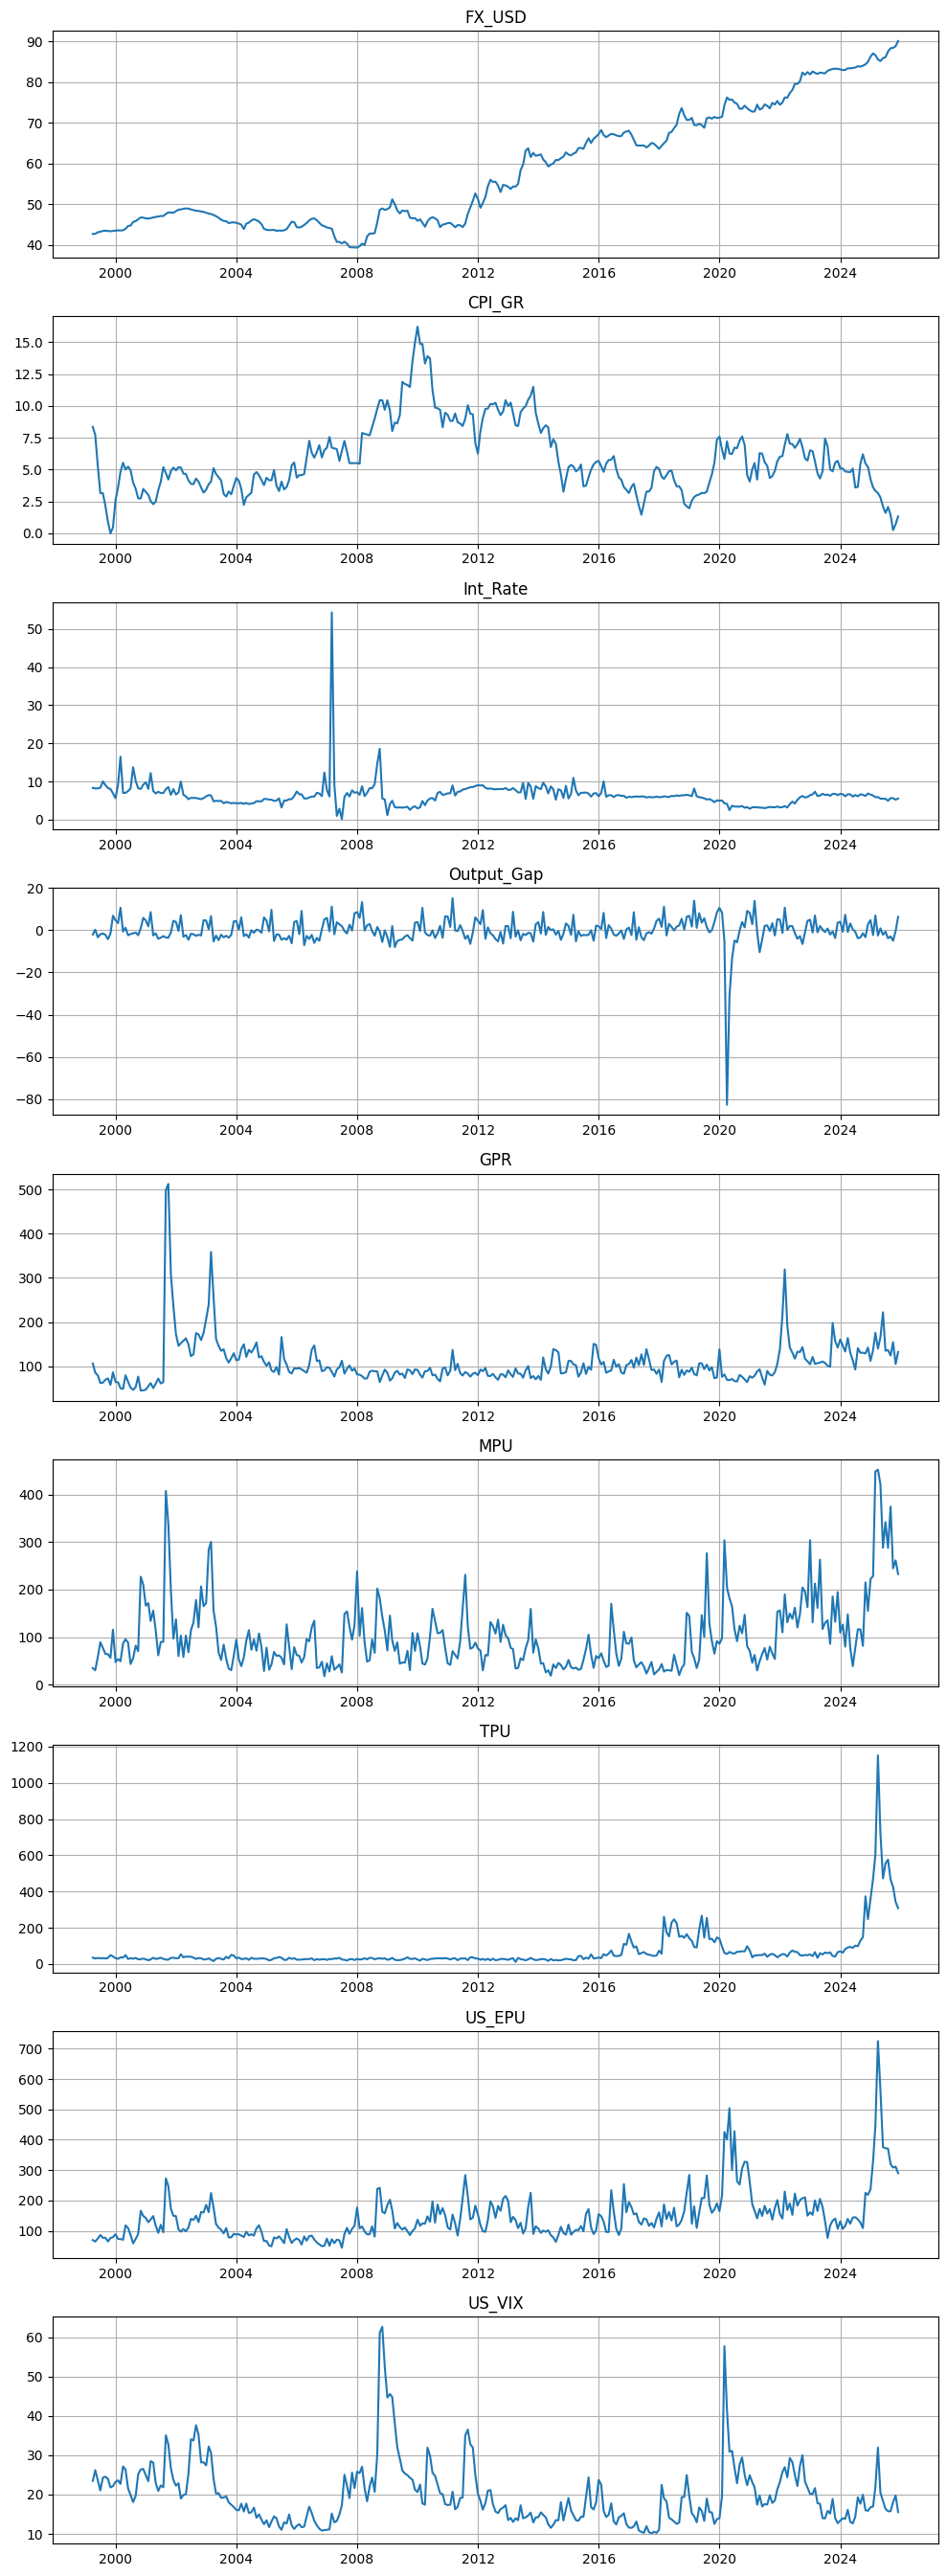

Combined multi-panel plot saved as 'all_variables_timeseries.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---------- LOAD DATA ----------
df = pd.read_excel("Compiled.xlsx")
# or: df = pd.read_csv("merged_monthly_data.csv")

# ---------- ENSURE DATE COLUMN ----------
# Change column name if your date column is different
date_col = "Date"
df[date_col] = pd.to_datetime(df[date_col])

# ---------- SET DATE AS INDEX ----------
df = df.sort_values(date_col).set_index(date_col)

# ---------- SELECT NUMERIC COLUMNS ----------
numeric_cols = df.select_dtypes(include="number").columns

# ---------- CREATE FOLDER FOR INDIVIDUAL PLOTS ----------
os.makedirs("variable_plots", exist_ok=True)

# =========================================================
# 1) INDIVIDUAL TIME-SERIES PLOTS
# =========================================================
for col in numeric_cols:
    plt.figure()
    plt.plot(df.index, df[col])
    plt.title(f"{col} Over Time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(f"variable_plots/{col}.png", dpi=300)
    plt.close()

print("Individual variable plots saved in 'variable_plots' folder.")

# =========================================================
# 2) COMBINED MULTI-PANEL FIGURE
# =========================================================
n = len(numeric_cols)

plt.figure(figsize=(10, 3 * n))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n, 1, i)
    plt.plot(df.index, df[col])
    plt.title(col)
    plt.grid(True)

plt.tight_layout()
plt.savefig("all_variables_timeseries.png", dpi=300)
plt.show()

print("Combined multi-panel plot saved as 'all_variables_timeseries.png'.")



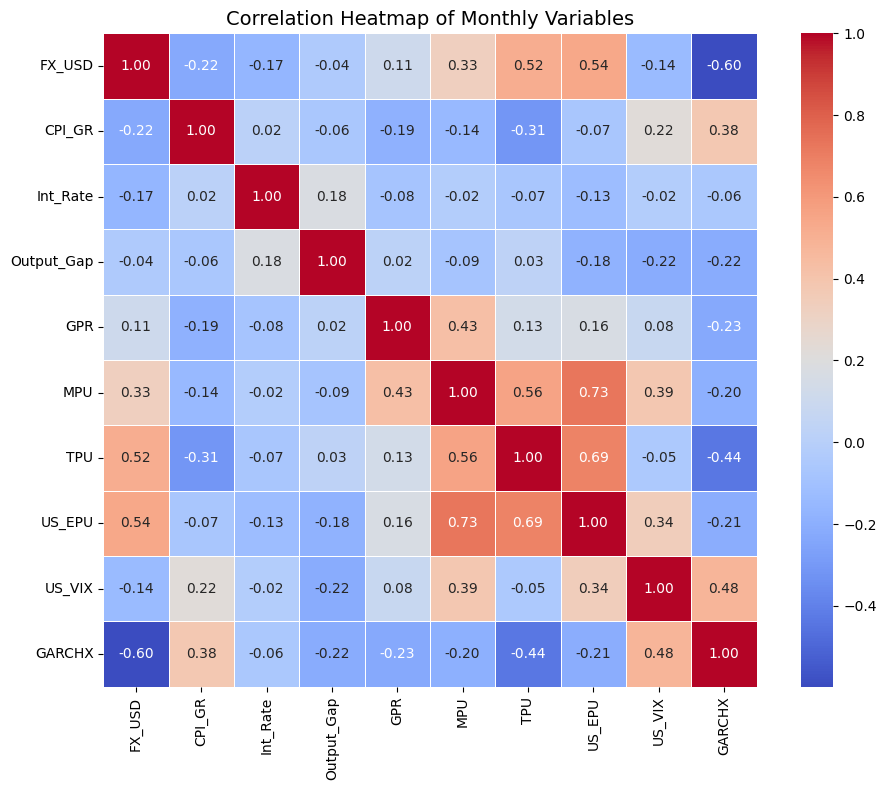

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- READ MERGED MONTHLY DATA ----------
df = pd.read_excel("Compiled.xlsx")
# or use: pd.read_csv("merged_monthly_data.csv")

# ---------- OPTIONAL: DROP DATE COLUMN ----------
# Keep only numeric variables for correlation
numeric_df = df.select_dtypes(include="number")

# ---------- COMPUTE CORRELATION MATRIX ----------
corr_matrix = numeric_df.corr()

# ---------- PLOT HEATMAP ----------
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,        # show correlation values
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Monthly Variables", fontsize=14)
plt.tight_layout()

# ---------- SAVE FIGURE ----------
plt.savefig("correlation_heatmap.png", dpi=300)

# ---------- SHOW ----------
plt.show()


GARCH (1,1)

In [ ]:
# """
# STEP 1: Plain GARCH(1,1) on NSE Returns
# Extracts conditional volatility series σ_t
# Input:  main_data.xlsx  (Date, Price, TPU, GPR)
# Output: garch_volatility.xlsx
# """

# import pandas as pd
# import numpy as np
# from scipy.optimize import minimize
# import matplotlib.pyplot as plt
# import warnings
# warnings.filterwarnings('ignore')

# # ── CONFIG ───────────────────────────────────────
# INPUT_FILE  = 'GPR_TPU.xlsx'
# OUTPUT_FILE = 'garch_volatility.xlsx'
# ANNUALIZE   = True
# # ─────────────────────────────────────────────────

# # ── Load Data ────────────────────────────────────
# df = pd.read_excel(INPUT_FILE, parse_dates=['Date'])
# df = df.sort_values('Date').set_index('Date')
# df['Returns'] = np.log(df['NSE'] / df['NSE'].shift(1)) * 100
# df = df.dropna()

# r = df['Returns'].values
# T = len(r)

# print(f"Sample: {df.index[0].date()} to {df.index[-1].date()} | N={T}")
# print(f"Returns — Mean: {r.mean():.4f}%  Std: {r.std():.4f}%")

# # ── Plain GARCH(1,1) Log-Likelihood ──────────────
# def garch_loglik(params):
#     """
#     Mean eq:     r_t = mu + e_t
#     Variance eq: s2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1}

#     No TPU/GPR here — plain GARCH(1,1)
#     params = [mu, omega, alpha, beta]
#     """
#     mu, omega, alpha, beta = params

#     if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 1:
#         return 1e10

#     e     = r - mu
#     s2    = np.zeros(T)
#     s2[0] = np.var(r)

#     for t in range(1, T):
#         s2[t] = (omega
#                  + alpha * e[t-1]**2
#                  + beta  * s2[t-1])
#         s2[t] = max(s2[t], 1e-8)

#     llh = -0.5 * np.sum(np.log(2 * np.pi * s2) + (e**2) / s2)
#     return -llh

# # ── Estimate ─────────────────────────────────────
# print("\nEstimating GARCH(1,1)...")

# result = minimize(
#     garch_loglik,
#     x0=[np.mean(r), np.var(r)*0.1, 0.1, 0.8],
#     method='L-BFGS-B',
#     bounds=[(None,None), (1e-6,None), (1e-6,0.999), (1e-6,0.999)],
#     options={'maxiter': 2000, 'ftol': 1e-12}
# )

# mu_hat, omega_hat, alpha_hat, beta_hat = result.x

# # ── Recover σ_t series ───────────────────────────
# e     = r - mu_hat
# s2    = np.zeros(T)
# s2[0] = np.var(r)

# for t in range(1, T):
#     s2[t] = (omega_hat
#              + alpha_hat * e[t-1]**2
#              + beta_hat  * s2[t-1])
#     s2[t] = max(s2[t], 1e-8)

# sigma_t = np.sqrt(s2)
# if ANNUALIZE:
#     sigma_t = sigma_t * np.sqrt(12)

# df['Cond_Vol'] = sigma_t

# # ── Print GARCH results ──────────────────────────
# loglik = -result.fun
# k      = 4
# aic    = 2*k - 2*loglik
# bic    = k*np.log(T) - 2*loglik

# print("\n" + "="*45)
# print("  GARCH(1,1) Results")
# print("="*45)
# print(f"  mu    (mean return) : {mu_hat:.6f}")
# print(f"  omega (constant)    : {omega_hat:.6f}")
# print(f"  alpha (ARCH effect) : {alpha_hat:.6f}")
# print(f"  beta  (GARCH effect): {beta_hat:.6f}")
# print(f"  alpha + beta        : {alpha_hat+beta_hat:.6f}  (persistence)")
# print(f"  AIC: {aic:.4f}  |  BIC: {bic:.4f}")
# print(f"  Log-likelihood      : {loglik:.4f}")

# # ── Save to Excel ─────────────────────────────────
# print(f"\nSaving to {OUTPUT_FILE}...")

# vol_df = df[['NSE', 'Returns', 'TPU', 'GPR', 'Cond_Vol']].copy()
# vol_df.columns = ['Price', 'Returns (%)', 'TPU', 'GPR',
#                   'GARCH_Volatility (%)']

# coef_df = pd.DataFrame({
#     'Parameter':   ['mu', 'omega', 'alpha', 'beta', 'alpha+beta'],
#     'Description': ['Mean return', 'Variance constant',
#                     'ARCH effect (shock impact)',
#                     'GARCH effect (vol persistence)',
#                     'Total persistence'],
#     'Value':       [round(x, 6) for x in
#                     [mu_hat, omega_hat, alpha_hat, beta_hat,
#                      alpha_hat+beta_hat]],
#     'Equation':    ['Mean', 'Variance', 'Variance', 'Variance', '—']
# })

# info_df = pd.DataFrame({
#     'Metric': ['Model', 'Observations', 'Log-Likelihood',
#                'AIC', 'BIC', 'Annualized'],
#     'Value':  ['GARCH(1,1)', T, round(loglik,4),
#                round(aic,4), round(bic,4), str(ANNUALIZE)]
# })

# with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
#     vol_df.reset_index().to_excel(
#         writer, sheet_name='Volatility_Series', index=False)
#     coef_df.to_excel(
#         writer, sheet_name='GARCH_Coefficients', index=False)
#     info_df.to_excel(
#         writer, sheet_name='Model_Info', index=False)

#     # Header formatting
#     from openpyxl.styles import Font, PatternFill, Alignment
#     hf = Font(bold=True, color='FFFFFF')
#     hfill = PatternFill('solid', start_color='1F4E79')
#     for sn in writer.book.sheetnames:
#         ws = writer.book[sn]
#         for cell in ws[1]:
#             cell.font = hf
#             cell.fill = hfill
#             cell.alignment = Alignment(horizontal='center')
#         for col in ws.columns:
#             w = max(len(str(c.value or '')) for c in col) + 3
#             ws.column_dimensions[col[0].column_letter].width = min(w, 35)

# print(f"  Saved: {OUTPUT_FILE}")

# # ── Plot ──────────────────────────────────────────
# fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
# fig.suptitle('GARCH(1,1) — NSE Conditional Volatility',
#              fontsize=13, fontweight='bold')

# axes[0].plot(df.index, df['Returns'], color='navy', linewidth=0.8)
# axes[0].axhline(0, color='black', linewidth=0.5, linestyle='--')
# axes[0].set_title('Monthly Log Returns (%)')
# axes[0].set_ylabel('Returns (%)')
# axes[0].grid(True, alpha=0.3)

# axes[1].plot(df.index, sigma_t, color='crimson', linewidth=1)
# axes[1].fill_between(df.index, sigma_t, alpha=0.25, color='crimson')
# axes[1].set_title('GARCH(1,1) Conditional Volatility'
#                   + (' (Annualized)' if ANNUALIZE else ' (Monthly)'))
# axes[1].set_ylabel('σ_t (%)')
# axes[1].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig('garch_volatility_plot.png', dpi=150, bbox_inches='tight')
# plt.show()
# print("  Saved: garch_volatility_plot.png\n")
# print("→ Now use 'GARCH_Volatility (%)' column in Step 2 regression.")

**GARCH-X**

  GARCH-X Estimation
  Sample : 1999-05-01 to 2025-12-01
  N      : 320 monthly observations
  Returns: mean=1.0266%  std=6.2863%

  Estimating GARCH-X via Maximum Likelihood...
  Parameters: mu, beta1, beta2, omega, alpha, beta, delta1, delta2
  ✓ Converged successfully
  Computing standard errors (numerical Hessian)...

  GARCH-X(1,1) — Full Results
  Mean eq:  r_t = mu + beta1*TPU + beta2*GPR + e_t
  Var  eq:  s2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1}
                   + delta1*TPU_t + delta2*GPR_t
  Parameter                          Coef         SE   t-stat    p-val  Sig
----------------------------------------------------------------------
  [Mean    ] mu                       1.276765   0.735001    1.737   0.0824    *
  [Mean    ] beta1  (TPU → mean)      0.000037   0.001604    0.023   0.9815   ns
  [Mean    ] beta2  (GPR → mean)     -0.002420   0.006023   -0.402   0.6879   ns
  [Variance] omega                    4.259747   2.044908    2.083   0.0372   **
  [Variance] alph

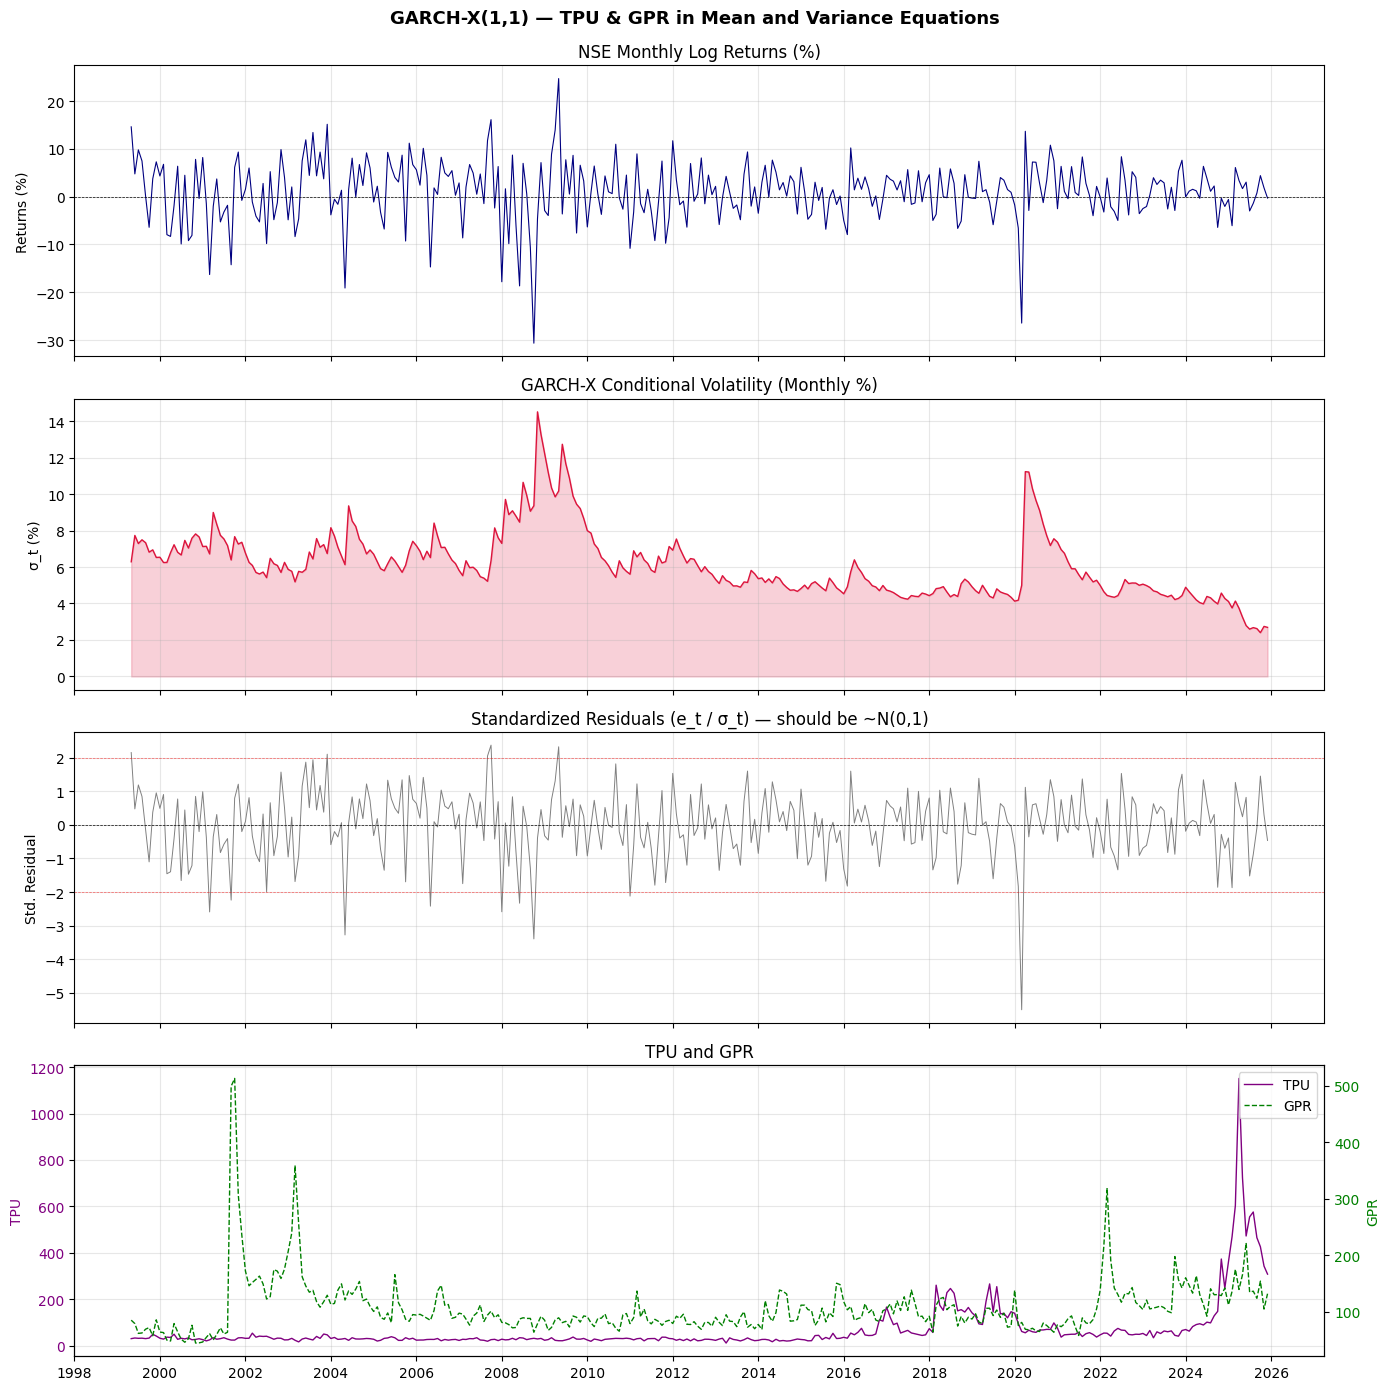

  Saved: garch_x_plot.png

  Done! Check garch_x_results.xlsx


In [ ]:
"""
GARCH-X: TPU and GPR in BOTH Mean and Variance Equations
=========================================================

Mean equation:
    r_t = mu + beta1*TPU_t + beta2*GPR_t + e_t

Variance equation:
    s2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1}
           + delta1*TPU_t + delta2*GPR_t

All 8 parameters estimated simultaneously via MLE.
e_t from the mean equation feeds directly into the variance equation.

Input:  main_data.xlsx  (columns: Date, Price, TPU, GPR)
Output: garch_x_results.xlsx + garch_x_plot.png
"""

import pandas as pd
import numpy as np
from scipy.optimize import minimize
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from openpyxl.styles import Font, PatternFill, Alignment
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ───────────────────────────────────────────────────
INPUT_FILE  = 'GPR_TPU.xlsx'
OUTPUT_FILE = 'garch_x_results.xlsx'
ANNUALIZE   = False   # multiply vol by sqrt(12) for annualized
# ─────────────────────────────────────────────────────────────


# ════════════════════════════════════════════════════════════
# 1. LOAD AND PREPARE DATA
# ════════════════════════════════════════════════════════════
df = pd.read_excel(INPUT_FILE, parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')
df['Returns'] = np.log(df['NSE'] / df['NSE'].shift(1)) * 100
df = df.dropna(subset=['Returns', 'TPU', 'GPR'])

r   = df['Returns'].values
tpu = df['TPU'].values
gpr = df['GPR'].values
T   = len(r)

print("=" * 60)
print("  GARCH-X Estimation")
print("=" * 60)
print(f"  Sample : {df.index[0].date()} to {df.index[-1].date()}")
print(f"  N      : {T} monthly observations")
print(f"  Returns: mean={r.mean():.4f}%  std={r.std():.4f}%")


# ════════════════════════════════════════════════════════════
# 2. GARCH-X LOG-LIKELIHOOD
# ════════════════════════════════════════════════════════════
def garch_x_loglik(params):
    """
    Negative log-likelihood for GARCH-X model.

    params = [mu, beta1, beta2, omega, alpha, beta, delta1, delta2]

    Mean eq  :  r_t = mu + beta1*TPU_t + beta2*GPR_t + e_t
    Var eq   :  s2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1}
                       + delta1*TPU_t + delta2*GPR_t

    e_t (residual from mean eq) is the BRIDGE into variance eq.
    All parameters optimized simultaneously.
    """
    mu, beta1, beta2, omega, alpha, beta, delta1, delta2 = params

    # Stationarity and positivity constraints
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 1:
        return 1e10

    # ── Mean equation: extract residuals ──────────
    e = r - mu - beta1 * tpu - beta2 * gpr

    # ── Variance equation ─────────────────────────
    s2    = np.zeros(T)
    s2[0] = np.var(r)          # initialize at unconditional variance

    for t in range(1, T):
        s2[t] = (omega
                 + alpha  * e[t-1]**2    # ARCH: yesterday's shock²
                 + beta   * s2[t-1]      # GARCH: yesterday's variance
                 + delta1 * tpu[t]       # TPU directly in variance
                 + delta2 * gpr[t])      # GPR directly in variance

        # Safety clamp — prevent negative variance
        if s2[t] <= 0:
            return 1e10

    # ── Gaussian log-likelihood ───────────────────
    # Uses BOTH e_t (mean eq) and s2_t (variance eq)
    llh = -0.5 * np.sum(np.log(2 * np.pi * s2) + (e**2) / s2)
    return -llh   # minimize negative = maximize likelihood


# ════════════════════════════════════════════════════════════
# 3. ESTIMATE VIA MLE — ALL 8 PARAMETERS SIMULTANEOUSLY
# ════════════════════════════════════════════════════════════
print("\n  Estimating GARCH-X via Maximum Likelihood...")
print("  Parameters: mu, beta1, beta2, omega, alpha, beta, delta1, delta2")

# Starting values
init = [
    np.mean(r),        # mu
    0.01,              # beta1 (TPU → mean)
    0.01,              # beta2 (GPR → mean)
    np.var(r) * 0.1,   # omega
    0.10,              # alpha (ARCH)
    0.80,              # beta  (GARCH)
    0.01,              # delta1 (TPU → variance)
    0.01,              # delta2 (GPR → variance)
]

# Parameter bounds
bounds = [
    (None,  None),     # mu      : unrestricted
    (None,  None),     # beta1   : unrestricted (can be negative)
    (None,  None),     # beta2   : unrestricted
    (1e-6,  None),     # omega   : must be positive
    (1e-6,  0.999),    # alpha   : (0, 1)
    (1e-6,  0.999),    # beta    : (0, 1)
    (None,  None),     # delta1  : unrestricted
    (None,  None),     # delta2  : unrestricted
]

result = minimize(
    garch_x_loglik,
    init,
    method='L-BFGS-B',
    bounds=bounds,
    options={'maxiter': 5000, 'ftol': 1e-14, 'gtol': 1e-8}
)

if not result.success:
    print(f"  ⚠ Optimizer warning: {result.message}")
else:
    print("  ✓ Converged successfully")

mu_h, b1_h, b2_h, omega_h, alpha_h, beta_h, d1_h, d2_h = result.x


# ════════════════════════════════════════════════════════════
# 4. RECOVER CONDITIONAL VARIANCE SERIES
# ════════════════════════════════════════════════════════════
e     = r - mu_h - b1_h * tpu - b2_h * gpr
s2    = np.zeros(T)
s2[0] = np.var(r)

for t in range(1, T):
    s2[t] = (omega_h
             + alpha_h * e[t-1]**2
             + beta_h  * s2[t-1]
             + d1_h    * tpu[t]
             + d2_h    * gpr[t])
    s2[t] = max(s2[t], 1e-8)

sigma_t = np.sqrt(s2)
if ANNUALIZE:
    sigma_t_out = sigma_t * np.sqrt(12)
else:
    sigma_t_out = sigma_t

df['Residuals']   = e
df['Cond_Var']    = s2
df['Cond_Vol']    = sigma_t_out


# ════════════════════════════════════════════════════════════
# 5. STANDARD ERRORS VIA NUMERICAL HESSIAN
# ════════════════════════════════════════════════════════════
def num_hessian(f, x, eps=1e-5):
    n = len(x)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei, ej = np.zeros(n), np.zeros(n)
            ei[i] = eps; ej[j] = eps
            H[i,j] = (f(x+ei+ej) - f(x+ei-ej)
                     - f(x-ei+ej) + f(x-ei-ej)) / (4 * eps**2)
    return H

print("  Computing standard errors (numerical Hessian)...")
try:
    H   = num_hessian(garch_x_loglik, result.x)
    cov = np.linalg.inv(H)
    se  = np.sqrt(np.abs(np.diag(cov)))
except Exception:
    se = np.full(8, np.nan)
    print("  ⚠ Could not compute standard errors")

params_hat = result.x
t_stats    = params_hat / se
p_values   = 2 * (1 - stats.norm.cdf(np.abs(t_stats)))
ci_lower   = params_hat - 1.96 * se
ci_upper   = params_hat + 1.96 * se


# ════════════════════════════════════════════════════════════
# 6. PRINT RESULTS
# ════════════════════════════════════════════════════════════
loglik = -result.fun
k      = 8
aic    = 2 * k - 2 * loglik
bic    = k * np.log(T) - 2 * loglik

def stars(p):
    if np.isnan(p): return ''
    return '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.10 else 'ns'))

param_names = [
    'mu',
    'beta1  (TPU → mean)',
    'beta2  (GPR → mean)',
    'omega',
    'alpha  (ARCH)',
    'beta   (GARCH)',
    'delta1 (TPU → variance)',
    'delta2 (GPR → variance)',
]

equations = [
    'Mean', 'Mean', 'Mean',
    'Variance', 'Variance', 'Variance', 'Variance', 'Variance'
]

print("\n" + "=" * 70)
print("  GARCH-X(1,1) — Full Results")
print("  Mean eq:  r_t = mu + beta1*TPU + beta2*GPR + e_t")
print("  Var  eq:  s2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1}")
print("                   + delta1*TPU_t + delta2*GPR_t")
print("=" * 70)
print(f"  {'Parameter':<28} {'Coef':>10} {'SE':>10} {'t-stat':>8} {'p-val':>8} {'Sig':>4}")
print("-" * 70)
for nm, eq, co, s, t, p in zip(param_names, equations,
                                 params_hat, se, t_stats, p_values):
    print(f"  [{eq:<8}] {nm:<22} {co:>10.6f} {s:>10.6f} "
          f"{t:>8.3f} {p:>8.4f} {stars(p):>4}")

print(f"\n  alpha + beta (persistence) : {alpha_h + beta_h:.6f}"
      + (" ✓ stationary" if alpha_h+beta_h < 1 else " ⚠ non-stationary"))
print(f"  Log-likelihood             : {loglik:.4f}")
print(f"  AIC                        : {aic:.4f}")
print(f"  BIC                        : {bic:.4f}")
print(f"  Annualized volatility      : {str(ANNUALIZE)}")


# ════════════════════════════════════════════════════════════
# 7. DIAGNOSTICS ON STANDARDIZED RESIDUALS
# ════════════════════════════════════════════════════════════
std_resid = e / sigma_t   # standardized residuals

from statsmodels.stats.diagnostic import acorr_ljungbox
lb_r  = acorr_ljungbox(std_resid,    lags=[5, 10], return_df=True)
lb_r2 = acorr_ljungbox(std_resid**2, lags=[5, 10], return_df=True)

print("\n  Diagnostics (standardized residuals):")
print(f"  Ljung-Box residuals   lag5,10 p: "
      f"{lb_r['lb_pvalue'].values[0]:.3f}, {lb_r['lb_pvalue'].values[1]:.3f}"
      f"  → want > 0.05")
print(f"  Ljung-Box residuals²  lag5,10 p: "
      f"{lb_r2['lb_pvalue'].values[0]:.3f}, {lb_r2['lb_pvalue'].values[1]:.3f}"
      f"  → want > 0.05")


# ════════════════════════════════════════════════════════════
# 8. SAVE TO EXCEL
# ════════════════════════════════════════════════════════════
print(f"\n  Saving to {OUTPUT_FILE}...")

# Sheet 1: Full time series
vol_series = df[['NSE', 'Returns', 'TPU', 'GPR',
                  'Residuals', 'Cond_Var', 'Cond_Vol']].copy()
vol_series.columns = [
    'NSE', 'Returns (%)', 'TPU', 'GPR',
    'Residual_e_t',
    'Conditional_Variance (s2_t)',
    f'Conditional_Vol_%{"_annualized" if ANNUALIZE else "_monthly"}'
]

# Sheet 2: Coefficient table
coef_df = pd.DataFrame({
    'Equation':    equations,
    'Parameter':   param_names,
    'Coefficient': params_hat.round(8),
    'Std_Error':   se.round(8),
    'T_Statistic': t_stats.round(4),
    'P_Value':     p_values.round(4),
    'Significance':[stars(p) for p in p_values],
    'CI_Lower_95': ci_lower.round(8),
    'CI_Upper_95': ci_upper.round(8),
})

# Sheet 3: Model info
info_df = pd.DataFrame({
    'Metric': [
        'Model', 'Mean Equation', 'Variance Equation',
        'Estimation', 'Distribution', 'Observations',
        'Log-Likelihood', 'AIC', 'BIC',
        'alpha+beta (persistence)', 'Stationarity', 'Annualized'
    ],
    'Value': [
        'GARCH-X(1,1)',
        'r_t = mu + beta1*TPU + beta2*GPR + e_t',
        's2_t = omega + alpha*e2_{t-1} + beta*s2_{t-1} + delta1*TPU + delta2*GPR',
        'MLE (L-BFGS-B)',
        'Gaussian',
        T,
        round(loglik, 4),
        round(aic, 4),
        round(bic, 4),
        round(alpha_h + beta_h, 6),
        'Yes' if alpha_h + beta_h < 1 else 'No — check model',
        str(ANNUALIZE)
    ]
})

# Sheet 4: Diagnostics
diag_df = pd.DataFrame({
    'Test': [
        'Ljung-Box residuals (lag 5)',
        'Ljung-Box residuals (lag 10)',
        'Ljung-Box residuals² (lag 5)',
        'Ljung-Box residuals² (lag 10)',
    ],
    'P_Value': [
        round(lb_r['lb_pvalue'].values[0], 4),
        round(lb_r['lb_pvalue'].values[1], 4),
        round(lb_r2['lb_pvalue'].values[0], 4),
        round(lb_r2['lb_pvalue'].values[1], 4),
    ],
    'Interpretation': [
        'No autocorrelation in residuals' if lb_r['lb_pvalue'].values[0]>0.05
            else 'Autocorrelation present',
        'No autocorrelation in residuals' if lb_r['lb_pvalue'].values[1]>0.05
            else 'Autocorrelation present',
        'No ARCH effects remaining' if lb_r2['lb_pvalue'].values[0]>0.05
            else 'Remaining ARCH effects',
        'No ARCH effects remaining' if lb_r2['lb_pvalue'].values[1]>0.05
            else 'Remaining ARCH effects',
    ]
})

# Write all sheets
with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    vol_series.reset_index().to_excel(
        writer, sheet_name='Volatility_Series', index=False)
    coef_df.to_excel(
        writer, sheet_name='Coefficients', index=False)
    info_df.to_excel(
        writer, sheet_name='Model_Info', index=False)
    diag_df.to_excel(
        writer, sheet_name='Diagnostics', index=False)

    # Formatting
    hf    = Font(bold=True, color='FFFFFF')
    hfill = PatternFill('solid', start_color='1F4E79')
    sfill = PatternFill('solid', start_color='D9E1F2')  # light blue for var eq rows

    wb = writer.book
    for sn in wb.sheetnames:
        ws = wb[sn]
        # Header row
        for cell in ws[1]:
            cell.font      = hf
            cell.fill      = hfill
            cell.alignment = Alignment(horizontal='center')
        # Column widths
        for col in ws.columns:
            w = max(len(str(c.value or '')) for c in col) + 3
            ws.column_dimensions[col[0].column_letter].width = min(w, 45)

    # Highlight variance equation rows in coefficients sheet
    ws_coef = wb['Coefficients']
    for row in ws_coef.iter_rows(min_row=2):
        if row[0].value == 'Variance':
            for cell in row:
                cell.fill = sfill

print(f"  Saved: {OUTPUT_FILE}")


# ════════════════════════════════════════════════════════════
# 9. PLOT
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle('GARCH-X(1,1) — TPU & GPR in Mean and Variance Equations',
             fontsize=13, fontweight='bold', y=0.99)

# Panel 1: Returns
axes[0].plot(df.index, r, color='navy', linewidth=0.8)
axes[0].axhline(0, color='black', linewidth=0.5, linestyle='--')
axes[0].set_title('NSE Monthly Log Returns (%)')
axes[0].set_ylabel('Returns (%)')
axes[0].grid(True, alpha=0.3)

# Panel 2: Conditional Volatility
axes[1].plot(df.index, sigma_t_out, color='crimson', linewidth=1)
axes[1].fill_between(df.index, sigma_t_out, alpha=0.2, color='crimson')
axes[1].set_title(f'GARCH-X Conditional Volatility'
                  f' ({"Annualized" if ANNUALIZE else "Monthly"} %)')
axes[1].set_ylabel('σ_t (%)')
axes[1].grid(True, alpha=0.3)

# Panel 3: Standardized Residuals
axes[2].plot(df.index, std_resid, color='grey', linewidth=0.7)
axes[2].axhline(0,  color='black', linewidth=0.5, linestyle='--')
axes[2].axhline(2,  color='red',   linewidth=0.5, linestyle='--', alpha=0.6)
axes[2].axhline(-2, color='red',   linewidth=0.5, linestyle='--', alpha=0.6)
axes[2].set_title('Standardized Residuals (e_t / σ_t) — should be ~N(0,1)')
axes[2].set_ylabel('Std. Residual')
axes[2].grid(True, alpha=0.3)

# Panel 4: TPU and GPR
ax4b = axes[3].twinx()
axes[3].plot(df.index, tpu, color='purple', linewidth=1, label='TPU')
ax4b.plot(df.index,    gpr, color='green',  linewidth=1,
          label='GPR', linestyle='--')
axes[3].set_title('TPU and GPR')
axes[3].set_ylabel('TPU', color='purple')
ax4b.set_ylabel('GPR', color='green')
axes[3].tick_params(axis='y', labelcolor='purple')
ax4b.tick_params(axis='y', labelcolor='green')
l1, lb1 = axes[3].get_legend_handles_labels()
l2, lb2 = ax4b.get_legend_handles_labels()
axes[3].legend(l1+l2, lb1+lb2, loc='upper right')
axes[3].grid(True, alpha=0.3)
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[3].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('garch_x_plot.png', dpi=150, bbox_inches='tight')
plt.show()6
print("  Saved: garch_x_plot.png")
print("\n  Done! Check garch_x_results.xlsx")

**Rolling** **Volatility**

In [ ]:
"""
12-Month Rolling Volatility — Monthly NSE Closing Prices
=========================================================
Formula : σ_annual = std(monthly log returns over 12M window) × √12
Input   : NSE Excel file with Date + Close columns (monthly frequency)
Output  : nse_monthly_rolling_vol.xlsx + nse_monthly_vol_plot.png
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
import os, sys

# ════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ════════════════════════════════════════════════════════════
INPUT_FILE = 'Compiled.xlsx'   # <-- change to your filename

if not os.path.exists(INPUT_FILE):
    print(f"ERROR: '{INPUT_FILE}' not found.")
    sys.exit(1)

df = pd.read_excel(INPUT_FILE)
print(f"Columns found: {df.columns.tolist()}")

# Auto-detect Date and Close columns
date_col  = next((c for c in df.columns if 'date' in c.lower()), None)
close_col = next((c for c in df.columns
                  if any(x in c.lower() for x in ['close', 'price', 'adj'])), None)

if not date_col:
    raise ValueError("No Date column found. Rename your date column to 'Date'.")
if not close_col:
    raise ValueError("No Close/Price column found. Rename it to 'Close'.")

print(f"Date column  : '{date_col}'")
print(f"Price column : '{close_col}'")

df = df[[date_col, close_col]].rename(columns={date_col: 'Date', close_col: 'Close'})
df['Date']  = pd.to_datetime(df['Date'], errors='coerce')
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
df = df.dropna().sort_values('Date').reset_index(drop=True)

print(f"Sample : {df['Date'].min().date()} → {df['Date'].max().date()}")
print(f"N      : {len(df)} monthly observations")

# ════════════════════════════════════════════════════════════
# 2. COMPUTE VOLATILITY
# ════════════════════════════════════════════════════════════
WINDOW = 12   # months

# Monthly log returns
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# 12-month rolling std of log returns (raw monthly vol)
df['Rolling_Std_12M'] = df['Log_Return'].rolling(window=WINDOW).std()

# Annualised by ×√12 (since data is monthly)
df['Rolling_Vol_Ann'] = df['Rolling_Std_12M'] * np.sqrt(12)

# Express annualised as percentage
df['Rolling_Vol_Ann_Pct'] = df['Rolling_Vol_Ann'] * 100

print(f"\n12-Month Rolling Volatility — Raw Monthly Std:")
print(df['Rolling_Std_12M'].describe().round(6))
print(f"\n12-Month Rolling Volatility — Annualised (×√12):")
print(df['Rolling_Vol_Ann'].describe().round(6))
print(f"\nAnnualised as %:")
print(df['Rolling_Vol_Ann_Pct'].describe().round(2))

# ════════════════════════════════════════════════════════════
# 3. PLOT
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)
fig.suptitle('NSE — 12-Month Rolling Volatility (Monthly Close Prices)',
             fontsize=13, fontweight='bold')

# Panel 1: Closing price
axes[0].plot(df['Date'], df['Close'], color='navy', linewidth=1)
axes[0].set_title('Monthly Closing Price')
axes[0].set_ylabel('Price')
axes[0].grid(True, alpha=0.3)

# Panel 2: Raw monthly std
axes[1].plot(df['Date'], df['Rolling_Std_12M'],
             color='crimson', linewidth=1, label='12M Rolling Std (monthly)')
axes[1].fill_between(df['Date'], 0, df['Rolling_Std_12M'].fillna(0),
                     color='crimson', alpha=0.15)
mean_raw = df['Rolling_Std_12M'].mean()
axes[1].axhline(mean_raw, color='grey', linewidth=1, linestyle='--',
                label=f'Mean = {mean_raw:.4f}')
axes[1].set_title('Raw Monthly Std Dev of Log Returns (12-Month Window)')
axes[1].set_ylabel('σ monthly (raw)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Annualised vol %
axes[2].plot(df['Date'], df['Rolling_Vol_Ann_Pct'],
             color='darkorange', linewidth=1, label='Annualised Vol (×√12)')
axes[2].fill_between(df['Date'], 0, df['Rolling_Vol_Ann_Pct'].fillna(0),
                     color='darkorange', alpha=0.15)
mean_ann = df['Rolling_Vol_Ann_Pct'].mean()
axes[2].axhline(mean_ann, color='grey', linewidth=1, linestyle='--',
                label=f'Mean = {mean_ann:.2f}%')
axes[2].set_title('Annualised Volatility % (Raw Std × √12 × 100)')
axes[2].set_ylabel('Annualised Vol (%)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('nse_monthly_vol_plot.png', dpi=150, bbox_inches='tight')
plt.close()
print("\nPlot saved: nse_monthly_vol_plot.png")

# ════════════════════════════════════════════════════════════
# 4. SUMMARY STATS
# ════════════════════════════════════════════════════════════
def build_summary(series, label):
    s    = series.dropna()
    desc = s.describe()
    pcts = np.percentile(s, [10, 25, 50, 75, 90])
    rows = list(desc.items()) + [
        ('10th Pct', pcts[0]), ('25th Pct', pcts[1]),
        ('50th Pct', pcts[2]), ('75th Pct', pcts[3]),
        ('90th Pct', pcts[4]),
    ]
    return pd.DataFrame({'Statistic': [r[0] for r in rows],
                         label:       [round(r[1], 6) for r in rows]})

raw_sum = build_summary(df['Rolling_Std_12M'],    'Raw Monthly Std')
ann_sum = build_summary(df['Rolling_Vol_Ann'],     'Annualised (x√12)')
pct_sum = build_summary(df['Rolling_Vol_Ann_Pct'], 'Annualised (%)')
summary = raw_sum.merge(ann_sum, on='Statistic').merge(pct_sum, on='Statistic')

# ════════════════════════════════════════════════════════════
# 5. EXPORT TO EXCEL
# ════════════════════════════════════════════════════════════
OUTPUT = 'nse_monthly_rolling_vol.xlsx'

out_df = df[['Date', 'Close', 'Log_Return',
             'Rolling_Std_12M', 'Rolling_Vol_Ann', 'Rolling_Vol_Ann_Pct']].copy()
out_df.columns = ['Date', 'Close (Monthly)', 'Log Return',
                  'Rolling Std 12M (raw)', 'Annualised Vol (x√12)',
                  'Annualised Vol (%)']

with pd.ExcelWriter(OUTPUT, engine='openpyxl') as writer:
    out_df.to_excel(writer,  sheet_name='Rolling_Volatility', index=False)
    summary.to_excel(writer, sheet_name='Summary_Stats',      index=False)

# ════════════════════════════════════════════════════════════
# 6. FORMAT EXCEL
# ════════════════════════════════════════════════════════════
wb  = load_workbook(OUTPUT)
HDR_FONT  = Font(bold=True, color='FFFFFF', name='Arial', size=10)
HDR_FILL  = PatternFill('solid', start_color='1F4E79')
HDR_ALIGN = Alignment(horizontal='center', vertical='center')
THIN      = Side(style='thin', color='CCCCCC')
BRD       = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
ALT_FILL  = PatternFill('solid', start_color='EBF3FB')

for sname in wb.sheetnames:
    ws = wb[sname]

    for cell in ws[1]:
        cell.font = HDR_FONT; cell.fill = HDR_FILL
        cell.alignment = HDR_ALIGN; cell.border = BRD

    for i, row in enumerate(ws.iter_rows(min_row=2), start=2):
        for cell in row:
            cell.border = BRD
            cell.font   = Font(name='Arial', size=10)
            if isinstance(cell.value, float):
                cell.number_format = '0.0000'
                cell.alignment     = Alignment(horizontal='right')
            if i % 2 == 0:
                cell.fill = ALT_FILL

    if sname == 'Rolling_Volatility':
        for cell in ws['A'][1:]:
            if cell.row > 1:
                cell.number_format = 'MMM-YYYY'
                cell.alignment     = Alignment(horizontal='left')
        # Percentage column formatting
        pct_col = 6
        for cell in ws.iter_rows(min_row=2, min_col=pct_col, max_col=pct_col):
            for c in cell:
                if isinstance(c.value, float):
                    c.number_format = '0.00"%"'

    for col in ws.columns:
        max_len = max((len(str(c.value or '')) for c in col), default=8)
        ws.column_dimensions[get_column_letter(col[0].column)].width = min(max_len + 4, 30)

    ws.freeze_panes = 'A2'
    ws.row_dimensions[1].height = 20

wb.save(OUTPUT)
print(f"Saved : {OUTPUT}")
print("\nDone! Outputs:")
print(f"  • {OUTPUT}")
print(f"  • nse_monthly_vol_plot.png")
print(f"\nNote: First 12 rows will have NaN volatility (window warm-up period).")

Columns found: ['Date', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Close']
Date column  : 'Date'
Price column : 'Close'
Sample : 1999-04-01 → 2025-11-01
N      : 320 monthly observations

12-Month Rolling Volatility — Raw Monthly Std:
count    308.000000
mean       0.057999
std        0.024521
min        0.027178
25%        0.038888
50%        0.050646
75%        0.070378
max        0.148533
Name: Rolling_Std_12M, dtype: float64

12-Month Rolling Volatility — Annualised (×√12):
count    308.000000
mean       0.200916
std        0.084943
min        0.094148
25%        0.134710
50%        0.175445
75%        0.243797
max        0.514533
Name: Rolling_Vol_Ann, dtype: float64

Annualised as %:
count    308.00
mean      20.09
std        8.49
min        9.41
25%       13.47
50%       17.54
75%       24.38
max       51.45
Name: Rolling_Vol_Ann_Pct, dtype: float64

Plot saved: nse_monthly_vol_plot.png
Saved : nse_monthly_rolling_vol.xlsx

Done! Outp

**Stationarity**

In [ ]:
import pandas as pd
import numpy as np
from arch.unitroot import PhillipsPerron
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import zivot_andrews
import warnings
warnings.filterwarnings('ignore')

# ── LOAD DATA ────────────────────────────────────────────────
df = pd.read_excel('Compiled.xlsx', sheet_name='X_var',parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')

# ── VARIABLES TO TEST ────────────────────────────────────────
variables = ['TPU', 'GPR', 'Annualised Vol (x√12)',
             'FX_USD', 'CPI_GR', 'Int_Rate',
             'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

decomp = seasonal_decompose(df['CPI_GR'].dropna(), model='additive', period=12)
df['CPI_GR_SA'] = df['CPI_GR'] - decomp.seasonal

za_result = zivot_andrews(df['CPI_GR'].dropna(), trim=0.15)
print(f"ZA stat: {za_result[0]:.4f}, p-value: {za_result[1]:.4f}, break at: {za_result[4]}")
# ── TEST FUNCTION ─────────────────────────────────────────────
def stationarity_tests(series, name):
    s = series.dropna()

    # ── ADF: H0 = unit root ──────────────────────────────────
    # adf_stat, adf_p, adf_lags, _, adf_cv, _ = adfuller(s, autolag='AIC')
    adf_stat, adf_p, adf_lags, _, adf_cv, _ = adfuller(s, maxlag=12, autolag='AIC')
    adf_concl = 'Stationary' if adf_p < 0.05 else 'Non-Stationary'

    # ── PP: H0 = unit root ───────────────────────────────────
    pp_result = PhillipsPerron(s)
    pp_stat   = pp_result.stat
    pp_p      = pp_result.pvalue
    pp_concl  = 'Stationary' if pp_p < 0.05 else 'Non-Stationary'

    # ── KPSS: H0 = stationary ────────────────────────────────
    kpss_stat, kpss_p, kpss_lags, kpss_cv = kpss(s, regression='c', nlags='auto')
    kpss_concl = 'Non-Stationary' if kpss_p < 0.05 else 'Stationary'

    # ── COMBINED VERDICT ─────────────────────────────────────
    stationary_votes = sum([
        adf_concl  == 'Stationary',
        pp_concl   == 'Stationary',
        kpss_concl == 'Stationary',
    ])

    if stationary_votes == 3:
        verdict = '✓ Stationary'
    elif stationary_votes == 0:
        verdict = '✗ Non-Stationary'
    else:
        verdict = '? Inconclusive'

    return {
        'Variable'        : name,
        # ADF
        'ADF Stat'        : round(adf_stat,  4),
        'ADF p-value'     : round(adf_p,     4),
        'ADF Lags'        : adf_lags,
        'ADF Conclusion'  : adf_concl,
        # PP
        'PP Stat'         : round(pp_stat,   4),
        'PP p-value'      : round(pp_p,      4),
        'PP Conclusion'   : pp_concl,
        # KPSS
        'KPSS Stat'       : round(kpss_stat, 4),
        'KPSS p-value'    : round(kpss_p,    4),
        'KPSS Lags'       : kpss_lags,
        'KPSS Conclusion' : kpss_concl,
        # Final
        'Verdict'         : verdict,
    }

# ── RUN TESTS ────────────────────────────────────────────────
results = []
for var in variables:
    if var in df.columns:
        results.append(stationarity_tests(df[var], var))
    else:
        print(f"  ⚠ '{var}' not found in dataframe — skipping")

results_df = pd.DataFrame(results)

# ── PRINT ─────────────────────────────────────────────────────
print("=" * 100)
print("  STATIONARITY TEST RESULTS")
print("  ADF  — H0: Non-Stationary  → p < 0.05 = Stationary")
print("  PP   — H0: Non-Stationary  → p < 0.05 = Stationary")
print("  KPSS — H0: Stationary      → p < 0.05 = Non-Stationary")
print("  Verdict: ✓ = all 3 agree stationary | ✗ = all 3 agree non-stationary | ? = mixed")
print("=" * 100)

# Print in sections for readability
display_cols = ['Variable',
                'ADF Stat', 'ADF p-value', 'ADF Conclusion',
                'PP Stat',  'PP p-value',  'PP Conclusion',
                'KPSS Stat','KPSS p-value','KPSS Conclusion',
                'Verdict']
print(results_df[display_cols].to_string(index=False))

# ── CLASSIFY ──────────────────────────────────────────────────
non_stationary = results_df[results_df['Verdict'] == '✗ Non-Stationary']['Variable'].tolist()
inconclusive   = results_df[results_df['Verdict'] == '? Inconclusive']['Variable'].tolist()
stationary     = results_df[results_df['Verdict'] == '✓ Stationary']['Variable'].tolist()

print(f"\n  ✓ Stationary     : {stationary}")
print(f"  ✗ Non-Stationary : {non_stationary}")
print(f"  ? Inconclusive   : {inconclusive}")

# ── SAVE ──────────────────────────────────────────────────────
results_df.to_excel('stationarity_results.xlsx', index=False)
print("\n  Saved: stationarity_results.xlsx")

ZA stat: -3.1794, p-value: 0.8495, break at: 105
  ⚠ 'Annualised Vol (x√12)' not found in dataframe — skipping
  STATIONARITY TEST RESULTS
  ADF  — H0: Non-Stationary  → p < 0.05 = Stationary
  PP   — H0: Non-Stationary  → p < 0.05 = Stationary
  KPSS — H0: Stationary      → p < 0.05 = Non-Stationary
  Verdict: ✓ = all 3 agree stationary | ✗ = all 3 agree non-stationary | ? = mixed
  Variable  ADF Stat  ADF p-value ADF Conclusion  PP Stat  PP p-value  PP Conclusion  KPSS Stat  KPSS p-value KPSS Conclusion          Verdict
       TPU    0.3981       0.9814 Non-Stationary  -3.9891      0.0015     Stationary     0.9377        0.0100  Non-Stationary   ? Inconclusive
       GPR   -6.0166       0.0000     Stationary  -7.1378      0.0000     Stationary     0.2077        0.1000      Stationary     ✓ Stationary
    FX_USD    0.6645       0.9891 Non-Stationary   0.9734      0.9940 Non-Stationary     2.5381        0.0100  Non-Stationary ✗ Non-Stationary
    CPI_GR   -1.1260       0.7046 Non-Stati

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')

# ── PASTE YOUR NON-STATIONARY LIST FROM SNIPPET 1 ────────────
# OR re-run snippet 1 first and use non_stationary directly
# non_stationary = ['FX_USD', 'CPI_GR', ...]   # ← manual override if needed

df = pd.read_excel('Compiled0.xlsx', sheet_name='X_var (2)', parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')

variables = ['FX_USD','Conditional_Vol_%_monthly']

# ── HELPER ───────────────────────────────────────────────────
def is_stationary(series):
    s = series.dropna()
    if len(s) < 10:
        return False
    adf_p  = adfuller(s, autolag='AIC')[1]
    kpss_p = kpss(s, regression='c', nlags='auto')[1]
    return adf_p < 0.05 and kpss_p >= 0.05

# ── STATIONARISE ─────────────────────────────────────────────
df_stationary = df[variables].copy()
transform_log  = {}   # tracks what transformation was applied

for var in variables:
    if var not in df.columns:
        continue

    s = df[var].dropna()

    if is_stationary(s):
        transform_log[var] = 'None (already stationary)'
        continue

    # Step 1: Try first difference
    s_diff = s.diff().dropna()
    if is_stationary(s_diff):
        df_stationary[var] = df[var].diff()
        transform_log[var] = 'First Difference'
        continue

    # Step 2: Try log + first difference (only if series is strictly positive)
    if (s > 0).all():
        s_log_diff = np.log(s).diff().dropna()
        if is_stationary(s_log_diff):
            df_stationary[var] = np.log(df[var]).diff()
            transform_log[var] = 'Log First Difference'
            continue

    # Step 3: Second difference
    s_diff2 = s.diff().diff().dropna()
    if is_stationary(s_diff2):
        df_stationary[var] = df[var].diff().diff()
        transform_log[var] = 'Second Difference'
        continue

    # If nothing works — flag it
    transform_log[var] = '⚠ Could not stationarise — check manually'

# ── REPORT ───────────────────────────────────────────────────
print("=" * 55)
print("  TRANSFORMATIONS APPLIED")
print("=" * 55)
for var, method in transform_log.items():
    print(f"  {var:<15} →  {method}")

# ── SAVE ─────────────────────────────────────────────────────
df_stationary = df_stationary.dropna()
df_stationary.to_excel('stationary_variables.xlsx')
print(f"\n  Observations after transformation : {len(df_stationary)}")
print("  Saved: stationary_variables.xlsx")

  TRANSFORMATIONS APPLIED
  FX_USD          →  First Difference
  Conditional_Vol_%_monthly →  First Difference

  Observations after transformation : 307
  Saved: stationary_variables.xlsx


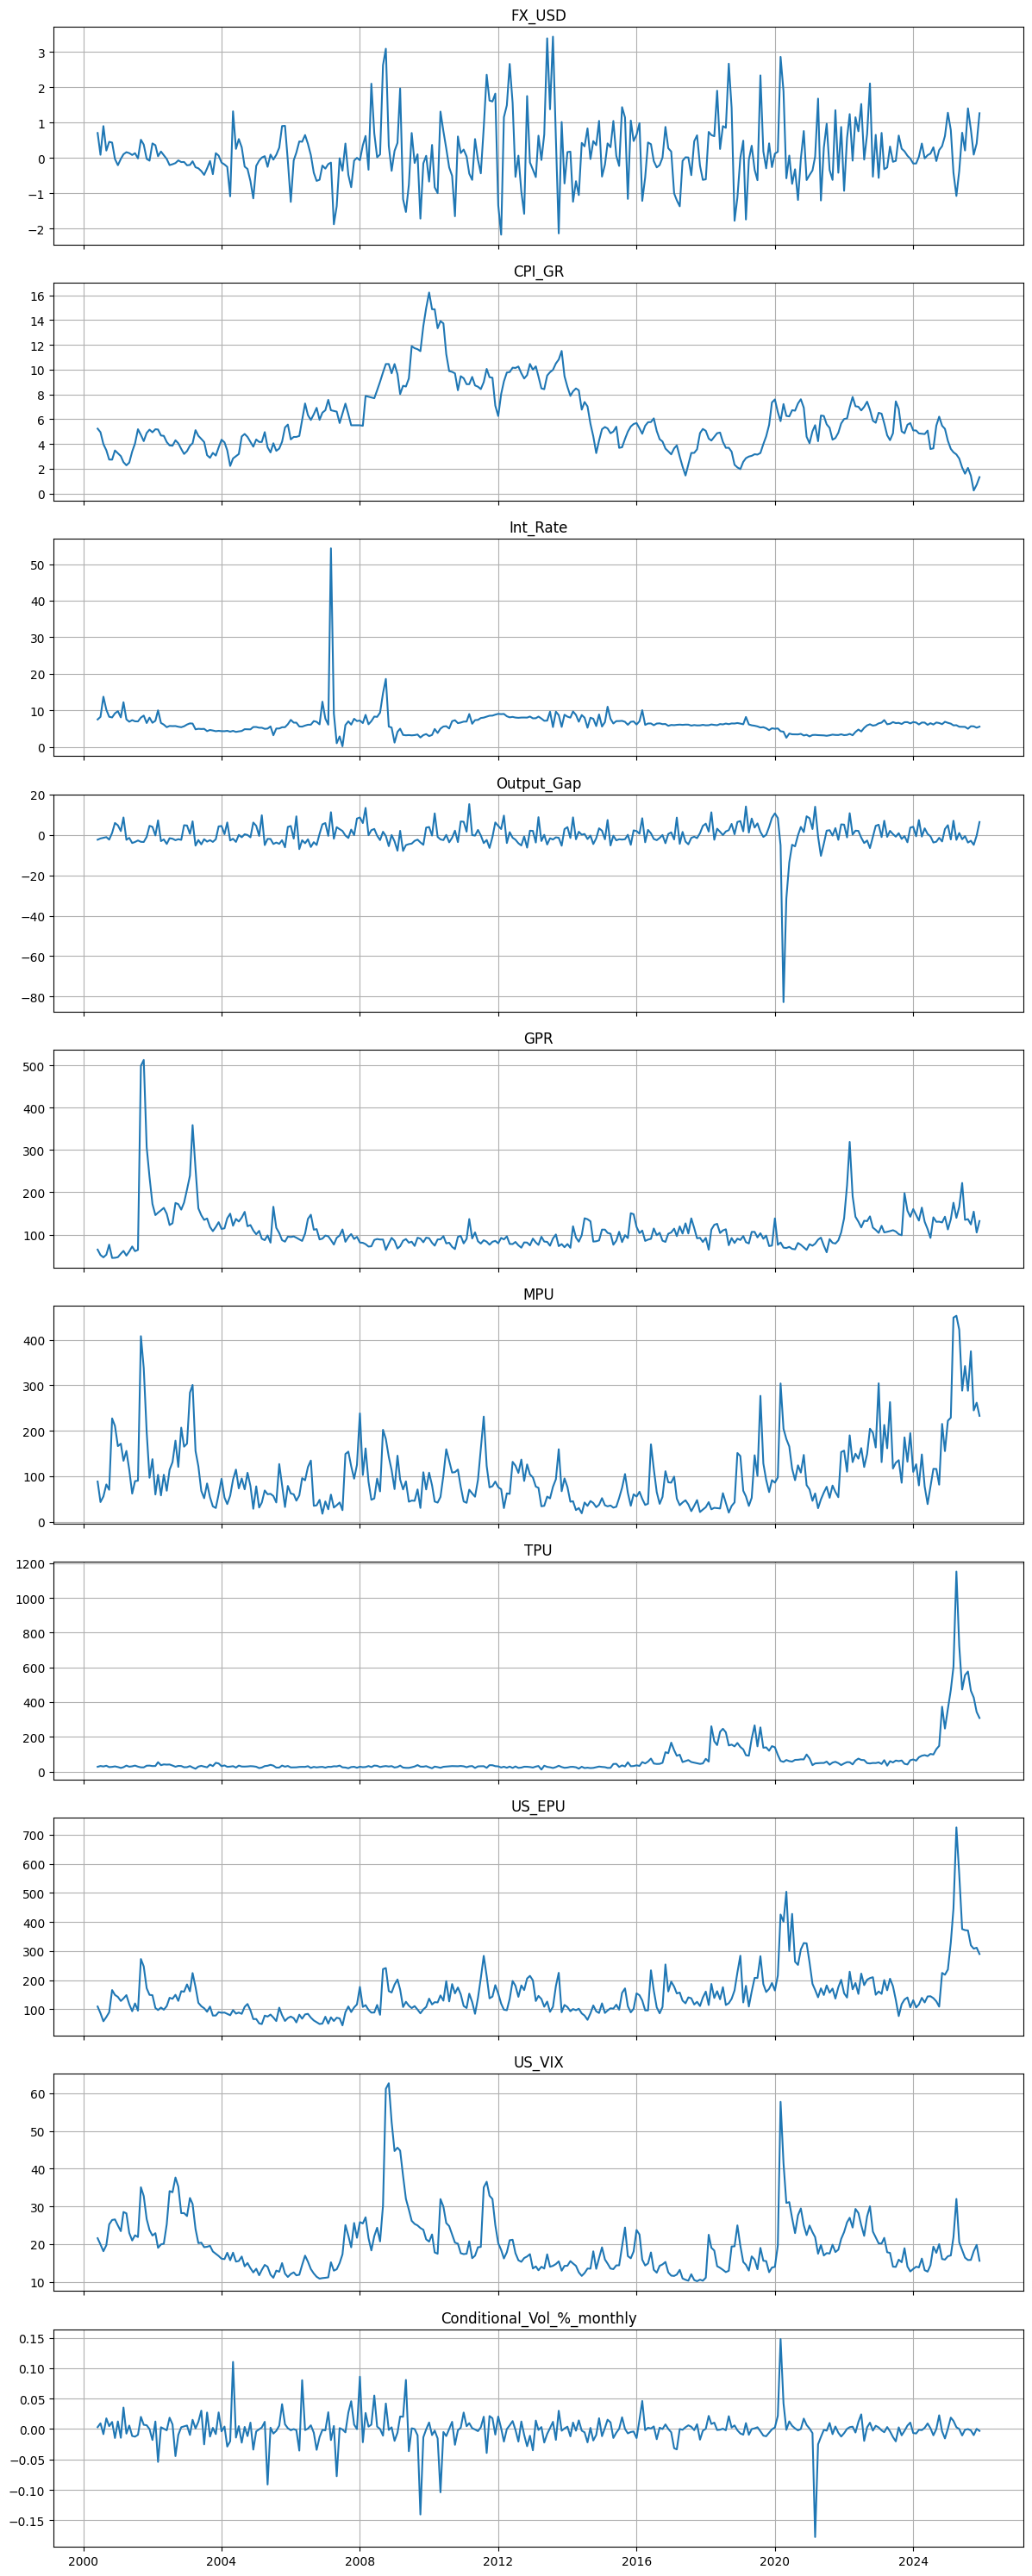

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(
    'stationary_variables.xlsx',
    sheet_name='sv-non-tpu',
    parse_dates=['Date']
)

df = df.sort_values('Date').set_index('Date')

# ── SUBPLOTS ─────────────────────────────────────
n_cols = len(df.columns)

fig, axes = plt.subplots(n_cols, 1, figsize=(12, 3*n_cols), sharex=True)

if n_cols == 1:
    axes = [axes]

for i, col in enumerate(df.columns):
    axes[i].plot(df.index, df[col])
    axes[i].set_title(col)
    axes[i].grid(True)

plt.tight_layout()
plt.show()

**CO-INTEGRATION**

In [ ]:
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# =====================================================
# LOAD ORIGINAL (LEVEL) DATA
# =====================================================
df = pd.read_excel("Compiled.xlsx")   # <-- IMPORTANT

# =====================================================
# SELECT VARIABLES (LEVELS ONLY)
# =====================================================
cols = [
    "TPU",
    "GPR",
    "CPI_GR",
    "MPU",
    "US_EPU",
    "Int_Rate",
    "FX_USD",
    "Output_Gap",
    "US_VIX",
    'Conditional_Vol_%_monthly'
]

# Check column names
print(df.columns)

# Extract data
data = df[cols].dropna()

# =====================================================
# JOHANSEN TEST
# =====================================================
johansen_test = coint_johansen(data, det_order=0, k_ar_diff=1)

# =====================================================
# OUTPUT
# =====================================================
print("Trace Statistics:")
print(johansen_test.lr1)

print("\nCritical Values (5%):")
print(johansen_test.cvt[:, 1])

Index(['Date', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU',
       'TPU', 'US_EPU', 'US_VIX', 'Conditional_Vol_%_monthly', 'Close'],
      dtype='object')
Trace Statistics:
[447.35272186 337.89476615 242.89034498 175.27808138 123.75597408
  73.77867723  44.30606117  22.40313804  10.18513319   0.45044855]

Critical Values (5%):
[239.2468 197.3772 159.529  125.6185  95.7542  69.8189  47.8545  29.7961
  15.4943   3.8415]


In [ ]:
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# =====================================================
# LOAD ORIGINAL (LEVEL) DATA
# =====================================================
df = pd.read_excel("stationary_variables.xlsx")   # <-- IMPORTANT

# =====================================================
# SELECT VARIABLES (LEVELS ONLY)
# =====================================================
cols = [
    "TPU",
    "GPR",
    "CPI_GR",
    "MPU",
    "US_EPU",
    "Int_Rate",
    "FX_USD",
    "Output_Gap",
    "US_VIX",
    'Conditional_Vol_%_monthly'
]

# Check column names
print(df.columns)

# Extract data
data = df[cols].dropna()

# =====================================================
# JOHANSEN TEST
# =====================================================
johansen_test = coint_johansen(data, det_order=0, k_ar_diff=1)

# =====================================================
# OUTPUT
# =====================================================
print("Trace Statistics:")
print(johansen_test.lr1)

print("\nCritical Values (5%):")
print(johansen_test.cvt[:, 1])

Index(['Date', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU',
       'TPU', 'US_EPU', 'US_VIX', 'Conditional_Vol_%_monthly'],
      dtype='object')
Trace Statistics:
[797.66907372 564.68643657 432.80162135 316.23555619 216.0166346
 136.50347168  78.18520246  49.60286354  23.89834749   6.14998242]

Critical Values (5%):
[239.2468 197.3772 159.529  125.6185  95.7542  69.8189  47.8545  29.7961
  15.4943   3.8415]


**Dummy**

In [ ]:
# Cell 1 — Run this first, defines all dummy functions inline
# No separate file needed

import pandas as pd
import numpy as np
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')


def create_event_dummies(df_index):
    dummies = pd.DataFrame(index=df_index)

    point_events = {
    }
    for name, month in point_events.items():
        dummies[name] = 0
        mask = df_index.to_period('M').astype(str) == month
        dummies.loc[mask, name] = 1

    period_events = {
        'D_GFC'        : ('2008-06', '2009-06'),
        'D_COVID'      : ('2020-02', '2021-06')
    }
    for name, (start, end) in period_events.items():
        dummies[name] = 0
        start = max(start, df_index.min().strftime('%Y-%m'))
        end   = min(end,   df_index.max().strftime('%Y-%m'))
        mask  = (df_index >= start) & (df_index <= end)
        dummies.loc[mask, name] = 1

    active  = dummies.columns[dummies.sum() > 0]
    dropped = list(set(dummies.columns) - set(active))
    if dropped:
        print(f"  Dropped (outside sample): {dropped}")
    return dummies[active]


def select_significant_dummies(y, X_base, dummies, alpha=0.10):
    print(f"\n  Dummy Selection (p < {alpha}):")
    print(f"  {'Dummy':<22} {'Coef':>10} {'p-value':>10} {'Keep':>6}")
    print("  " + "-" * 52)

    kept = []
    for col in dummies.columns:
        X_test = sm.add_constant(
            pd.concat([X_base, dummies[[col]]], axis=1).dropna()
        )
        y_test = y.reindex(X_test.index)
        try:
            res  = sm.OLS(y_test, X_test).fit()
            p    = res.pvalues.get(col, 1.0)
            co   = res.params.get(col, 0.0)
            keep = p < alpha
            print(f"  {col:<22} {co:>10.4f} {p:>10.4f} {'✓' if keep else '✗':>6}")
            if keep:
                kept.append(col)
        except Exception as e:
            print(f"  {col:<22} ERROR: {e}")

    print(f"\n  → Keeping {len(kept)} dummies: {kept}")
    return dummies[kept] if kept else pd.DataFrame(index=dummies.index)


def get_dummies_for_model(df, y_col, regressor_cols, alpha=0.10):
    df_clean = df[regressor_cols + [y_col]].dropna()
    y        = df_clean[y_col]
    X_base   = df_clean[regressor_cols]

    all_dummies = create_event_dummies(df_clean.index)
    sig_dummies = select_significant_dummies(y, X_base, all_dummies, alpha)
    return sig_dummies.reindex(df.index).fillna(0)


print("  Dummy functions loaded successfully.")

  Dummy functions loaded successfully.


In [ ]:
# dummy_module.py
# Standalone — import this into ardl, svar, tvar scripts

import pandas as pd
import numpy as np
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')


def create_event_dummies(df_index):
    """
    Creates period and point dummies for known shock events.
    Use corrected wider windows — especially for COVID and Trade War.
    df_index: DatetimeIndex of your dataset
    """
    dummies = pd.DataFrame(index=df_index)

    # ── Point dummies: genuine single-month instantaneous shocks ──────────────
    point_events = {


    }
    for name, month in point_events.items():
        dummies[name] = 0
        mask = df_index.to_period('M').astype(str) == month
        dummies.loc[mask, name] = 1

    # ── Period dummies: sustained shock episodes ───────────────────────────────
    period_events = {
        'D_GFC'        : ('2008-06', '2009-06'),   # Full GFC + trough
        'D_COVID'      : ('2020-02', '2021-06')

    }
    for name, (start, end) in period_events.items():
        dummies[name] = 0
        # clip to actual sample
        start = max(start, df_index.min().strftime('%Y-%m'))
        end   = min(end,   df_index.max().strftime('%Y-%m'))
        mask  = (df_index >= start) & (df_index <= end)
        dummies.loc[mask, name] = 1

    # Drop dummies that never activate in this sample
    active = dummies.columns[dummies.sum() > 0]
    dropped = list(set(dummies.columns) - set(active))
    if dropped:
        print(f"  Dropped (outside sample): {dropped}")
    return dummies[active]


def select_significant_dummies(y, X_base, dummies, alpha=0.10):
    """
    Tests each dummy individually in a baseline OLS.
    Keeps only those with p < alpha.
    Returns DataFrame of significant dummies only.
    """
    print(f"\n  Dummy Selection (p < {alpha}):")
    print(f"  {'Dummy':<22} {'Coef':>10} {'p-value':>10} {'Keep':>6}")
    print("  " + "-" * 52)

    kept = []
    for col in dummies.columns:
        X_test = sm.add_constant(
            pd.concat([X_base, dummies[[col]]], axis=1).dropna()
        )
        y_test = y.reindex(X_test.index)
        try:
            res = sm.OLS(y_test, X_test).fit()
            p   = res.pvalues.get(col, 1.0)
            co  = res.params.get(col, 0.0)
            keep = p < alpha
            print(f"  {col:<22} {co:>10.4f} {p:>10.4f} {'✓' if keep else '✗':>6}")
            if keep:
                kept.append(col)
        except Exception as e:
            print(f"  {col:<22} ERROR: {e}")

    print(f"\n  → Keeping {len(kept)} dummies: {kept}")
    return dummies[kept] if kept else pd.DataFrame(index=dummies.index)


def get_dummies_for_model(df, y_col, regressor_cols, alpha=0.10):
    """
    Master function — call this from any model script.
    df           : your model's dataframe (original or stationary)
    y_col        : name of dependent variable column
    regressor_cols: list of regressor column names
    Returns: sig_dummies DataFrame aligned to df.index
    """
    df_clean = df[regressor_cols + [y_col]].dropna()
    y        = df_clean[y_col]
    X_base   = df_clean[regressor_cols]

    all_dummies = create_event_dummies(df_clean.index)
    sig_dummies = select_significant_dummies(y, X_base, all_dummies, alpha)
    return sig_dummies.reindex(df.index).fillna(0)

**ARDL**

Columns found: ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Conditional_Vol_%_monthly']
Volatility column: 'Conditional_Vol_%_monthly' → renamed to 'Vol_GARCH'
  ARDL — Dependent Variable: GARCH-X Conditional Volatility
  Sample : 2000-05-01 to 2025-12-01
  N      : 308 observations
  Regressors: ['TPU', 'GPR', 'TPU_GPR', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

  ADF Stationarity Tests:
  Variable         ADF p-value               Status
  --------------------------------------------------
  Vol_GARCH             0.2212 I(1) — Non-stationary
  TPU                   0.9807 I(1) — Non-stationary
  GPR                   0.3695 I(1) — Non-stationary
  TPU_GPR               0.9921 I(1) — Non-stationary
  FX_USD                0.9894 I(1) — Non-stationary
  CPI_GR                0.6123 I(1) — Non-stationary
  Int_Rate              0.0000      I(0) Stationary
  Output_Gap            0.0000      I(0) Stationary
  MPU

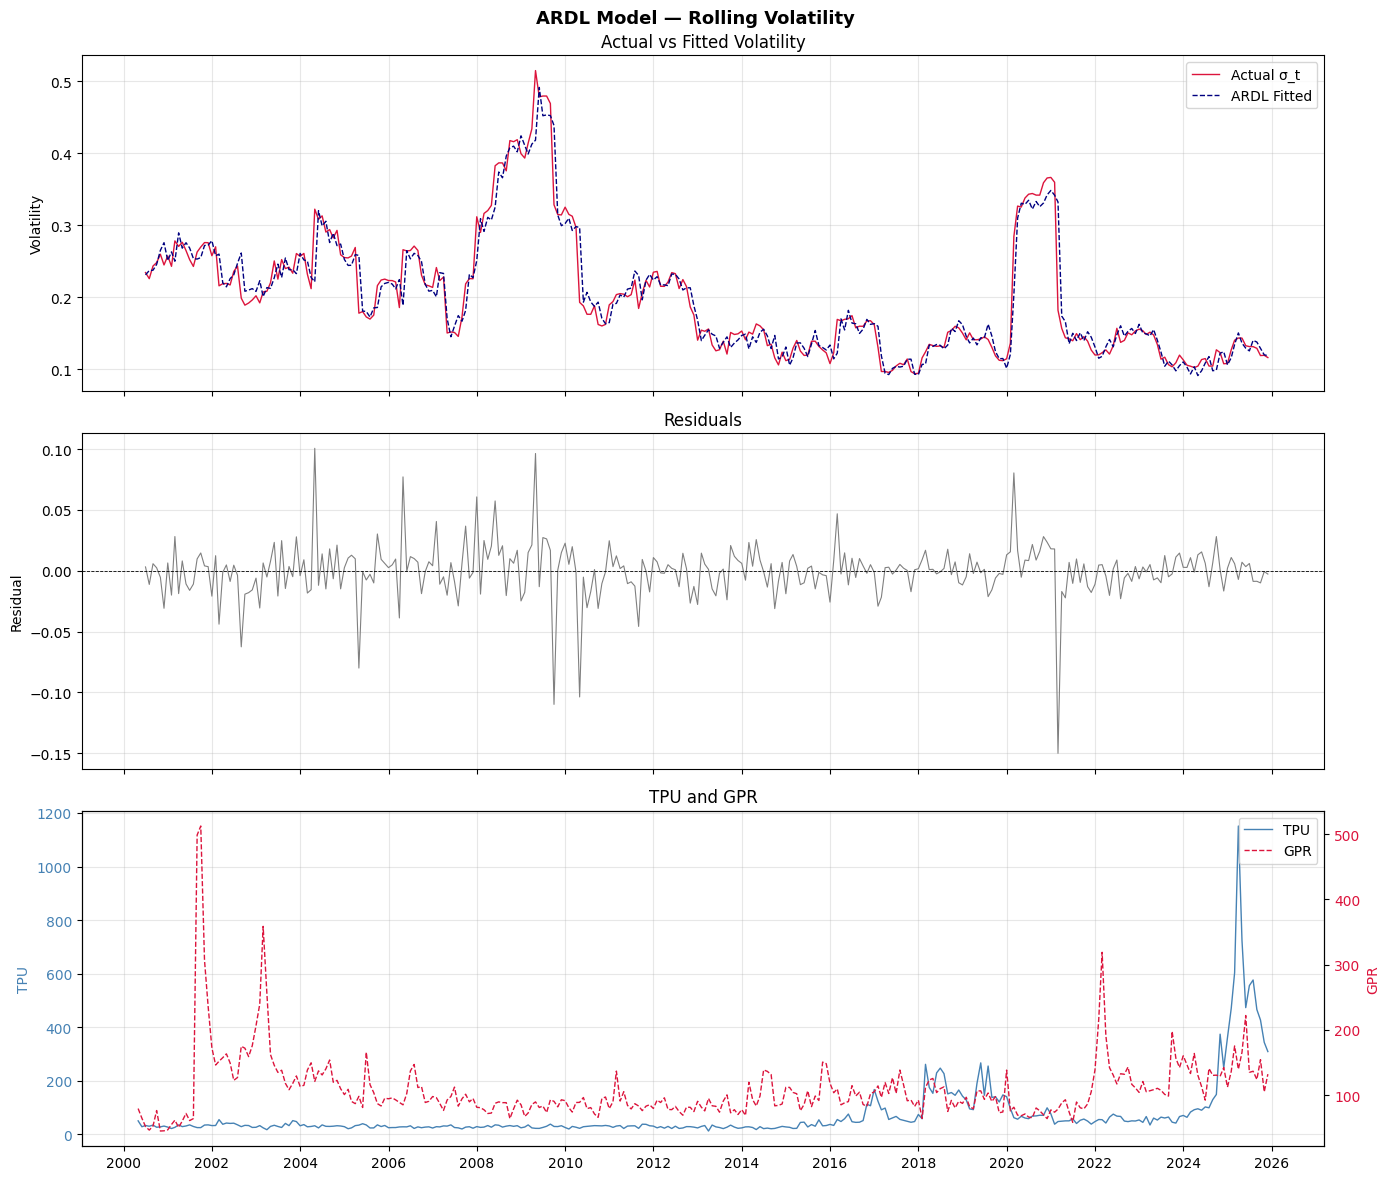


  Saving to ardl_final_results.xlsx...
  Saved: ardl_final_results.xlsx
  Saved: ardl_results.png

  Done!


In [ ]:
"""
ARDL Model — GARCH-X Conditional Volatility on TPU, GPR, and Controls
======================================================================
Fixed for statsmodels 0.14.x compatibility.
Input:  stationary_variables.xlsx
Output: ardl_final_results.xlsx + ardl_results.png
"""

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')


# ════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ════════════════════════════════════════════════════════════
df = pd.read_excel('Compiled0.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values('Date').set_index('Date')

print("Columns found:", df.columns.tolist())

# Auto-detect volatility column
vol_col = [c for c in df.columns if 'Conditional_Vol' in c]
if vol_col:
    df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})
    print(f"Volatility column: '{vol_col[0]}' → renamed to 'Vol_GARCH'")
else:
    raise ValueError("No volatility column found. Check column names.")

# Interaction term
df['TPU_GPR'] = df['TPU'] * df['GPR']

# ════════════════════════════════════════════════════════════
# 2. DEFINE VARIABLES
# ════════════════════════════════════════════════════════════
controls   = ['FX_USD', 'CPI_GR', 'Int_Rate',
              'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']
regressors = ['TPU', 'GPR', 'TPU_GPR'] + controls
required   = ['Vol_GARCH'] + regressors

df = df.dropna(subset=required)

y = df['Vol_GARCH']
X = df[regressors]

print("=" * 60)
print("  ARDL — Dependent Variable: GARCH-X Conditional Volatility")
print("=" * 60)
print(f"  Sample : {df.index.min().date()} to {df.index.max().date()}")
print(f"  N      : {len(df)} observations")
print(f"  Regressors: {regressors}")


# ════════════════════════════════════════════════════════════
# 3. STATIONARITY CHECK
# ════════════════════════════════════════════════════════════
print("\n  ADF Stationarity Tests:")
print(f"  {'Variable':<15} {'ADF p-value':>12} {'Status':>20}")
print("  " + "-" * 50)
for col in required:
    p = adfuller(df[col], autolag='AIC')[1]
    status = 'I(0) Stationary' if p < 0.05 else 'I(1) — Non-stationary'
    print(f"  {col:<15} {p:>12.4f} {status:>20}")


# ════════════════════════════════════════════════════════════
# 4. ARDL VIA OLS — MANUAL CONSTRUCTION
# ════════════════════════════════════════════════════════════
# The statsmodels ARDL class has changed its API across versions.
# The most stable and transparent approach is to build the ARDL
# manually by constructing lagged variables and running OLS.
# This gives identical results and works across all versions.
# ─────────────────────────────────────────────────────────────

Y_LAGS = 2   # lags of dependent variable (vol)
X_LAGS = 2   # lags of each regressor

print(f"\n  ARDL specification: y_lags={Y_LAGS}, x_lags={X_LAGS}")
print(f"  ARDL({Y_LAGS}, {', '.join([str(X_LAGS)]*len(regressors))})")

# Build lagged dataset
ardl_df = pd.DataFrame(index=df.index)
ardl_df['Vol_GARCH'] = y

# Lags of dependent variable
for lag in range(1, Y_LAGS + 1):
    ardl_df[f'Vol_GARCH_L{lag}'] = y.shift(lag)

# Current values and lags of each regressor
for var in regressors:
    ardl_df[var] = df[var]                          # contemporaneous
    for lag in range(1, X_LAGS + 1):
        ardl_df[f'{var}_L{lag}'] = df[var].shift(lag)  # lagged

ardl_df = ardl_df.dropna()

# Dependent and independent variables for OLS
Y_reg = ardl_df['Vol_GARCH']
X_reg = ardl_df.drop(columns=['Vol_GARCH'])
X_reg = sm.add_constant(X_reg)

# ════════════════════════════════════════════════════════════
# 5. FIT OLS
# ════════════════════════════════════════════════════════════
ols_model = sm.OLS(Y_reg, X_reg)
res       = ols_model.fit(cov_type='HC3')   # robust SEs

print("\n" + "=" * 60)
print("  OLS Results (ARDL manually constructed)")
print("=" * 60)
print(res.summary())


# ════════════════════════════════════════════════════════════
# 6. LONG-RUN MULTIPLIERS
# ════════════════════════════════════════════════════════════
# LR coef(x) = sum of all x coefficients / (1 - sum of y lag coefficients)
# This is the total persistent effect of x on volatility

print("\n" + "=" * 60)
print("  LONG-RUN MULTIPLIERS")
print("  Persistent (total) effect of each variable on volatility")
print("=" * 60)

params = res.params

# Sum of y lag coefficients (persistence)
y_lag_keys = [k for k in params.index if 'Vol_GARCH_L' in k]
y_lag_sum  = params[y_lag_keys].sum()
denom      = 1 - y_lag_sum

print(f"\n  Sum of y lags (persistence): {y_lag_sum:.4f}")
print(f"  Denominator (1 - sum):       {denom:.4f}")

if abs(denom) < 1e-6:
    print("  ⚠ Denominator near zero — long-run coefficients unreliable")

print(f"\n  {'Variable':<15} {'SR Contemporaneous':>20} {'LR Multiplier':>15}")
print("  " + "-" * 52)

lr_results = {}
for var in regressors:
    # All keys that contain this variable name (current + lags)
    x_keys = [k for k in params.index
               if k == var or k.startswith(f'{var}_L')]
    x_sum  = params[x_keys].sum() if x_keys else 0.0
    sr_con = params.get(var, np.nan)   # contemporaneous only
    lr_val = x_sum / denom if abs(denom) > 1e-6 else np.nan
    lr_results[var] = lr_val
    print(f"  {var:<15} {sr_con:>20.6f} {lr_val:>15.6f}")


# ════════════════════════════════════════════════════════════
# 7. SPEED OF ADJUSTMENT
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  ERROR CORRECTION DYNAMICS")
print("=" * 60)

ect_coef = -(1 - y_lag_sum)
print(f"  Speed of adjustment (ECT): {ect_coef:.4f}")

if ect_coef < 0:
    half_life = np.log(0.5) / np.log(1 + ect_coef)
    print(f"  → Corrects {abs(ect_coef)*100:.1f}% of disequilibrium per month")
    print(f"  → Half-life of shock: {half_life:.1f} months")
else:
    print("  ⚠ Positive ECT — no mean reversion. Check stationarity.")


# ════════════════════════════════════════════════════════════
# 8. BOUNDS TEST (MANUAL — PESARAN ET AL. 2001)
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  BOUNDS TEST — Pesaran et al. (2001)")
print("  H0: No long-run relationship (all level coefficients = 0)")
print("=" * 60)

try:
    # Restricted model: only y lags, no X
    X_restricted = sm.add_constant(
        ardl_df[[f'Vol_GARCH_L{l}' for l in range(1, Y_LAGS+1)]]
    )
    res_r   = sm.OLS(Y_reg, X_restricted).fit()

    rss_r   = (res_r.resid**2).sum()
    rss_u   = (res.resid**2).sum()
    T_      = len(Y_reg)
    k_u     = len(res.params)

    # Number of level regressors being tested
    x_level_keys = [k for k in params.index
                    if k in regressors]   # contemporaneous only
    q = len(x_level_keys)

    f_stat = ((rss_r - rss_u) / q) / (rss_u / (T_ - k_u))

    # Pesaran (2001) critical values — Case III (intercept, no trend)
    cv = {'10%': (1.75, 2.87), '5%': (1.99, 3.21), '1%': (2.58, 3.89)}

    print(f"\n  F-statistic : {f_stat:.4f}")
    print(f"  q (regressors tested): {q}")
    print(f"\n  {'Level':<8} {'I(0) Lower':>12} {'I(1) Upper':>12} {'Result':>20}")
    print("  " + "-" * 55)

    conclusion = "No long-run relationship"
    for level, (lb_cv, ub_cv) in cv.items():
        if f_stat > ub_cv:
            flag = "Above upper bound ✓"
            conclusion = f"Long-run relationship at {level}"
        elif f_stat < lb_cv:
            flag = "Below lower bound ✗"
        else:
            flag = "Inconclusive"
        print(f"  {level:<8} {lb_cv:>12.3f} {ub_cv:>12.3f} {flag:>20}")

    print(f"\n  Conclusion: {conclusion}")

except Exception as e:
    print(f"  ⚠ Bounds test failed: {e}")


# ════════════════════════════════════════════════════════════
# 9. DIAGNOSTICS
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  DIAGNOSTICS")
print("=" * 60)

resid = res.resid
dw    = durbin_watson(resid)
lb4   = acorr_ljungbox(resid, lags=[4],  return_df=True)
lb8   = acorr_ljungbox(resid, lags=[8],  return_df=True)

def tick(p, good_if_above=0.05):
    return '✓' if p > good_if_above else '⚠'

try:
    _, bp_p, _, _ = het_breuschpagan(resid, res.model.exog)
    print(f"  Breusch-Pagan (heteroskedasticity) p : {bp_p:.4f}  {tick(bp_p)}")
except Exception:
    print("  Breusch-Pagan: could not compute")

print(f"  Durbin-Watson                        : {dw:.4f}  "
      f"{'✓' if 1.5 < dw < 2.5 else '⚠'}")
print(f"  Ljung-Box p (lag 4)                  : "
      f"{lb4['lb_pvalue'].values[0]:.4f}  {tick(lb4['lb_pvalue'].values[0])}")
print(f"  Ljung-Box p (lag 8)                  : "
      f"{lb8['lb_pvalue'].values[0]:.4f}  {tick(lb8['lb_pvalue'].values[0])}")
print(f"  R-squared                            : {res.rsquared:.4f}")
print(f"  Adj. R-squared                       : {res.rsquared_adj:.4f}")
print(f"  AIC                                  : {res.aic:.4f}")
print(f"  BIC                                  : {res.bic:.4f}")


# ════════════════════════════════════════════════════════════
# 10. COEFFICIENT TABLE
# ════════════════════════════════════════════════════════════
def stars(p):
    return '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.10 else 'ns'))

coef_df = pd.DataFrame({
    'Parameter'  : res.params.index,
    'Coefficient': res.params.values.round(6),
    'Std_Error'  : res.bse.values.round(6),
    'T_Stat'     : res.tvalues.values.round(4),
    'P_Value'    : res.pvalues.values.round(4),
    'Significance': [stars(p) for p in res.pvalues],
    'CI_Lower_95': res.conf_int()[0].values.round(6),
    'CI_Upper_95': res.conf_int()[1].values.round(6),
})

lr_df = pd.DataFrame({
    'Variable'  : list(lr_results.keys()),
    'LR_Coef'   : [round(v, 6) for v in lr_results.values()],
    'Interpretation': [
        'Long-run effect of variable on GARCH volatility'
        for _ in lr_results
    ]
})

diag_df = pd.DataFrame({
    'Diagnostic': [
        'R-squared', 'Adj R-squared', 'Durbin-Watson',
        'Ljung-Box p (lag4)', 'Ljung-Box p (lag8)',
        'Breusch-Pagan p', 'AIC', 'BIC',
        'ECT coefficient', 'F-stat (Bounds)'
    ],
    'Value': [
        round(res.rsquared, 4),
        round(res.rsquared_adj, 4),
        round(dw, 4),
        round(lb4['lb_pvalue'].values[0], 4),
        round(lb8['lb_pvalue'].values[0], 4),
        round(bp_p, 4) if 'bp_p' in dir() else 'NA',
        round(res.aic, 4),
        round(res.bic, 4),
        round(ect_coef, 4),
        round(f_stat, 4) if 'f_stat' in dir() else 'NA',
    ],
    'Good_If': [
        'Higher', 'Higher', '~2.0',
        '>0.05', '>0.05', '>0.05',
        'Lower', 'Lower', 'Negative', 'Above upper CV'
    ]
})


# ════════════════════════════════════════════════════════════
# 11. PLOT
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle('ARDL Model — Rolling Volatility',
             fontsize=13, fontweight='bold')

n_fitted = len(res.fittedvalues)
plot_idx = ardl_df.index   # index after dropping NaN from lags

# Actual vs Fitted
axes[0].plot(plot_idx, Y_reg.values,
             color='crimson', linewidth=1, label='Actual σ_t')
axes[0].plot(plot_idx, res.fittedvalues.values,
             color='navy', linewidth=1, linestyle='--', label='ARDL Fitted')
axes[0].set_title('Actual vs Fitted Volatility')
axes[0].set_ylabel('Volatility')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals
axes[1].plot(plot_idx, resid.values, color='grey', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.6, linestyle='--')
axes[1].set_title('Residuals')
axes[1].set_ylabel('Residual')
axes[1].grid(True, alpha=0.3)

# TPU and GPR over time
ax2b = axes[2].twinx()
axes[2].plot(df.index, df['TPU'], color='steelblue', linewidth=1, label='TPU')
ax2b.plot(df.index,    df['GPR'], color='crimson',   linewidth=1,
          label='GPR', linestyle='--')
axes[2].set_title('TPU and GPR')
axes[2].set_ylabel('TPU', color='steelblue')
ax2b.set_ylabel('GPR', color='crimson')
axes[2].tick_params(axis='y', labelcolor='steelblue')
ax2b.tick_params(axis='y', labelcolor='crimson')
l1, lb1 = axes[2].get_legend_handles_labels()
l2, lb2 = ax2b.get_legend_handles_labels()
axes[2].legend(l1+l2, lb1+lb2, loc='upper right')
axes[2].grid(True, alpha=0.3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('ardl_results.png', dpi=150, bbox_inches='tight')
plt.show()


# ════════════════════════════════════════════════════════════
# 12. SAVE TO EXCEL
# ════════════════════════════════════════════════════════════
from openpyxl.styles import Font, PatternFill, Alignment

print(f"\n  Saving to ardl_final_results.xlsx...")

with pd.ExcelWriter('ardl_final_results.xlsx', engine='openpyxl') as writer:
    coef_df.to_excel(writer, sheet_name='Coefficients',        index=False)
    lr_df.to_excel(writer,   sheet_name='LongRun_Multipliers', index=False)
    diag_df.to_excel(writer, sheet_name='Diagnostics',         index=False)

    # Save full data with fitted and residuals
    fitted_df = ardl_df[['Vol_GARCH']].copy()
    fitted_df['Fitted']    = res.fittedvalues.values
    fitted_df['Residuals'] = resid.values
    fitted_df.reset_index().to_excel(
        writer, sheet_name='Fitted_Series', index=False)

    # Formatting
    hf    = Font(bold=True, color='FFFFFF')
    hfill = PatternFill('solid', start_color='1F4E79')
    for sn in writer.book.sheetnames:
        ws = writer.book[sn]
        for cell in ws[1]:
            cell.font = hf; cell.fill = hfill
            cell.alignment = Alignment(horizontal='center')
        for col in ws.columns:
            w = max(len(str(c.value or '')) for c in col) + 3
            ws.column_dimensions[col[0].column_letter].width = min(w, 40)

print("  Saved: ardl_final_results.xlsx")
print("  Saved: ardl_results.png")
print("\n  Done!")

  Volatility column: Conditional_Vol_%_monthly
  Sample: 2000-05-01 → 2025-12-01  (N=308)

  ADF Tests — Integration Order:
  Variable             ADF Stat    p-value    Order
  --------------------------------------------------
  Conditional_Vol_%_monthly    -2.1598     0.2212    I(1)+
  TPU                    0.3784     0.9807    I(1)+
  GPR                   -1.8222     0.3695    I(1)+
  TPU_GPR                0.8322     0.9921    I(1)+
  FX_USD                 0.6783     0.9894    I(1)+
  CPI_GR                -1.3365     0.6123    I(1)+
  Int_Rate              -5.6158     0.0000     I(0)
  Output_Gap            -5.4020     0.0000     I(0)
  MPU                   -4.1880     0.0007     I(0)
  US_EPU                -3.6320     0.0052     I(0)
  US_VIX                -4.5273     0.0002     I(0)

  Dummy Selection (p < 0.1):
  Dummy                        Coef    p-value   Keep
  ----------------------------------------------------
  D_GFC                      0.1349     0.0000      ✓

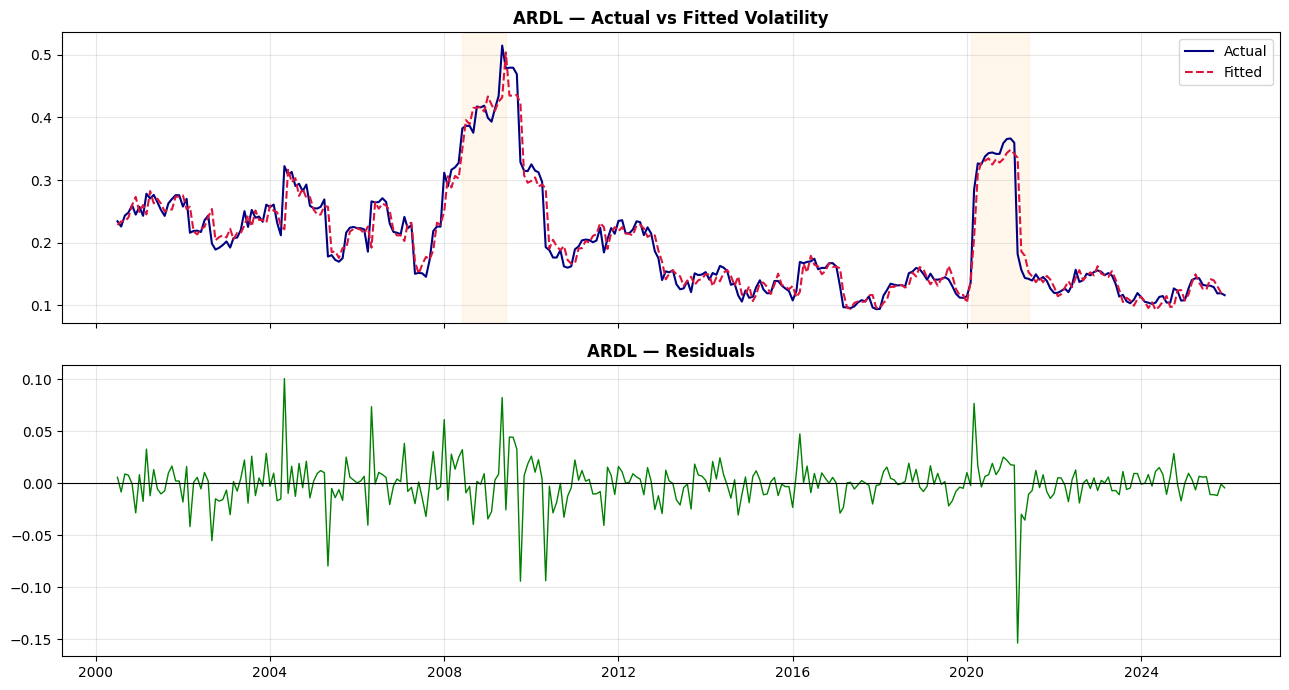

In [ ]:
# ardl_final.py
# Uses: compiled.xlsx (original data, I(0)+I(1) mix allowed)
# Dummies created on original data index

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# from dummy_module import get_dummies_for_model   # ← import dummy helper
# ════════════════════════════════════════════════════════════
# 0. DUMMY FUNCTIONS
# ════════════════════════════════════════════════════════════
# def create_event_dummies(df_index):
#     dummies = pd.DataFrame(index=df_index)
#     point_events = {}
#     period_events = {
#         'D_GFC'   : ('2008-06', '2009-06'),
#         'D_COVID' : ('2020-02', '2021-06'),
#     }
#     for name, (start, end) in period_events.items():
#         dummies[name] = 0
#         start = max(start, df_index.min().strftime('%Y-%m'))
#         end   = min(end,   df_index.max().strftime('%Y-%m'))
#         mask  = (df_index >= start) & (df_index <= end)
#         dummies.loc[mask, name] = 1
#     active  = dummies.columns[dummies.sum() > 0]
#     dropped = list(set(dummies.columns) - set(active))
#     if dropped:
#         print(f"  Dropped (outside sample): {dropped}")
#     return dummies[active]

# def select_significant_dummies(y, X_base, dummies, alpha=0.10):
#     print(f"\n  Dummy Selection (p < {alpha}):")
#     print(f"  {'Dummy':<22} {'Coef':>10} {'p-value':>10} {'Keep':>6}")
#     print("  " + "-" * 52)
#     kept = []
#     for col in dummies.columns:
#         X_test = sm.add_constant(
#             pd.concat([X_base, dummies[[col]]], axis=1).dropna()
#         )
#         y_test = y.reindex(X_test.index)
#         try:
#             res  = sm.OLS(y_test, X_test).fit()
#             p    = res.pvalues.get(col, 1.0)
#             co   = res.params.get(col, 0.0)
#             keep = p < alpha
#             print(f"  {col:<22} {co:>10.4f} {p:>10.4f} {'✓' if keep else '✗':>6}")
#             if keep:
#                 kept.append(col)
#         except Exception as e:
#             print(f"  {col:<22} ERROR: {e}")
#     print(f"\n  → Keeping {len(kept)} dummies: {kept}")
#     return dummies[kept] if kept else pd.DataFrame(index=dummies.index)
# ══════════════════════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════════════════════════════════════════
df = pd.read_excel('Compiled0.xlsx')   # original compiled data
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['Date']).sort_values('Date').set_index('Date')

# Detect volatility column
vol_candidates = [c for c in df.columns if 'Conditional_Vol' in c or 'Vol_GARCH' in c]
if not vol_candidates:
    raise ValueError("No volatility column found. Check column names.")
VOL_COL = vol_candidates[0]
print(f"  Volatility column: {VOL_COL}")

df['TPU_GPR'] = df['TPU'] * df['GPR']

CONTROLS    = ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap',
               'MPU', 'US_EPU', 'US_VIX']
REGRESSORS  = ['TPU', 'GPR', 'TPU_GPR'] + CONTROLS
Y_LAGS      = 2
X_LAGS      = 2

df = df.dropna(subset=[VOL_COL] + REGRESSORS)
print(f"  Sample: {df.index[0].date()} → {df.index[-1].date()}  (N={len(df)})")

# ══════════════════════════════════════════════════════════════════════════════
# 2. INTEGRATION ORDER CHECK — confirm no I(2) variable
# ══════════════════════════════════════════════════════════════════════════════
print("\n  ADF Tests — Integration Order:")
print(f"  {'Variable':<18} {'ADF Stat':>10} {'p-value':>10} {'Order':>8}")
print("  " + "-" * 50)

for col in [VOL_COL] + REGRESSORS:
    try:
        res = adfuller(df[col].dropna(), autolag='AIC')
        order = 'I(0)' if res[1] < 0.05 else 'I(1)+'
        print(f"  {col:<18} {res[0]:>10.4f} {res[1]:>10.4f} {order:>8}")
    except Exception as e:
        print(f"  {col:<18} ERROR: {e}")

# ══════════════════════════════════════════════════════════════════════════════
# 3. GET SIGNIFICANT DUMMIES (on original data)
# ══════════════════════════════════════════════════════════════════════════════
sig_dummies = get_dummies_for_model(df, VOL_COL, REGRESSORS, alpha=0.10)
dummy_cols  = list(sig_dummies.columns)
print(f"\n  Significant dummies for ARDL: {dummy_cols}")

# ══════════════════════════════════════════════════════════════════════════════
# 4. BUILD ARDL REGRESSOR MATRIX
# ══════════════════════════════════════════════════════════════════════════════
ardl = pd.DataFrame(index=df.index)
ardl[VOL_COL] = df[VOL_COL]

# Lags of dependent variable
for lag in range(1, Y_LAGS + 1):
    ardl[f'Y_L{lag}'] = df[VOL_COL].shift(lag)

# Current + lagged regressors
for var in REGRESSORS:
    ardl[var] = df[var]
    for lag in range(1, X_LAGS + 1):
        ardl[f'{var}_L{lag}'] = df[var].shift(lag)

# Dummies — no lags (exogenous, known timing)
for col in dummy_cols:
    ardl[col] = sig_dummies[col]

ardl = ardl.dropna()
Y_reg = ardl[VOL_COL]
X_reg = sm.add_constant(ardl.drop(columns=[VOL_COL]))

# ══════════════════════════════════════════════════════════════════════════════
# 5. OLS ESTIMATION WITH HC3 ROBUST STANDARD ERRORS
# ══════════════════════════════════════════════════════════════════════════════
res = sm.OLS(Y_reg, X_reg).fit(cov_type='HC3')
print("\n" + "=" * 65)
print("  ARDL RESULTS (with dummies, HC3 robust SEs)")
print("=" * 65)
print(res.summary())

# ══════════════════════════════════════════════════════════════════════════════
# 6. BOUNDS TEST (Pesaran 2001)
# ══════════════════════════════════════════════════════════════════════════════
# F-stat from joint significance of level regressors (not lags)
# Level regressors: current period values of X (lag 0)
level_vars = [v for v in REGRESSORS if v in res.params.index]

# Wald test on level regressors
try:
    wald = res.wald_test(
        '(' + ', '.join([f'{v} = 0' for v in level_vars]) + ')',
        use_f=True
    )
    f_stat = float(wald.statistic)
    print(f"\n  Bounds Test F-statistic: {f_stat:.4f}")
    print(f"  k (regressors) = {len(level_vars)}")

    # Pesaran 2001 critical values (Case III: unrestricted intercept, no trend)
    # k=10 approx — use k=10 row
    cv_table = {
        1:  (4.94, 5.73), 2:  (4.26, 5.02), 3:  (3.88, 4.61),
        4:  (3.74, 4.35), 5:  (3.35, 4.02), 6:  (3.15, 3.79),
        7:  (3.02, 3.62), 8:  (2.96, 3.49), 9:  (2.79, 3.37),
        10: (2.75, 3.27)
    }
    k = min(len(level_vars), 10)
    I0_cv, I1_cv = cv_table[k]
    print(f"  Critical values (5%, k={k}): I(0)={I0_cv}  I(1)={I1_cv}")

    if f_stat > I1_cv:
        conclusion = "REJECT H0 — Long-run relationship exists"
    elif f_stat < I0_cv:
        conclusion = "FAIL TO REJECT H0 — No long-run relationship"
    else:
        conclusion = "INCONCLUSIVE — result lies in bounds"
    print(f"  → {conclusion}")

except Exception as e:
    print(f"  Bounds test error: {e}")

# ══════════════════════════════════════════════════════════════════════════════
# 7. LONG-RUN MULTIPLIERS
# ══════════════════════════════════════════════════════════════════════════════
print("\n  Long-run Multipliers:")
print(f"  {'Variable':<15} {'LR Multiplier':>15} {'Interpretation'}")
print("  " + "-" * 55)

# Speed of adjustment = 1 - sum(lagged Y coefficients)
y_lag_coefs = [res.params.get(f'Y_L{i}', 0) for i in range(1, Y_LAGS+1)]
speed = 1 - sum(y_lag_coefs)
print(f"\n  Speed of adjustment (denominator): {speed:.4f}")

for var in ['TPU', 'GPR', 'TPU_GPR']:
    beta_sum = sum(
        res.params.get(var if lag == 0 else f'{var}_L{lag}', 0)
        for lag in range(0, X_LAGS + 1)
    )
    lr = beta_sum / speed if speed != 0 else np.nan
    print(f"  {var:<15} {lr:>15.5f}")

# ══════════════════════════════════════════════════════════════════════════════
# 8. DIAGNOSTICS
# ══════════════════════════════════════════════════════════════════════════════
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox

resid = res.resid
dw    = durbin_watson(resid)
lb    = acorr_ljungbox(resid, lags=12, return_df=True)
bp    = het_breuschpagan(resid, res.model.exog)

print("\n  Diagnostics:")
print(f"  Durbin-Watson         : {dw:.4f}  (2=no autocorr)")
print(f"  Ljung-Box p (lag 12)  : {lb['lb_pvalue'].iloc[-1]:.4f}")
print(f"  Breusch-Pagan p       : {bp[1]:.4f}")
print(f"  R-squared             : {res.rsquared:.4f}")
print(f"  Adj R-squared         : {res.rsquared_adj:.4f}")

# ══════════════════════════════════════════════════════════════════════════════
# 9. SAVE RESULTS
# ══════════════════════════════════════════════════════════════════════════════
params_df = pd.DataFrame({
    'Coefficient' : res.params,
    'Std_Error'   : res.bse,
    't_stat'      : res.tvalues,
    'p_value'     : res.pvalues
})

diag_df = pd.DataFrame({
    'Metric' : ['R2', 'Adj_R2', 'DW', 'LB_p12', 'BP_p', 'Bounds_F',
                'Bounds_I0_cv', 'Bounds_I1_cv', 'N'],
    'Value'  : [res.rsquared, res.rsquared_adj, dw,
                lb['lb_pvalue'].iloc[-1], bp[1],
                f_stat, I0_cv, I1_cv, len(ardl)]
})

with pd.ExcelWriter('ardl_with_dummies_results.xlsx') as writer:
    params_df.to_excel(writer, sheet_name='Coefficients')
    diag_df.to_excel(writer, sheet_name='Diagnostics', index=False)
    ardl.to_excel(writer, sheet_name='Data_Used')

print("\n  Saved: ardl_with_dummies_results.xlsx")

# ══════════════════════════════════════════════════════════════════════════════
# 10. PLOT — Actual vs Fitted + Residuals
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(ardl.index, Y_reg,        label='Actual',   color='navy',    linewidth=1.5)
axes[0].plot(ardl.index, res.fittedvalues, label='Fitted', color='crimson', linestyle='--')
# Shade dummy periods
for col in dummy_cols:
    active = ardl.index[ardl[col] == 1]
    if len(active) > 0:
        axes[0].axvspan(active[0], active[-1], alpha=0.08, color='orange')
axes[0].set_title('ARDL — Actual vs Fitted Volatility', fontweight='bold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ardl.index, resid, color='green', linewidth=1)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('ARDL — Residuals', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ardl_results.png', dpi=150, bbox_inches='tight')
plt.show()

  Raw volatility column : Conditional_Vol_%_monthly
  Dependent variable    : Vol_LOG (log-transformed)
  Sample : 2000-05-01 → 2025-12-01  (N=308)
  Regressors : ['TPU', 'GPR', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'MPU', 'US_VIX']

  ADF Tests — Integration Order
  Variable             ADF Stat    p-value    Order
  --------------------------------------------------
  Vol_LOG               -1.7932     0.3839    I(1)+
  TPU                    0.3784     0.9807    I(1)+
  GPR                   -1.8222     0.3695    I(1)+
  FX_USD                 0.6783     0.9894    I(1)+
  CPI_GR                -1.3365     0.6123    I(1)+
  Int_Rate              -5.6158     0.0000     I(0)
  Output_Gap            -5.4020     0.0000     I(0)
  MPU                   -4.1880     0.0007     I(0)
  US_VIX                -4.5273     0.0002     I(0)

  Dummy Selection (p < 0.1):
  Dummy                        Coef    p-value   Keep
  ----------------------------------------------------
  D_GFC       

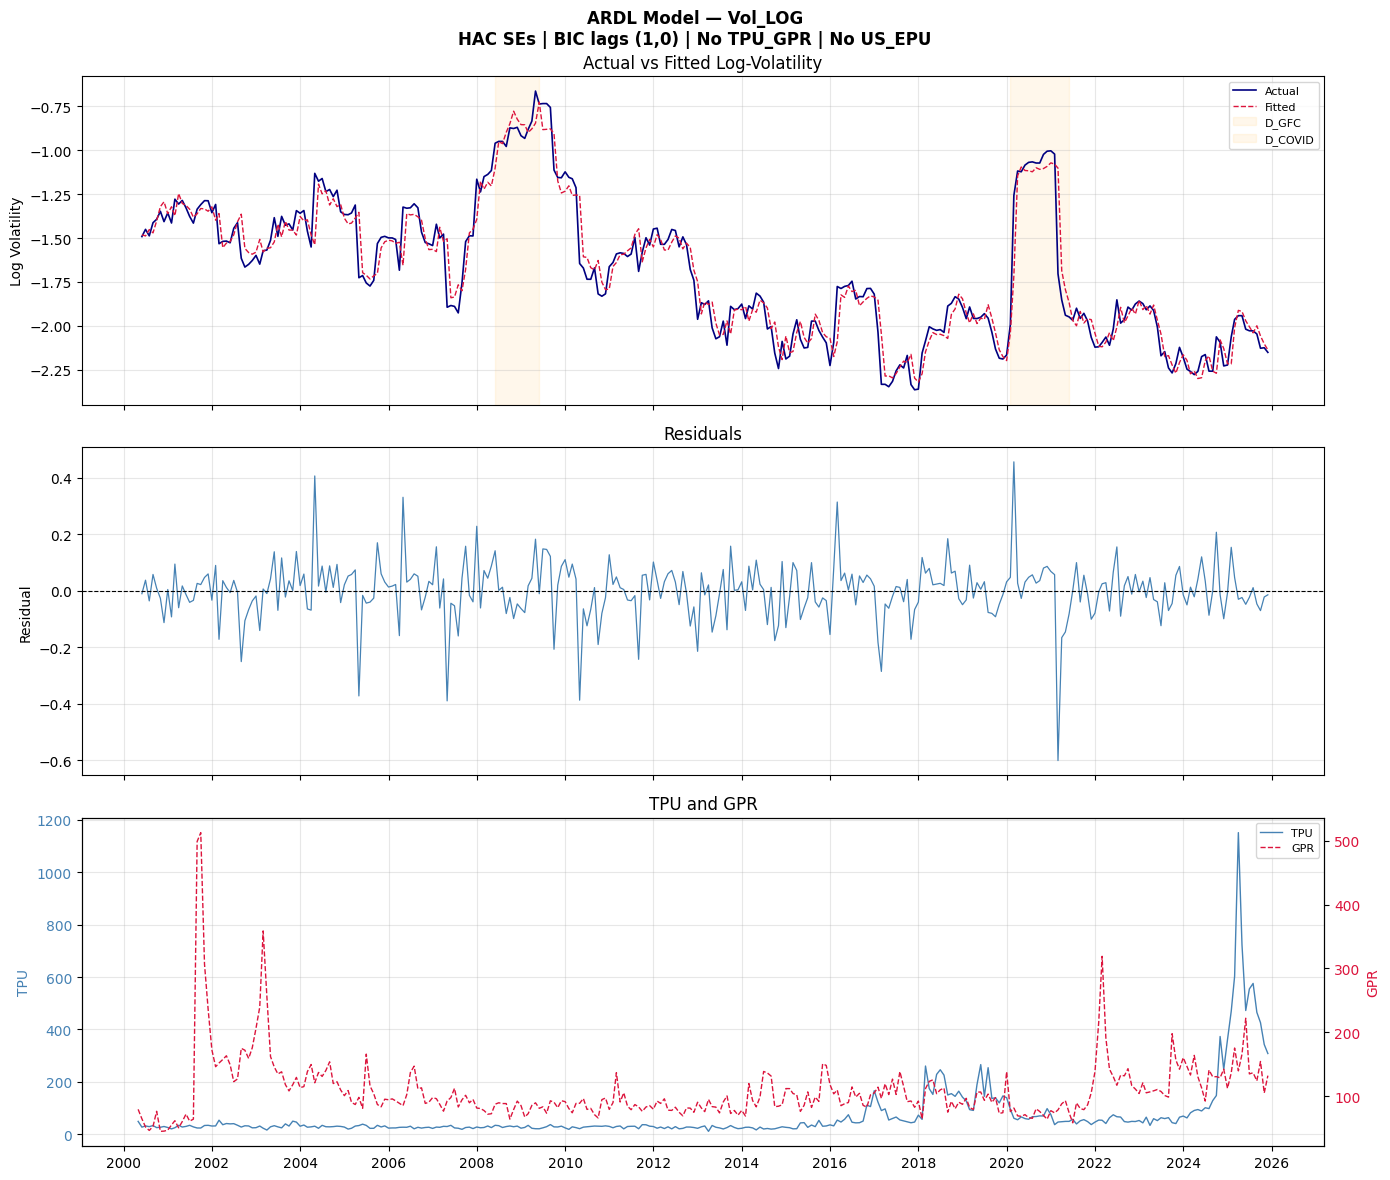

  Saved: ardl_results.png

  Done!


In [ ]:
"""
ARDL Model — Robust Specification
===================================
Changes from base version:
  - TPU_GPR interaction term removed
  - US_EPU removed from controls
  - BIC-optimal lag selection (replaces fixed Y_LAGS=2, X_LAGS=2)
  - HAC (Newey-West) standard errors (replaces HC3)
  - Log transformation of volatility (stabilises variance)
  - CUSUM structural stability test
  - Ramsey RESET functional form test
  - Dummies: D_GFC, D_COVID (period only, no point dummies)
Input  : Compiled0.xlsx
Output : ardl_robust_results.xlsx, ardl_results.png
"""

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import (het_breuschpagan,
                                           acorr_ljungbox,
                                           linear_reset,
                                           breaks_cusumolsresid)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════
# 0. DUMMY FUNCTIONS
# ════════════════════════════════════════════════════════════
def create_event_dummies(df_index):
    dummies = pd.DataFrame(index=df_index)
    period_events = {
        'D_GFC'   : ('2008-06', '2009-06'),
        'D_COVID' : ('2020-02', '2021-06'),
    }
    for name, (start, end) in period_events.items():
        dummies[name] = 0
        start = max(start, df_index.min().strftime('%Y-%m'))
        end   = min(end,   df_index.max().strftime('%Y-%m'))
        mask  = (df_index >= start) & (df_index <= end)
        dummies.loc[mask, name] = 1
    active  = dummies.columns[dummies.sum() > 0]
    dropped = list(set(dummies.columns) - set(active))
    if dropped:
        print(f"  Dropped (outside sample): {dropped}")
    return dummies[active]


def select_significant_dummies(y, X_base, dummies, alpha=0.10):
    print(f"\n  Dummy Selection (p < {alpha}):")
    print(f"  {'Dummy':<22} {'Coef':>10} {'p-value':>10} {'Keep':>6}")
    print("  " + "-" * 52)
    kept = []
    for col in dummies.columns:
        X_test = sm.add_constant(
            pd.concat([X_base, dummies[[col]]], axis=1).dropna()
        )
        y_test = y.reindex(X_test.index)
        try:
            r    = sm.OLS(y_test, X_test).fit()
            p    = r.pvalues.get(col, 1.0)
            co   = r.params.get(col, 0.0)
            keep = p < alpha
            print(f"  {col:<22} {co:>10.4f} {p:>10.4f} {'✓' if keep else '✗':>6}")
            if keep:
                kept.append(col)
        except Exception as e:
            print(f"  {col:<22} ERROR: {e}")
    print(f"\n  → Keeping {len(kept)} dummies: {kept}")
    return dummies[kept] if kept else pd.DataFrame(index=dummies.index)


def get_dummies_for_model(df, y_col, regressor_cols, alpha=0.10):
    df_clean = df[regressor_cols + [y_col]].dropna()
    y        = df_clean[y_col]
    X_base   = df_clean[regressor_cols]
    all_dummies = create_event_dummies(df_clean.index)
    sig_dummies = select_significant_dummies(y, X_base, all_dummies, alpha)
    return sig_dummies.reindex(df.index).fillna(0)


# ════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ════════════════════════════════════════════════════════════
df = pd.read_excel('Compiled0.xlsx')
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['Date']).sort_values('Date').set_index('Date')

vol_candidates = [c for c in df.columns
                  if 'Conditional_Vol' in c or 'Vol_GARCH' in c]
if not vol_candidates:
    raise ValueError("No volatility column found.")
VOL_RAW = vol_candidates[0]
print(f"  Raw volatility column : {VOL_RAW}")

# Log-transform volatility — stabilises variance, reduces skew
df['Vol_LOG'] = np.log(df[VOL_RAW])
VOL_COL = 'Vol_LOG'
print(f"  Dependent variable    : {VOL_COL} (log-transformed)")

# NO interaction term, NO US_EPU
CONTROLS   = ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap',
              'MPU', 'US_VIX']
REGRESSORS = ['TPU', 'GPR'] + CONTROLS

df = df.dropna(subset=[VOL_COL] + REGRESSORS)
print(f"  Sample : {df.index[0].date()} → {df.index[-1].date()}  (N={len(df)})")
print(f"  Regressors : {REGRESSORS}")

# ════════════════════════════════════════════════════════════
# 2. ADF STATIONARITY CHECK
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  ADF Tests — Integration Order")
print("=" * 65)
print(f"  {'Variable':<18} {'ADF Stat':>10} {'p-value':>10} {'Order':>8}")
print("  " + "-" * 50)

for col in [VOL_COL] + REGRESSORS:
    try:
        r     = adfuller(df[col].dropna(), autolag='AIC')
        order = 'I(0)' if r[1] < 0.05 else 'I(1)+'
        print(f"  {col:<18} {r[0]:>10.4f} {r[1]:>10.4f} {order:>8}")
    except Exception as e:
        print(f"  {col:<18} ERROR: {e}")

# ════════════════════════════════════════════════════════════
# 3. SIGNIFICANT DUMMIES
# ════════════════════════════════════════════════════════════
sig_dummies = get_dummies_for_model(df, VOL_COL, REGRESSORS, alpha=0.10)
dummy_cols  = list(sig_dummies.columns)
print(f"\n  Significant dummies : {dummy_cols}")

# ════════════════════════════════════════════════════════════
# 4. BIC-OPTIMAL LAG SELECTION
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  BIC-Optimal Lag Selection")
print("  Searching Y_LAGS ∈ {1,2,3}  X_LAGS ∈ {0,1,2,3}")
print("=" * 65)

best_bic  = np.inf
best_lags = (1, 1)

for yl in range(1, 4):
    for xl in range(0, 4):
        try:
            ardl_try = pd.DataFrame(index=df.index)
            ardl_try[VOL_COL] = df[VOL_COL]
            for lag in range(1, yl + 1):
                ardl_try[f'Y_L{lag}'] = df[VOL_COL].shift(lag)
            for var in REGRESSORS:
                ardl_try[var] = df[var]
                for lag in range(1, xl + 1):
                    ardl_try[f'{var}_L{lag}'] = df[var].shift(lag)
            for col in dummy_cols:
                ardl_try[col] = sig_dummies[col]
            ardl_try = ardl_try.dropna()
            Y_try    = ardl_try[VOL_COL]
            X_try    = sm.add_constant(ardl_try.drop(columns=[VOL_COL]))
            r_try    = sm.OLS(Y_try, X_try).fit()
            print(f"  Y_LAGS={yl}  X_LAGS={xl}  BIC={r_try.bic:.2f}"
                  f"{'  ← best' if r_try.bic < best_bic else ''}")
            if r_try.bic < best_bic:
                best_bic  = r_try.bic
                best_lags = (yl, xl)
        except Exception as e:
            print(f"  Y_LAGS={yl}  X_LAGS={xl}  ERROR: {e}")

Y_LAGS, X_LAGS = best_lags
print(f"\n  → Selected: Y_LAGS={Y_LAGS}  X_LAGS={X_LAGS}  BIC={best_bic:.2f}")

# ════════════════════════════════════════════════════════════
# 5. BUILD ARDL REGRESSOR MATRIX
# ════════════════════════════════════════════════════════════
ardl = pd.DataFrame(index=df.index)
ardl[VOL_COL] = df[VOL_COL]

for lag in range(1, Y_LAGS + 1):
    ardl[f'Y_L{lag}'] = df[VOL_COL].shift(lag)

for var in REGRESSORS:
    ardl[var] = df[var]
    for lag in range(1, X_LAGS + 1):
        ardl[f'{var}_L{lag}'] = df[var].shift(lag)

for col in dummy_cols:
    ardl[col] = sig_dummies[col]

ardl  = ardl.dropna()
Y_reg = ardl[VOL_COL]
X_reg = sm.add_constant(ardl.drop(columns=[VOL_COL]))

print(f"\n  ARDL({Y_LAGS}, {', '.join([str(X_LAGS)]*len(REGRESSORS))})")
print(f"  Observations after lag construction: {len(ardl)}")

# ════════════════════════════════════════════════════════════
# 6. OLS — HAC (NEWEY-WEST) STANDARD ERRORS
# ════════════════════════════════════════════════════════════
# HAC corrects both heteroskedasticity AND autocorrelation
# More appropriate than HC3 for monthly macro time series
# maxlags = 4 follows the √T rule of thumb
HAC_LAGS = 4
res = sm.OLS(Y_reg, X_reg).fit(cov_type='HAC',
                                cov_kwds={'maxlags': HAC_LAGS})

print("\n" + "=" * 65)
print(f"  ARDL RESULTS — HAC Robust SEs (Newey-West, lags={HAC_LAGS})")
print(f"  Dependent variable: {VOL_COL}")
print("=" * 65)
print(res.summary())

# ════════════════════════════════════════════════════════════
# 7. BOUNDS TEST (Pesaran 2001)
# ════════════════════════════════════════════════════════════
level_vars = [v for v in REGRESSORS if v in res.params.index]

try:
    wald   = res.wald_test(
        '(' + ', '.join([f'{v} = 0' for v in level_vars]) + ')',
        use_f=True
    )
    f_stat = float(wald.statistic)

    cv_table = {
        1:  (4.94, 5.73), 2:  (4.26, 5.02), 3:  (3.88, 4.61),
        4:  (3.74, 4.35), 5:  (3.35, 4.02), 6:  (3.15, 3.79),
        7:  (3.02, 3.62), 8:  (2.96, 3.49), 9:  (2.79, 3.37),
        10: (2.75, 3.27)
    }
    k        = min(len(level_vars), 10)
    I0_cv, I1_cv = cv_table[k]

    print("\n" + "=" * 65)
    print("  BOUNDS TEST — Pesaran et al. (2001)")
    print("=" * 65)
    print(f"  F-statistic            : {f_stat:.4f}")
    print(f"  k (level regressors)   : {k}")
    print(f"  Critical values (5%)   : I(0)={I0_cv}  I(1)={I1_cv}")

    if f_stat > I1_cv:
        conclusion = "REJECT H0 — Long-run relationship exists"
    elif f_stat < I0_cv:
        conclusion = "FAIL TO REJECT H0 — No long-run relationship"
    else:
        conclusion = "INCONCLUSIVE — F-stat within bounds"
    print(f"  → {conclusion}")

except Exception as e:
    print(f"  Bounds test error: {e}")
    f_stat = I0_cv = I1_cv = np.nan
    conclusion = "Could not compute"

# ════════════════════════════════════════════════════════════
# 8. LONG-RUN MULTIPLIERS
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  LONG-RUN MULTIPLIERS")
print("=" * 65)

y_lag_coefs = [res.params.get(f'Y_L{i}', 0) for i in range(1, Y_LAGS + 1)]
speed       = 1 - sum(y_lag_coefs)
print(f"  Speed of adjustment (denominator) : {speed:.4f}")

if speed < 0:
    half_life = np.log(0.5) / np.log(1 - speed)
    print(f"  Half-life of shock                : {half_life:.1f} months")

print(f"\n  {'Variable':<15} {'SR (contemp)':>15} {'LR Multiplier':>15}")
print("  " + "-" * 47)

lr_results = {}
for var in REGRESSORS:
    beta_sum = sum(
        res.params.get(var if lag == 0 else f'{var}_L{lag}', 0)
        for lag in range(0, X_LAGS + 1)
    )
    sr  = res.params.get(var, np.nan)
    lr  = beta_sum / speed if speed != 0 else np.nan
    lr_results[var] = lr
    print(f"  {var:<15} {sr:>15.5f} {lr:>15.5f}")

# ════════════════════════════════════════════════════════════
# 9. DIAGNOSTICS
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  DIAGNOSTICS")
print("=" * 65)

resid = res.resid
dw    = durbin_watson(resid)
lb    = acorr_ljungbox(resid, lags=12, return_df=True)
bp    = het_breuschpagan(resid, res.model.exog)

def tick(p, good_above=0.05):
    return '✓' if p > good_above else '⚠'

print(f"  Durbin-Watson              : {dw:.4f}  "
      f"{'✓' if 1.5 < dw < 2.5 else '⚠'}")
print(f"  Ljung-Box p (lag 12)       : {lb['lb_pvalue'].iloc[-1]:.4f}  "
      f"{tick(lb['lb_pvalue'].iloc[-1])}")
print(f"  Breusch-Pagan p            : {bp[1]:.4f}  {tick(bp[1])}")
print(f"  R-squared                  : {res.rsquared:.4f}")
print(f"  Adj R-squared              : {res.rsquared_adj:.4f}")
print(f"  AIC                        : {res.aic:.4f}")
print(f"  BIC                        : {res.bic:.4f}")

# CUSUM structural stability test
try:
    cusum_stat, cusum_pval, _ = breaks_cusumolsresid(res.resid)
    print(f"  CUSUM stability p          : {cusum_pval:.4f}  "
          f"{'✓ Stable' if cusum_pval > 0.05 else '⚠ Possible break'}")
except Exception as e:
    print(f"  CUSUM test                 : could not compute ({e})")
    cusum_pval = np.nan

# Ramsey RESET functional form test
try:
    reset     = linear_reset(res, power=2, use_f=True)
    reset_p   = reset.pvalue
    print(f"  Ramsey RESET p             : {reset_p:.4f}  "
          f"{'✓ No misspecification' if reset_p > 0.05 else '⚠ Functional form issue'}")
except Exception as e:
    print(f"  Ramsey RESET               : could not compute ({e})")
    reset_p = np.nan

# Normality of residuals
from scipy.stats import jarque_bera
jb_stat, jb_p = jarque_bera(resid)
print(f"  Jarque-Bera normality p    : {jb_p:.4f}  "
      f"{'✓' if jb_p > 0.05 else '⚠ Non-normal residuals'}")

# ════════════════════════════════════════════════════════════
# 10. COEFFICIENT TABLE
# ════════════════════════════════════════════════════════════
def stars(p):
    return '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else 'ns'))

coef_df = pd.DataFrame({
    'Parameter'   : res.params.index,
    'Coefficient' : res.params.values.round(6),
    'Std_Error'   : res.bse.values.round(6),
    'T_Stat'      : res.tvalues.values.round(4),
    'P_Value'     : res.pvalues.values.round(4),
    'Significance': [stars(p) for p in res.pvalues],
    'CI_Lower_95' : res.conf_int()[0].values.round(6),
    'CI_Upper_95' : res.conf_int()[1].values.round(6),
})

lr_df = pd.DataFrame({
    'Variable'      : list(lr_results.keys()),
    'SR_Contemp'    : [round(res.params.get(v, np.nan), 6)
                       for v in lr_results],
    'LR_Multiplier' : [round(v, 6) for v in lr_results.values()],
})

diag_df = pd.DataFrame({
    'Diagnostic': [
        'Dep_Variable', 'SE_Type', 'Y_LAGS', 'X_LAGS',
        'R2', 'Adj_R2', 'AIC', 'BIC',
        'Durbin_Watson', 'LjungBox_p12', 'BreuschPagan_p',
        'CUSUM_p', 'RESET_p', 'JarqueBera_p',
        'Bounds_F', 'Bounds_I0_cv', 'Bounds_I1_cv',
        'Bounds_conclusion', 'Speed_of_Adj', 'N'
    ],
    'Value': [
        VOL_COL, f'HAC Newey-West (lags={HAC_LAGS})', Y_LAGS, X_LAGS,
        round(res.rsquared, 4), round(res.rsquared_adj, 4),
        round(res.aic, 4), round(res.bic, 4),
        round(dw, 4), round(lb['lb_pvalue'].iloc[-1], 4), round(bp[1], 4),
        round(cusum_pval, 4) if not np.isnan(cusum_pval) else 'NA',
        round(reset_p, 4) if not np.isnan(reset_p) else 'NA',
        round(jb_p, 4),
        round(f_stat, 4) if not np.isnan(f_stat) else 'NA',
        I0_cv, I1_cv, conclusion,
        round(speed, 4), len(ardl)
    ]
})

# ════════════════════════════════════════════════════════════
# 11. SAVE TO EXCEL
# ════════════════════════════════════════════════════════════
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl import load_workbook
from openpyxl.utils import get_column_letter

OUTPUT = 'ardl_robust_results.xlsx'

fitted_df = pd.DataFrame({
    'Date'     : ardl.index,
    'Actual'   : Y_reg.values,
    'Fitted'   : res.fittedvalues.values,
    'Residuals': resid.values
})

with pd.ExcelWriter(OUTPUT, engine='openpyxl') as writer:
    coef_df.to_excel(writer,   sheet_name='Coefficients',     index=False)
    lr_df.to_excel(writer,     sheet_name='LongRun',          index=False)
    diag_df.to_excel(writer,   sheet_name='Diagnostics',      index=False)
    fitted_df.to_excel(writer, sheet_name='Fitted_Series',    index=False)
    ardl.to_excel(writer,      sheet_name='Data_Used')

# Format headers
wb = load_workbook(OUTPUT)
hf   = Font(bold=True, color='FFFFFF', name='Arial', size=10)
hfil = PatternFill('solid', start_color='1F4E79')
hal  = Alignment(horizontal='center')
for sn in wb.sheetnames:
    ws = wb[sn]
    for cell in ws[1]:
        cell.font = hf; cell.fill = hfil; cell.alignment = hal
    for col in ws.columns:
        w = max(len(str(c.value or '')) for c in col) + 3
        ws.column_dimensions[get_column_letter(col[0].column)].width = min(w, 40)
    ws.freeze_panes = 'A2'
wb.save(OUTPUT)
print(f"\n  Saved: {OUTPUT}")

# ════════════════════════════════════════════════════════════
# 12. PLOT
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle(f'ARDL Model — {VOL_COL}\n'
             f'HAC SEs | BIC lags ({Y_LAGS},{X_LAGS}) | No TPU_GPR | No US_EPU',
             fontsize=12, fontweight='bold')

# Actual vs Fitted
axes[0].plot(ardl.index, Y_reg.values,
             color='navy', linewidth=1.2, label='Actual')
axes[0].plot(ardl.index, res.fittedvalues.values,
             color='crimson', linewidth=1, linestyle='--', label='Fitted')
for col in dummy_cols:
    active = ardl.index[ardl[col] == 1]
    if len(active) > 0:
        axes[0].axvspan(active[0], active[-1],
                        alpha=0.08, color='orange', label=col)
axes[0].set_title('Actual vs Fitted Log-Volatility')
axes[0].set_ylabel('Log Volatility')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# Residuals
axes[1].plot(ardl.index, resid.values, color='steelblue', linewidth=0.9)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Residuals')
axes[1].set_ylabel('Residual')
axes[1].grid(True, alpha=0.3)

# TPU and GPR
ax2b = axes[2].twinx()
axes[2].plot(df.index, df['TPU'],
             color='steelblue', linewidth=1, label='TPU')
ax2b.plot(df.index, df['GPR'],
          color='crimson', linewidth=1, linestyle='--', label='GPR')
axes[2].set_title('TPU and GPR')
axes[2].set_ylabel('TPU', color='steelblue')
ax2b.set_ylabel('GPR', color='crimson')
axes[2].tick_params(axis='y', labelcolor='steelblue')
ax2b.tick_params(axis='y', labelcolor='crimson')
l1, lb1 = axes[2].get_legend_handles_labels()
l2, lb2 = ax2b.get_legend_handles_labels()
axes[2].legend(l1 + l2, lb1 + lb2, loc='upper right', fontsize=8)
axes[2].grid(True, alpha=0.3)

import matplotlib.dates as mdates
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('ardl_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: ardl_results.png")
print("\n  Done!")

**SVAR**

  SVAR — TPU, GPR, GARCH-X Volatility
  Sample : 2000-05-01 → 2025-12-01
  N      : 308

  ADF Tests:
  Variable           p-value    Order
  ------------------------------------
  TPU                 0.9807     I(1)
  GPR                 0.3695     I(1)
  Vol_GARCH           0.2212     I(1)

  Johansen Cointegration Test (3-variable system):
  H0: No cointegration among TPU, GPR, Vol_GARCH

  r ≤      Trace Stat        CV 5%          Result
  ------------------------------------------------
  0           53.9514      29.7961        Reject ✓
  1           17.4822      15.4943        Reject ✓
  2            4.5944       3.8415        Reject ✓

  → Cointegrating vectors found: 3
  ⚠ Cointegration found — VECM is more appropriate for this system
  → Proceeding with SVAR in levels as approximation
     (interpret IRFs with caution; see VECM code for full system)

  Model data: 308 observations

  Fitting VAR and selecting lag order...
  AIC optimal lag : 1
  BIC optimal lag : 1
  HQC optim

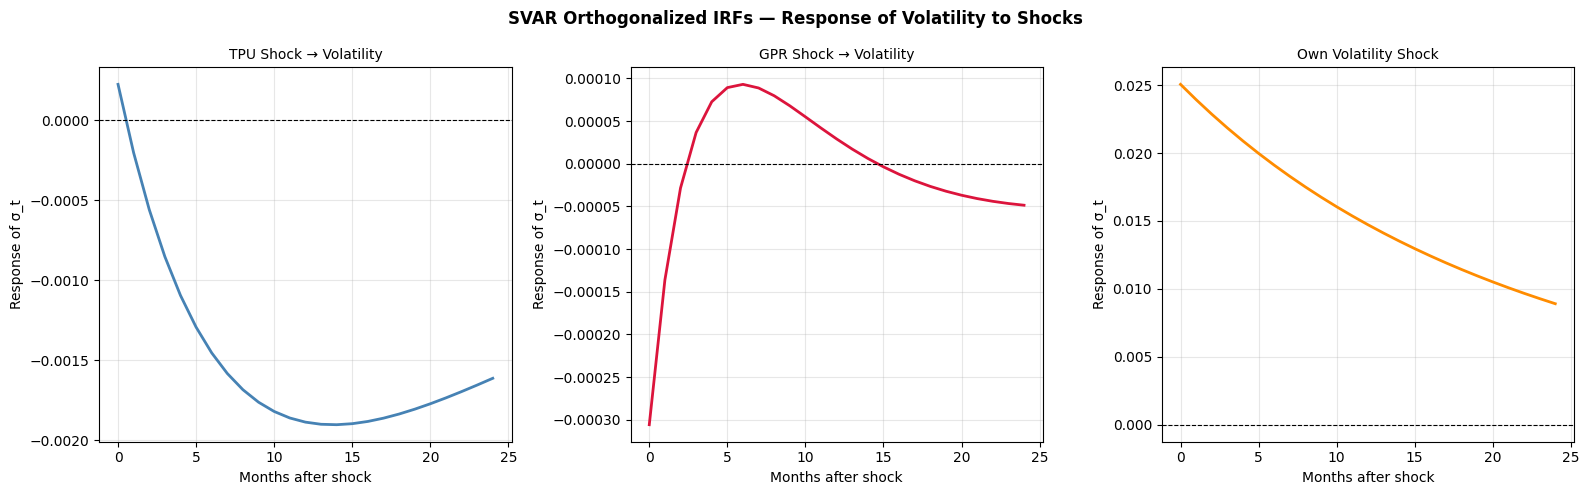

  Saved: svar_irf.png

  Forecast Error Variance Decomposition (Vol_GARCH):
          TPU   GPR  Vol_GARCH
Horizon                       
0        0.01  0.01      99.98
1        0.01  0.01      99.98
2        0.02  0.01      99.97
3        0.05  0.01      99.94
4        0.09  0.00      99.91
5        0.13  0.00      99.86
6        0.18  0.00      99.82
7        0.23  0.00      99.77
8        0.28  0.00      99.71
9        0.34  0.00      99.66
10       0.39  0.00      99.61
11       0.44  0.00      99.56
12       0.49  0.00      99.50
13       0.54  0.00      99.45
14       0.59  0.00      99.41
15       0.64  0.00      99.36
16       0.68  0.00      99.32
17       0.72  0.00      99.27
18       0.76  0.00      99.24
19       0.80  0.00      99.20
20       0.84  0.00      99.16
21       0.87  0.00      99.13
22       0.90  0.00      99.10
23       0.93  0.00      99.07

  Horizon 1M  — TPU: 0.01%  GPR: 0.01%  Vol: 99.98%
  Horizon 12M — TPU: 0.44%  GPR: 0.00%  Vol: 99.56%
  Horizon 24M

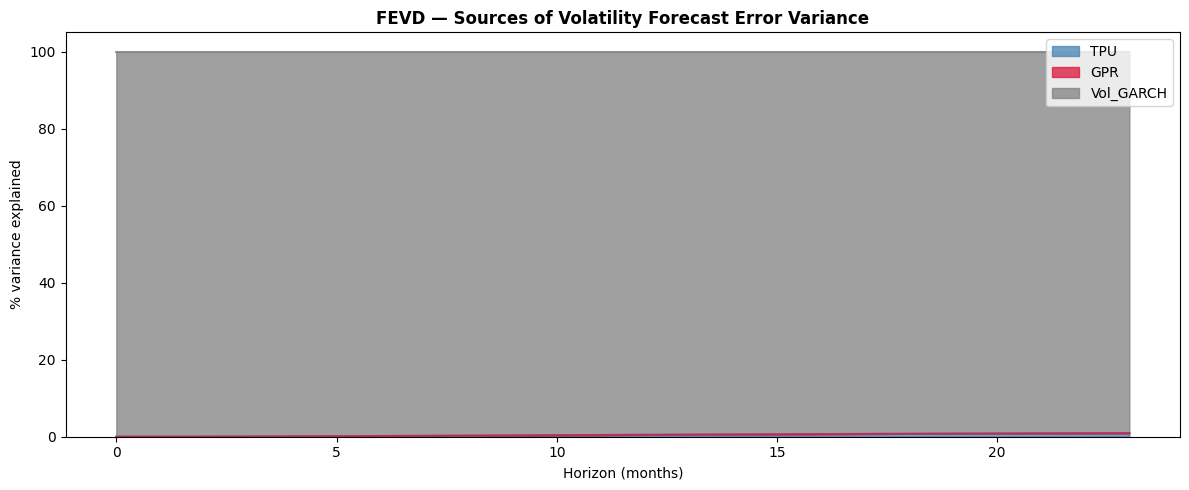

  Saved: svar_fevd.png

  Robustness — alternative ordering [GPR, TPU, Vol]:
  TPU→Vol peak  base: 0.000224  alt: 0.000208
  GPR→Vol peak  base: 0.000093  alt: 0.000169
  TPU ordering sensitivity: 0.000016 (Robust)
  GPR ordering sensitivity: 0.000076 (Robust)

  Saved: svar_3var_results.xlsx
  Done!


In [ ]:
"""
SVAR — TPU, GPR, GARCH-X Volatility (3-variable system)
=========================================================
Step 0 : Johansen cointegration test on just these 3 variables
Step 1 : If no cointegration → SVAR in levels (or differences if I(1))
Step 2 : Cholesky identification: TPU → GPR → Vol
Step 3 : IRFs, FEVD, robustness check (swap ordering)
Input  : compiled.xlsx
Output : svar_3var_results.xlsx, svar_irf.png, svar_fevd.png
"""

import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from scipy import linalg
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ════════════════════════════════════════════════════════════
df = pd.read_excel('Compiled0.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date']).sort_values('Date').set_index('Date')

vol_col = [c for c in df.columns if 'Conditional_Vol' in c or 'Vol_GARCH' in c]
if not vol_col:
    raise ValueError("No volatility column found.")
df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})

SVAR_VARS = ['TPU', 'GPR', 'Vol_GARCH']   # Cholesky order: TPU first, Vol last
df_svar   = df[SVAR_VARS].dropna()

print("=" * 60)
print("  SVAR — TPU, GPR, GARCH-X Volatility")
print("=" * 60)
print(f"  Sample : {df_svar.index.min().date()} → {df_svar.index.max().date()}")
print(f"  N      : {len(df_svar)}")

# ════════════════════════════════════════════════════════════
# 2. ADF STATIONARITY TEST
# ════════════════════════════════════════════════════════════
print("\n  ADF Tests:")
print(f"  {'Variable':<15} {'p-value':>10} {'Order':>8}")
print("  " + "-" * 36)

orders = {}
for v in SVAR_VARS:
    p = adfuller(df_svar[v].dropna(), autolag='AIC')[1]
    order = 'I(0)' if p < 0.05 else 'I(1)'
    orders[v] = order
    print(f"  {v:<15} {p:>10.4f} {order:>8}")

# ════════════════════════════════════════════════════════════
# 3. JOHANSEN COINTEGRATION TEST (on levels — only these 3 vars)
# ════════════════════════════════════════════════════════════
print("\n  Johansen Cointegration Test (3-variable system):")
print("  H0: No cointegration among TPU, GPR, Vol_GARCH")

joh = coint_johansen(df_svar, det_order=0, k_ar_diff=2)

print(f"\n  {'r ≤':<6} {'Trace Stat':>12} {'CV 5%':>12} {'Result':>15}")
print("  " + "-" * 48)

n_coint = 0
for i in range(len(joh.lr1)):
    trace  = joh.lr1[i]
    cv     = joh.cvt[i, 1]   # 5% critical value
    reject = trace > cv
    if reject:
        n_coint = i + 1
    print(f"  {i:<6} {trace:>12.4f} {cv:>12.4f} "
          f"{'Reject ✓' if reject else 'Fail to reject':>15}")

print(f"\n  → Cointegrating vectors found: {n_coint}")

if n_coint == 0:
    print("  → No cointegration — SVAR in levels/differences is valid")
    USE_LEVELS = all(v == 'I(0)' for v in orders.values())
    print(f"  → All I(0): {USE_LEVELS} — "
          f"{'using levels' if USE_LEVELS else 'differencing I(1) variables'}")
else:
    print("  ⚠ Cointegration found — VECM is more appropriate for this system")
    print("  → Proceeding with SVAR in levels as approximation")
    print("     (interpret IRFs with caution; see VECM code for full system)")
    USE_LEVELS = True

# ════════════════════════════════════════════════════════════
# 4. PREPARE DATA FOR VAR
# ════════════════════════════════════════════════════════════
df_model = pd.DataFrame(index=df_svar.index)

for v in SVAR_VARS:
    if USE_LEVELS or orders[v] == 'I(0)':
        df_model[v] = df_svar[v]
    else:
        df_model[v] = df_svar[v].diff()
        print(f"  {v}: first-differenced")

df_model = df_model.dropna()
print(f"\n  Model data: {len(df_model)} observations")

# ════════════════════════════════════════════════════════════
# 5. FIT REDUCED-FORM VAR
# ════════════════════════════════════════════════════════════
print("\n  Fitting VAR and selecting lag order...")
var_model = VAR(df_model)
lag_sel   = var_model.select_order(maxlags=12)

print(f"  AIC optimal lag : {lag_sel.aic}")
print(f"  BIC optimal lag : {lag_sel.bic}")
print(f"  HQC optimal lag : {lag_sel.hqic}")

opt_lag    = max(int(lag_sel.aic), 1)
var_result = var_model.fit(opt_lag)

print(f"\n  Fitted VAR({opt_lag})")
print(var_result.summary())

# ════════════════════════════════════════════════════════════
# 6. CHOLESKY IDENTIFICATION (SVAR)
# ════════════════════════════════════════════════════════════
# Ordering: TPU(0) → GPR(1) → Vol_GARCH(2)
# Economic justification:
#   TPU first  — trade policy driven by political cycles, exogenous to markets
#   GPR second — geopolitical risk exogenous but may react to trade policy
#   Vol last   — financial markets react instantly to TPU and GPR shocks
sigma_u = var_result.sigma_u
P       = linalg.cholesky(sigma_u, lower=True)

vol_idx = SVAR_VARS.index('Vol_GARCH')
tpu_idx = SVAR_VARS.index('TPU')
gpr_idx = SVAR_VARS.index('GPR')

print("\n" + "=" * 60)
print("  Structural Impact Matrix (Cholesky Lower Triangular P)")
print("=" * 60)
print(pd.DataFrame(P, columns=SVAR_VARS, index=SVAR_VARS).round(6))
print(f"\n  TPU shock → Vol  : {P[vol_idx, tpu_idx]:.6f}")
print(f"  GPR shock → Vol  : {P[vol_idx, gpr_idx]:.6f}")
print(f"  Vol own shock    : {P[vol_idx, vol_idx]:.6f}")

# ════════════════════════════════════════════════════════════
# 7. IMPULSE RESPONSE FUNCTIONS
# ════════════════════════════════════════════════════════════
print("\n  Computing IRFs (24 months)...")
IRF_PERIODS = 24
irf         = var_result.irf(periods=IRF_PERIODS)
periods     = np.arange(IRF_PERIODS + 1)

irf_tpu_vol = irf.orth_irfs[:, vol_idx, tpu_idx]
irf_gpr_vol = irf.orth_irfs[:, vol_idx, gpr_idx]
irf_vol_vol = irf.orth_irfs[:, vol_idx, vol_idx]

# Confidence bands via bootstrap
print("  Computing confidence bands (500 replications)...")
try:
    irf_err = irf.err_band_mc(orth=True, svar=False, repl=500, signif=0.05)
    lower_tpu = irf_err[0][:, vol_idx, tpu_idx]
    upper_tpu = irf_err[1][:, vol_idx, tpu_idx]
    lower_gpr = irf_err[0][:, vol_idx, gpr_idx]
    upper_gpr = irf_err[1][:, vol_idx, gpr_idx]
    has_bands = True
    print("  Confidence bands: OK")
except Exception as e:
    print(f"  ⚠ Confidence bands failed: {e}")
    has_bands = False

# ── IRF Plot ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('SVAR Orthogonalized IRFs — Response of Volatility to Shocks',
             fontsize=12, fontweight='bold')

plot_data = [
    (axes[0], irf_tpu_vol, 'steelblue',
     lower_tpu if has_bands else None,
     upper_tpu if has_bands else None,
     'TPU Shock → Volatility'),
    (axes[1], irf_gpr_vol, 'crimson',
     lower_gpr if has_bands else None,
     upper_gpr if has_bands else None,
     'GPR Shock → Volatility'),
    (axes[2], irf_vol_vol, 'darkorange',
     None, None,
     'Own Volatility Shock'),
]

for ax, irf_vals, color, lo, hi, title in plot_data:
    ax.plot(periods, irf_vals, color=color, linewidth=2)
    if lo is not None:
        ax.fill_between(periods, lo, hi, alpha=0.2, color=color)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Months after shock')
    ax.set_ylabel('Response of σ_t')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('svar_irf.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: svar_irf.png")

# ════════════════════════════════════════════════════════════
# 8. FEVD
# ════════════════════════════════════════════════════════════
print("\n  Forecast Error Variance Decomposition (Vol_GARCH):")
fevd    = var_result.fevd(periods=24)
fevd_df = pd.DataFrame(
    fevd.decomp[vol_idx] * 100,
    columns=SVAR_VARS
)
fevd_df.index.name = 'Horizon'
print(fevd_df.round(2).to_string())

print(f"\n  Horizon 1M  — TPU: {fevd_df['TPU'].iloc[0]:.2f}%  "
      f"GPR: {fevd_df['GPR'].iloc[0]:.2f}%  "
      f"Vol: {fevd_df['Vol_GARCH'].iloc[0]:.2f}%")
print(f"  Horizon 12M — TPU: {fevd_df['TPU'].iloc[11]:.2f}%  "
      f"GPR: {fevd_df['GPR'].iloc[11]:.2f}%  "
      f"Vol: {fevd_df['Vol_GARCH'].iloc[11]:.2f}%")
print(f"  Horizon 24M — TPU: {fevd_df['TPU'].iloc[23]:.2f}%  "
      f"GPR: {fevd_df['GPR'].iloc[23]:.2f}%  "
      f"Vol: {fevd_df['Vol_GARCH'].iloc[23]:.2f}%")

fig, ax = plt.subplots(figsize=(12, 5))
fevd_df.plot(kind='area', stacked=True, ax=ax,
             color=['steelblue', 'crimson', 'grey'], alpha=0.75)
ax.set_title('FEVD — Sources of Volatility Forecast Error Variance',
             fontweight='bold')
ax.set_xlabel('Horizon (months)')
ax.set_ylabel('% variance explained')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('svar_fevd.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: svar_fevd.png")

# ════════════════════════════════════════════════════════════
# 9. ROBUSTNESS — ALTERNATIVE CHOLESKY ORDERING
# ════════════════════════════════════════════════════════════
print("\n  Robustness — alternative ordering [GPR, TPU, Vol]:")
alt_vars   = ['GPR', 'TPU', 'Vol_GARCH']
var_alt    = VAR(df_model[alt_vars]).fit(opt_lag)
irf_alt    = var_alt.irf(periods=IRF_PERIODS)
irf_tpu_a  = irf_alt.orth_irfs[:, 2, 1]   # TPU→Vol in alt ordering
irf_gpr_a  = irf_alt.orth_irfs[:, 2, 0]   # GPR→Vol in alt ordering

print(f"  TPU→Vol peak  base: {irf_tpu_vol.max():.6f}  alt: {irf_tpu_a.max():.6f}")
print(f"  GPR→Vol peak  base: {irf_gpr_vol.max():.6f}  alt: {irf_gpr_a.max():.6f}")
diff_tpu = abs(irf_tpu_vol.max() - irf_tpu_a.max())
diff_gpr = abs(irf_gpr_vol.max() - irf_gpr_a.max())
print(f"  TPU ordering sensitivity: {diff_tpu:.6f} "
      f"({'Robust' if diff_tpu < 0.01 else 'Sensitive to ordering'})")
print(f"  GPR ordering sensitivity: {diff_gpr:.6f} "
      f"({'Robust' if diff_gpr < 0.01 else 'Sensitive to ordering'})")

# ════════════════════════════════════════════════════════════
# 10. SAVE RESULTS
# ════════════════════════════════════════════════════════════
irf_df = pd.DataFrame({
    'TPU_to_Vol' : irf_tpu_vol,
    'GPR_to_Vol' : irf_gpr_vol,
    'Vol_to_Vol' : irf_vol_vol,
}, index=periods)
irf_df.index.name = 'Horizon'

diag_df = pd.DataFrame({
    'Metric': ['Optimal_Lag_AIC', 'N_obs', 'N_coint_vectors',
               'TPU_Vol_Peak_IRF', 'GPR_Vol_Peak_IRF',
               'TPU_Vol_LR_FEVD', 'GPR_Vol_LR_FEVD'],
    'Value' : [opt_lag, len(df_model), n_coint,
               round(irf_tpu_vol.max(), 6), round(irf_gpr_vol.max(), 6),
               round(fevd_df['TPU'].iloc[23], 4),
               round(fevd_df['GPR'].iloc[23], 4)]
})

with pd.ExcelWriter('svar_3var_results.xlsx', engine='openpyxl') as writer:
    irf_df.to_excel(writer,  sheet_name='IRF_Values')
    fevd_df.to_excel(writer, sheet_name='FEVD')
    diag_df.to_excel(writer, sheet_name='Summary', index=False)
    df_model.to_excel(writer, sheet_name='Data_Used')

print("\n  Saved: svar_3var_results.xlsx")
print("  Done!")

**TVAR**

Columns: ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Vol_GARCH']
  TVP-VAR — GARCH-X Conditional Volatility
  Sample : 2000-06-01 to 2025-12-01
  N      : 307

  Running Kalman Filter...
  Log-likelihood (Q=0.005): -502.8423
  Log-likelihood (Q=0.001): -501.3327
  Log-likelihood (Q=0.020): -506.2005


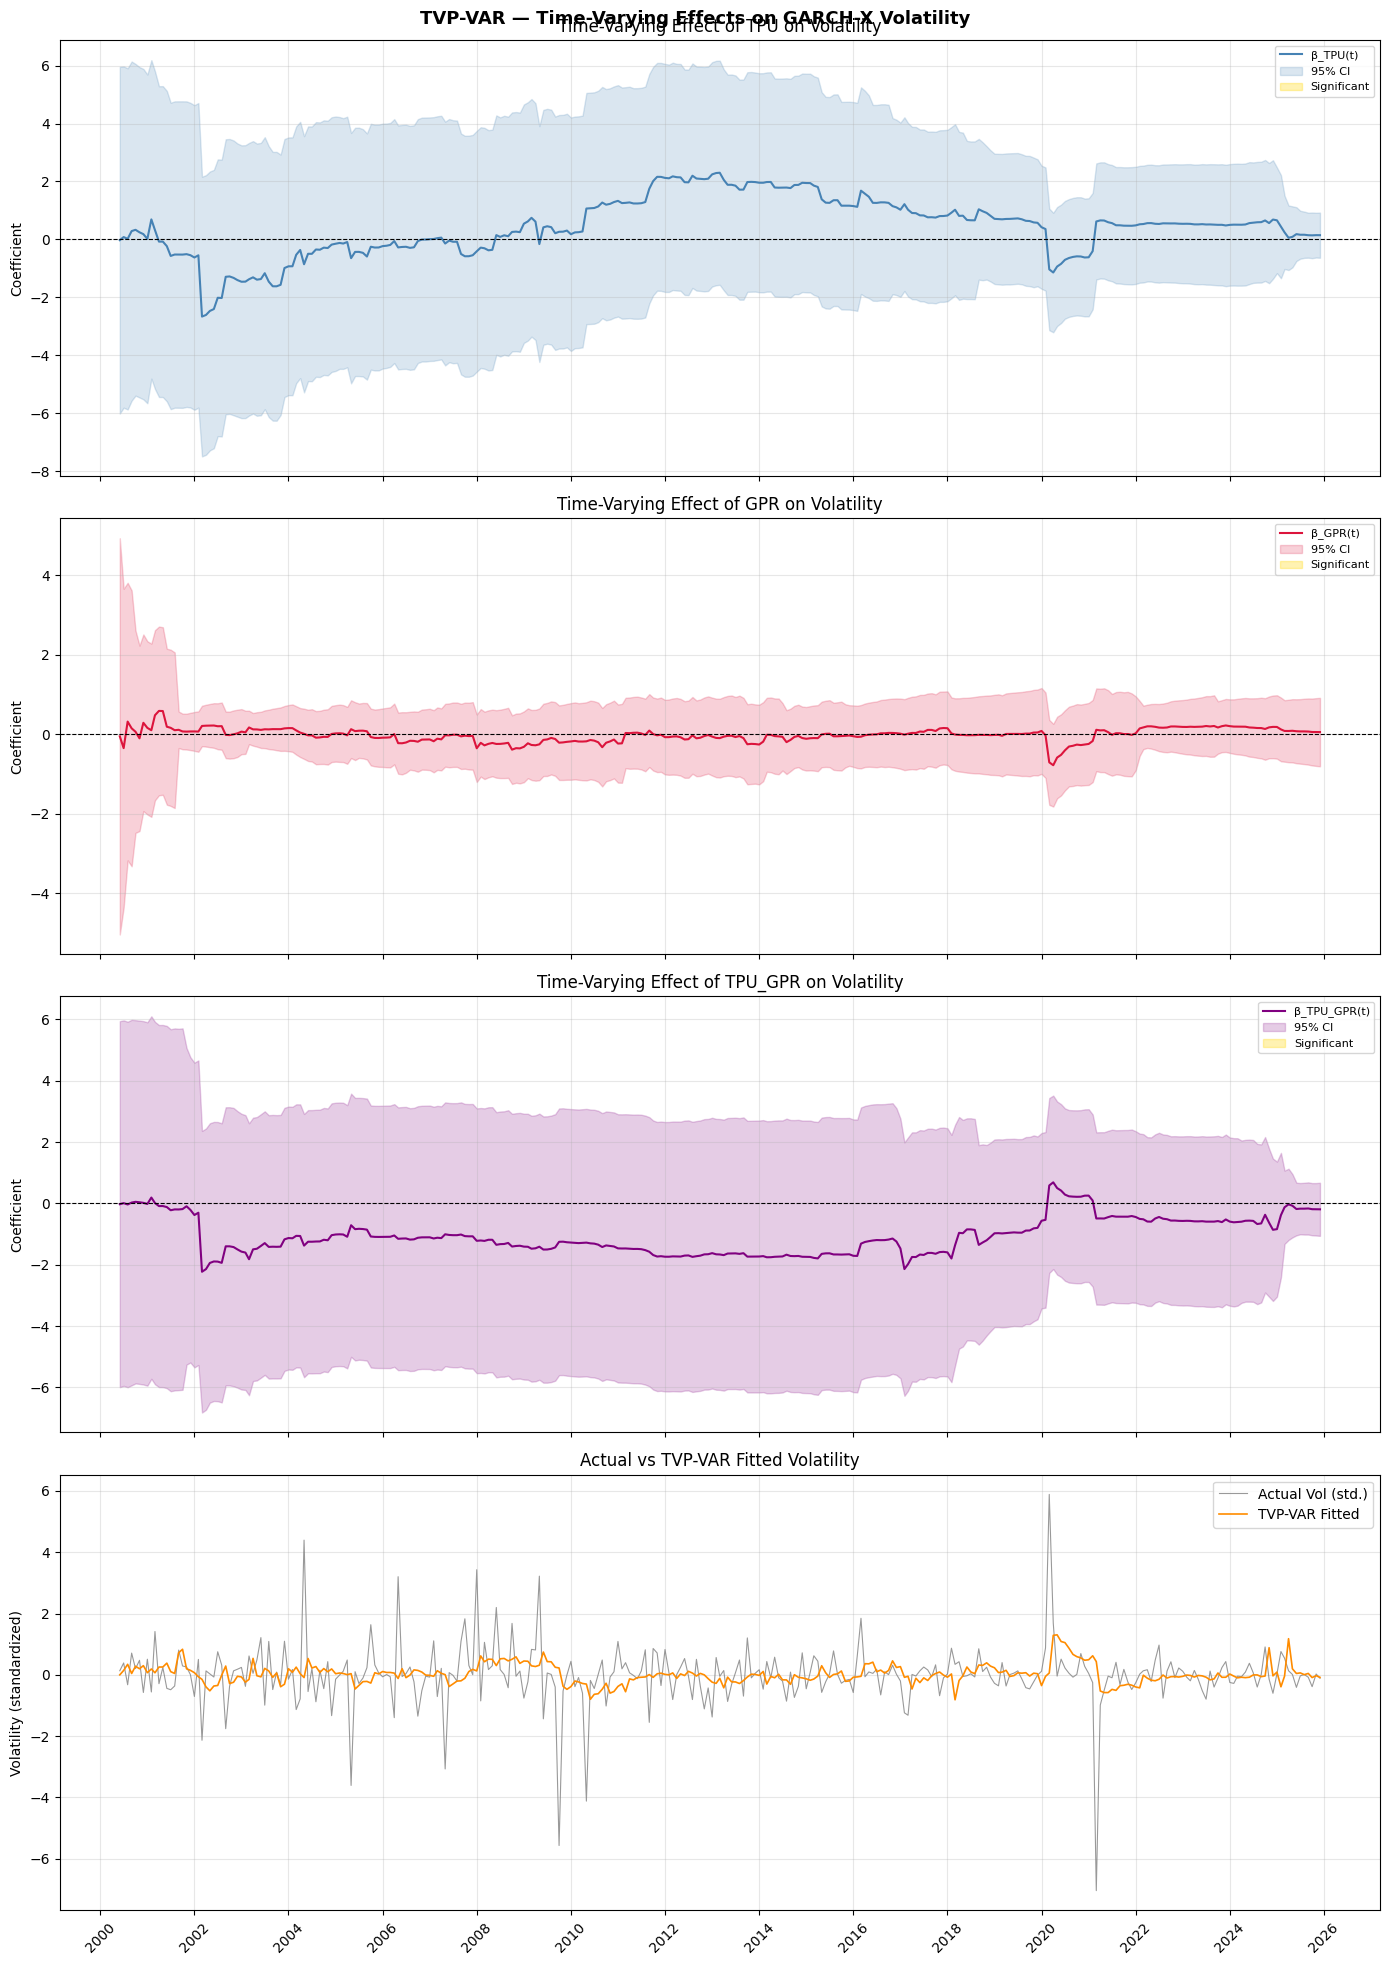


  REGIME ANALYSIS — Significant effect periods

  TPU:
    Significant positive: 0/307 months (0.0%)

  GPR:
    Significant positive: 0/307 months (0.0%)

  TPU_GPR:
    Significant positive: 0/307 months (0.0%)

  HISTORICAL CONTRIBUTION DECOMPOSITION
       Contrib_TPU  Contrib_GPR  Contrib_TPU_GPR  Contrib_Controls  Actual_Vol
count     307.0000     307.0000         307.0000          307.0000    307.0000
mean       -0.0153       0.0508           0.1821            0.0039     -0.0000
std         0.4728       0.1413           0.4149            0.1925      1.0016
min        -1.0702      -0.6640          -1.6748           -1.0474     -7.0390
25%        -0.2393      -0.0025          -0.0089           -0.0669     -0.2982
50%        -0.0076       0.0211           0.2956            0.0002      0.0122
75%         0.2045       0.0849           0.4643            0.0626      0.2574
max         1.7092       0.8305           0.7320            0.9922      5.8864


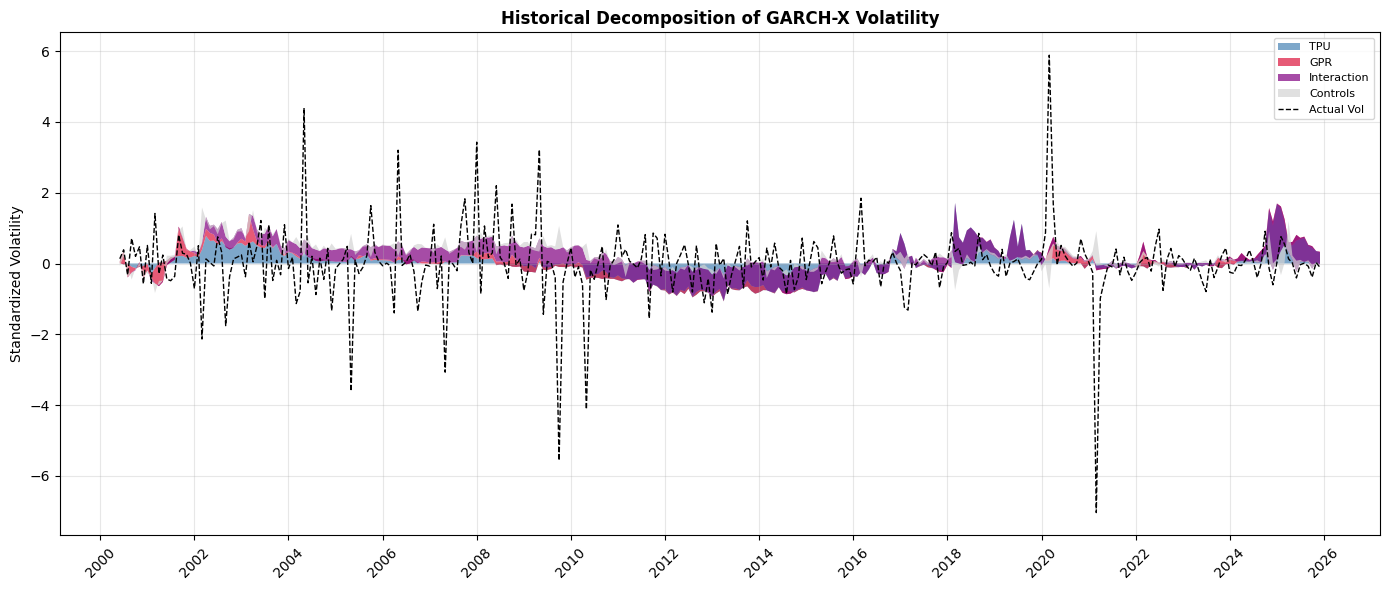


  Saved: tvp_var_results.xlsx
  Saved: tvp_var_plot.png
  Saved: tvp_historical_decomp.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ── LOAD ──────────────────────────────────────────────────────
df = pd.read_excel('stationary_variables.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values('Date').set_index('Date')

# Auto-detect volatility column
vol_col = [c for c in df.columns if 'Conditional_Vol' in c]
if vol_col:
    df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})
else:
    raise ValueError("No volatility column found.")

print("Columns:", df.columns.tolist())
print("=" * 60)
print("  TVP-VAR — GARCH-X Conditional Volatility")
print("=" * 60)
print(f"  Sample : {df.index.min().date()} to {df.index.max().date()}")
print(f"  N      : {len(df)}")

# ── INTERACTION TERM ──────────────────────────────────────────
df['TPU_GPR'] = df['TPU'] * df['GPR']

controls       = ['FX_USD', 'CPI_GR', 'Int_Rate',
                  'Output_Gap', 'MPU', 'US_EPU', 'US_VIX', 'US_VIX', 'MPU']
tvp_regressors = ['TPU', 'GPR', 'TPU_GPR']
all_cols       = tvp_regressors + ['Vol_GARCH']

df = df.dropna(subset=all_cols)

# ── STANDARDIZE ───────────────────────────────────────────────
scaler  = StandardScaler()
data_sc = pd.DataFrame(
    scaler.fit_transform(df[all_cols]),
    columns=all_cols,
    index=df.index
)

T   = len(data_sc)
vol = data_sc['Vol_GARCH'].values

X_raw = data_sc[tvp_regressors].values
X_tvp = np.column_stack([np.ones(T), X_raw])

reg_names = ['Intercept'] + tvp_regressors

# ── KALMAN FILTER ─────────────────────────────────────────────
def kalman_tvp(y, X, Q_scale=0.005, R_scale=0.5):
    T, k    = X.shape
    Q       = Q_scale * np.eye(k)
    R       = R_scale
    beta_tt = np.zeros(k)
    P_tt    = np.eye(k) * 10

    beta_store = np.zeros((T, k))
    P_store    = np.zeros((T, k, k))
    fitted     = np.zeros(T)
    ll         = 0.0

    for t in range(T):
        x_t       = X[t]
        beta_pred = beta_tt
        P_pred    = P_tt + Q
        y_hat     = x_t @ beta_pred
        innov     = y[t] - y_hat
        S         = float(x_t @ P_pred @ x_t) + R
        K         = P_pred @ x_t / S
        beta_tt   = beta_pred + K * innov
        P_tt      = (np.eye(k) - np.outer(K, x_t)) @ P_pred

        beta_store[t] = beta_tt
        P_store[t]    = P_tt
        fitted[t]     = y_hat
        ll           += -0.5 * (np.log(2 * np.pi * S) + innov**2 / S)

    return beta_store, P_store, fitted, ll

# ── RUN BASELINE ──────────────────────────────────────────────
print("\n  Running Kalman Filter...")
betas, Ps, fitted, loglik = kalman_tvp(vol, X_tvp, Q_scale=0.005, R_scale=0.5)
print(f"  Log-likelihood (Q=0.005): {loglik:.4f}")

# Sensitivity checks
_, _, _, ll_tight = kalman_tvp(vol, X_tvp, Q_scale=0.001, R_scale=0.5)
_, _, _, ll_loose = kalman_tvp(vol, X_tvp, Q_scale=0.020, R_scale=0.5)
print(f"  Log-likelihood (Q=0.001): {ll_tight:.4f}")
print(f"  Log-likelihood (Q=0.020): {ll_loose:.4f}")

# ── EXTRACT COEFFICIENTS AND SEs ─────────────────────────────
dates     = data_sc.index
coef_dict = {reg_names[i]: betas[:, i] for i in range(len(reg_names))}
se_dict   = {reg_names[i]: np.sqrt(Ps[:, i, i]) for i in range(len(reg_names))}

# ── PLOT TIME-VARYING COEFFICIENTS ───────────────────────────
focus_vars = ['TPU', 'GPR', 'TPU_GPR']
colors     = {'TPU': 'steelblue', 'GPR': 'crimson', 'TPU_GPR': 'purple'}

fig, axes = plt.subplots(len(focus_vars) + 1, 1,
                          figsize=(14, 5*(len(focus_vars)+1)),
                          sharex=True)
fig.suptitle('TVP-VAR — Time-Varying Effects on GARCH-X Volatility',
             fontsize=13, fontweight='bold')

for i, var in enumerate(focus_vars):
    b   = coef_dict[var]
    se  = se_dict[var]
    c   = colors[var]
    sig = b > 1.96 * se

    axes[i].plot(dates, b, color=c, linewidth=1.5, label=f'β_{var}(t)')
    axes[i].fill_between(dates, b - 1.96*se, b + 1.96*se,
                          alpha=0.2, color=c, label='95% CI')
    axes[i].fill_between(dates,
                          b - 1.96*se, b + 1.96*se,
                          where=sig, alpha=0.3, color='gold',
                          label='Significant')
    axes[i].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[i].set_title(f'Time-Varying Effect of {var} on Volatility')
    axes[i].set_ylabel('Coefficient')
    axes[i].legend(loc='upper right', fontsize=8)
    axes[i].grid(True, alpha=0.3)

# Actual vs fitted
axes[-1].plot(dates, vol,    color='grey',       linewidth=0.8,
              label='Actual Vol (std.)', alpha=0.8)
axes[-1].plot(dates, fitted, color='darkorange',  linewidth=1.2,
              label='TVP-VAR Fitted')
axes[-1].set_title('Actual vs TVP-VAR Fitted Volatility')
axes[-1].set_ylabel('Volatility (standardized)')
axes[-1].legend()
axes[-1].grid(True, alpha=0.3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('tvp_var_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# ── REGIME ANALYSIS ───────────────────────────────────────────
print("\n" + "=" * 60)
print("  REGIME ANALYSIS — Significant effect periods")
print("=" * 60)
for var in focus_vars:
    b   = coef_dict[var]
    se  = se_dict[var]
    sig = dates[b > 1.96 * se]
    pct = len(sig) / T * 100
    print(f"\n  {var}:")
    print(f"    Significant positive: {len(sig)}/{T} months ({pct:.1f}%)")
    if len(sig) > 0:
        print(f"    First: {sig[0].date()}  Last: {sig[-1].date()}")
        print(f"    Avg coef when significant: {b[b > 1.96*se].mean():.4f}")

# ── HISTORICAL DECOMPOSITION ──────────────────────────────────
print("\n" + "=" * 60)
print("  HISTORICAL CONTRIBUTION DECOMPOSITION")
print("=" * 60)

contrib = pd.DataFrame(index=dates)
for var in focus_vars:
    contrib[f'Contrib_{var}'] = coef_dict[var] * data_sc[var].values

contrib['Contrib_Controls'] = (
    fitted
    - coef_dict['Intercept']
    - sum(coef_dict[v] * data_sc[v].values for v in focus_vars)
)
contrib['Actual_Vol'] = vol
print(contrib.describe().round(4))

fig, ax = plt.subplots(figsize=(14, 6))
ax.stackplot(dates,
             contrib['Contrib_TPU'],
             contrib['Contrib_GPR'],
             contrib['Contrib_TPU_GPR'],
             contrib['Contrib_Controls'],
             labels=['TPU', 'GPR', 'Interaction', 'Controls'],
             colors=['steelblue', 'crimson', 'purple', 'lightgrey'],
             alpha=0.7)
ax.plot(dates, vol, color='black', linewidth=1,
        linestyle='--', label='Actual Vol')
ax.set_title('Historical Decomposition of GARCH-X Volatility',
             fontweight='bold')
ax.set_ylabel('Standardized Volatility')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('tvp_historical_decomp.png', dpi=150, bbox_inches='tight')
plt.show()

# ── SAVE ──────────────────────────────────────────────────────
tvp_out = pd.DataFrame({
    'Date'      : dates,
    'Actual_Vol': vol,
    'Fitted_Vol': fitted
})
for var in reg_names:
    tvp_out[f'Beta_{var}'] = coef_dict[var]
    tvp_out[f'SE_{var}']   = se_dict[var]
for col in contrib.columns:
    tvp_out[col] = contrib[col].values

tvp_out.to_excel('tvp_var_results.xlsx', index=False)
print("\n  Saved: tvp_var_results.xlsx")
print("  Saved: tvp_var_plot.png")
print("  Saved: tvp_historical_decomp.png")

In [ ]:
import os
import shutil

# Zip every file in the current directory
!zip -r research_outputs.zip . -i "*.xlsx" "*.png"

# Download it to your local machine
from google.colab import files
files.download('research_outputs.zip')

  adding: tvp_var_results.xlsx (deflated 1%)
  adding: ardl_robust_results.xlsx (deflated 2%)
  adding: ardl_results.png (deflated 5%)
  adding: svar_irf.png (deflated 13%)
  adding: tvp_var_plot.png (deflated 8%)
  adding: tvp_historical_decomp.png (deflated 6%)
  adding: vecm_results.xlsx (deflated 1%)
  adding: vecm_irf.png (deflated 14%)
  adding: svar_fevd.png (deflated 22%)
  adding: Compiled.xlsx (deflated 1%)
  adding: Compiled0.xlsx (deflated 1%)
  adding: nse_monthly_rolling_vol.xlsx (deflated 3%)
  adding: nse_monthly_vol_plot.png (deflated 10%)
  adding: stationary_variables.xlsx (deflated 2%)
  adding: stationarity_results.xlsx (deflated 10%)
  adding: ardl_with_dummies_results.xlsx (deflated 3%)
  adding: svar_3var_results.xlsx (deflated 4%)
  adding: ardl_final_results.xlsx (deflated 4%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Experiments**

**OLS on GArch X**

Sample: 1999-05-01 to 2025-12-01 | N=320

ADF Stationarity Tests (p < 0.05 = stationary):
  Vol     p = 0.0138  ✓ Stationary
  TPU     p = 0.9814  ✗ Non-stationary — consider differencing
  GPR     p = 0.0000  ✓ Stationary

Dependent variable : GARCH Conditional Volatility (σ_t)
Independent vars   : ['const', 'TPU', 'GPR', 'TPU_GPR', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

  OLS Regression Results
  σ_t = α + β₁TPU + β₂GPR + β₃(TPU×GPR) + ε
                            OLS Regression Results                            
Dep. Variable:                    Vol   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.614
Method:                 Least Squares   F-statistic:                     50.82
Date:                Mon, 20 Apr 2026   Prob (F-statistic):           2.14e-59
Time:                        00:35:54   Log-Likelihood:                -487.24
No. Observations:                 320   AIC:   

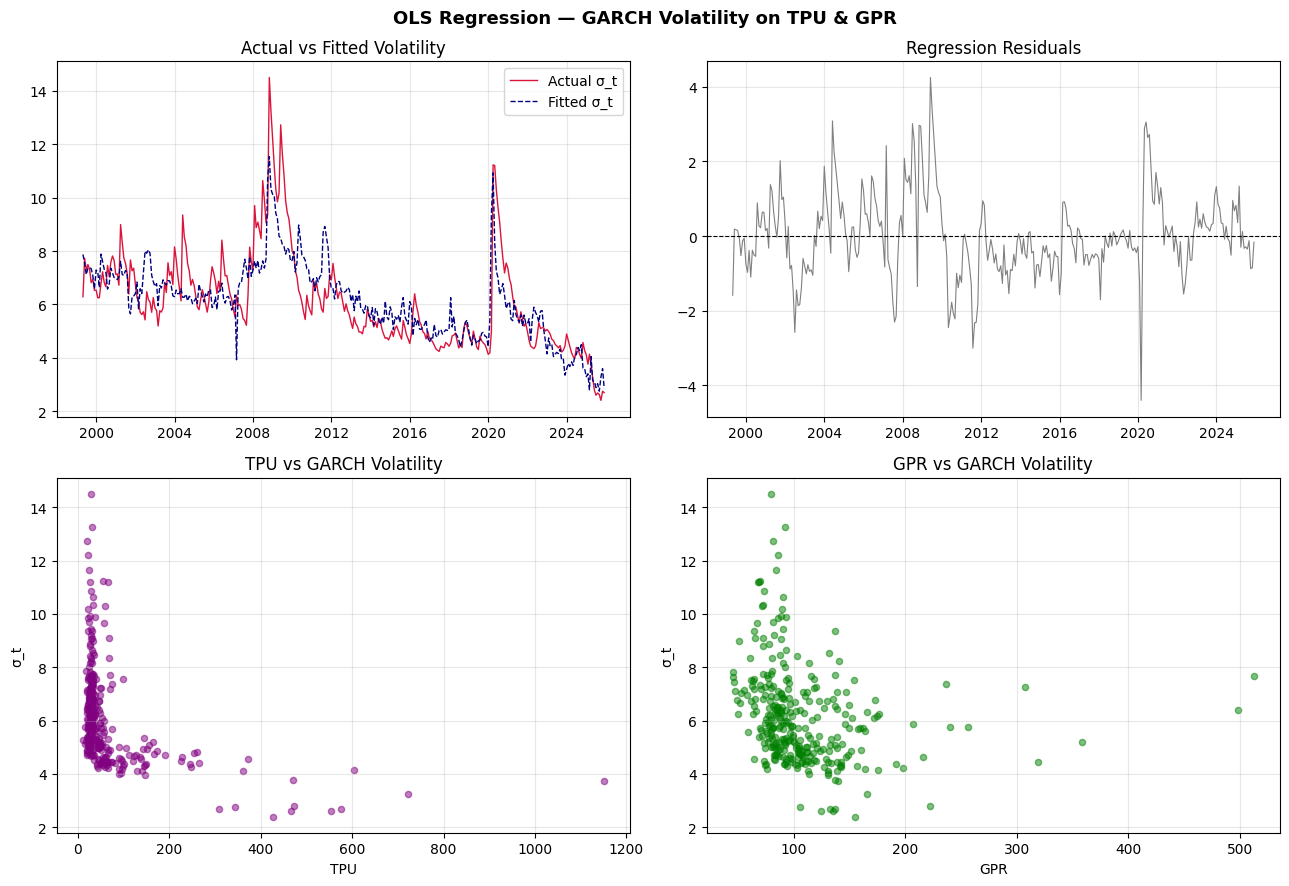

  Saved: regression_plot.png

Done!


In [ ]:
"""
STEP 2: OLS Regression — What drives GARCH volatility?
Uses σ_t from Step 1 as the dependent variable.

Model: σ_t = α + β₁TPU_t + β₂GPR_t + β₃(TPU_t×GPR_t) + X'γ + ε_t

Input:  garch_volatility.xlsx  (output from Step 1)
Output: regression_results.xlsx
"""

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ───────────────────────────────────────
INPUT_FILE  = 'Compiled.xlsx'   # output from Step 1
OUTPUT_FILE = 'regression_results.xlsx'
# ─────────────────────────────────────────────────

# ── Load Step 1 Output ───────────────────────────
df = pd.read_excel(INPUT_FILE, sheet_name='X_var (2)',
                   parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')
df = df.dropna()

# Rename for clarity
df = df.rename(columns={'Conditional_Vol_%_monthly': 'Vol'})

print(f"Sample: {df.index[0].date()} to {df.index[-1].date()} | N={len(df)}")

# ── Stationarity Check (ADF Test) ────────────────
# Important: OLS requires stationary series
print("\nADF Stationarity Tests (p < 0.05 = stationary):")
for col in ['Vol', 'TPU', 'GPR']:
    adf = adfuller(df[col].dropna())
    status = "✓ Stationary" if adf[1] < 0.05 else "✗ Non-stationary — consider differencing"
    print(f"  {col:<6}  p = {adf[1]:.4f}  {status}")

# ── Build Regression Variables ───────────────────
df['TPU_GPR'] = df['TPU'] * df['GPR']   # interaction term

# Dependent variable
Y = df['Vol']

# Independent variables
# Add or remove controls here as needed
controls = ['FX_USD','CPI_GR','Int_Rate','Output_Gap','MPU','US_EPU','US_VIX']
X = sm.add_constant(df[['TPU', 'GPR', 'TPU_GPR']+controls])

# If you have additional controls (e.g. VIX, inflation), add them:
# X = sm.add_constant(df[['TPU', 'GPR', 'TPU_GPR', 'VIX', 'CPI']])

print(f"\nDependent variable : GARCH Conditional Volatility (σ_t)")
print(f"Independent vars   : {list(X.columns)}")

# ── Run OLS ──────────────────────────────────────
model  = sm.OLS(Y, X)
result = model.fit(cov_type='HC3')   # HC3 = robust standard errors

print("\n" + "="*60)
print("  OLS Regression Results")
print("  σ_t = α + β₁TPU + β₂GPR + β₃(TPU×GPR) + ε")
print("="*60)
print(result.summary())

# ── Diagnostics ───────────────────────────────────
print("\n" + "="*45)
print("  Regression Diagnostics")
print("="*45)

# 1. Durbin-Watson (autocorrelation in residuals)
dw = durbin_watson(result.resid)
print(f"  Durbin-Watson      : {dw:.4f}  "
      f"({'✓ No autocorrelation' if 1.5<dw<2.5 else '⚠ Possible autocorrelation'})")

# 2. Breusch-Pagan (heteroskedasticity)
bp = het_breuschpagan(result.resid, result.model.exog)
print(f"  Breusch-Pagan      : p = {bp[1]:.4f}  "
      f"({'✓ Homoskedastic' if bp[1]>0.05 else '⚠ Heteroskedastic — HC3 SEs used'})")

# 3. R-squared
print(f"  R-squared          : {result.rsquared:.4f}")
print(f"  Adj. R-squared     : {result.rsquared_adj:.4f}")
print(f"  F-statistic p-val  : {result.f_pvalue:.4f}")

# ── Extract Key Coefficients ─────────────────────
def stars(p):
    return '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.10 else 'ns'))

print("\n" + "="*55)
print("  Key Coefficients Summary")
print("="*55)
print(f"  {'Variable':<15} {'Coef':>10} {'p-value':>10} {'Sig':>5}")
print("-"*55)
for var in ['const', 'TPU', 'GPR', 'TPU_GPR']:
    co = result.params[var]
    p  = result.pvalues[var]
    print(f"  {var:<15} {co:>10.4f} {p:>10.4f} {stars(p):>5}")

# Interpret interaction
tpu_gpr_coef = result.params['TPU_GPR']
tpu_gpr_p    = result.pvalues['TPU_GPR']
print(f"\n  Interaction (TPU×GPR): {tpu_gpr_coef:.4f} (p={tpu_gpr_p:.4f})")
if tpu_gpr_p < 0.05:
    direction = "amplifies" if tpu_gpr_coef > 0 else "dampens"
    print(f"  → Significant: combined TPU+GPR shock {direction} volatility")
else:
    print("  → Not significant: no interaction effect detected")

# ── Save to Excel ─────────────────────────────────
print(f"\nSaving to {OUTPUT_FILE}...")

# Fitted values and residuals
df['Fitted_Vol']  = result.fittedvalues
df['Residuals']   = result.resid

# Coefficient table
coef_table = pd.DataFrame({
    'Variable':    result.params.index,
    'Coefficient': result.params.values.round(6),
    'Std_Error':   result.bse.values.round(6),
    'T_Statistic': result.tvalues.values.round(4),
    'P_Value':     result.pvalues.values.round(4),
    'Significance':[stars(p) for p in result.pvalues],
    'CI_Lower':    result.conf_int()[0].values.round(6),
    'CI_Upper':    result.conf_int()[1].values.round(6),
})

# Diagnostics table
diag_table = pd.DataFrame({
    'Diagnostic':  ['R-squared', 'Adj R-squared', 'F-statistic',
                    'F p-value', 'Durbin-Watson',
                    'Breusch-Pagan p', 'Observations', 'SE Type'],
    'Value':       [round(result.rsquared, 4),
                    round(result.rsquared_adj, 4),
                    round(result.fvalue, 4),
                    round(result.f_pvalue, 4),
                    round(dw, 4),
                    round(bp[1], 4),
                    int(result.nobs),
                    'HC3 (heteroskedasticity-robust)'],
})

with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    df[['Vol','TPU','GPR','TPU_GPR',
        'Fitted_Vol','Residuals']].reset_index().to_excel(
        writer, sheet_name='Data_and_Fitted', index=False)
    coef_table.to_excel(
        writer, sheet_name='Coefficients', index=False)
    diag_table.to_excel(
        writer, sheet_name='Diagnostics', index=False)

    from openpyxl.styles import Font, PatternFill, Alignment
    hf    = Font(bold=True, color='FFFFFF')
    hfill = PatternFill('solid', start_color='1F4E79')
    for sn in writer.book.sheetnames:
        ws = writer.book[sn]
        for cell in ws[1]:
            cell.font = hf; cell.fill = hfill
            cell.alignment = Alignment(horizontal='center')
        for col in ws.columns:
            w = max(len(str(c.value or '')) for c in col) + 3
            ws.column_dimensions[col[0].column_letter].width = min(w, 35)

print(f"  Saved: {OUTPUT_FILE}")

# ── Plot ──────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('OLS Regression — GARCH Volatility on TPU & GPR',
             fontsize=13, fontweight='bold')

# Actual vs Fitted
axes[0,0].plot(df.index, df['Vol'],        label='Actual σ_t',
               color='crimson',  linewidth=1)
axes[0,0].plot(df.index, df['Fitted_Vol'], label='Fitted σ_t',
               color='navy', linewidth=1, linestyle='--')
axes[0,0].set_title('Actual vs Fitted Volatility')
axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

# Residuals
axes[0,1].plot(df.index, df['Residuals'],
               color='grey', linewidth=0.8)
axes[0,1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0,1].set_title('Regression Residuals')
axes[0,1].grid(True, alpha=0.3)

# TPU vs Vol
axes[1,0].scatter(df['TPU'], df['Vol'], alpha=0.5,
                  color='purple', s=20)
axes[1,0].set_xlabel('TPU'); axes[1,0].set_ylabel('σ_t')
axes[1,0].set_title('TPU vs GARCH Volatility')
axes[1,0].grid(True, alpha=0.3)

# GPR vs Vol
axes[1,1].scatter(df['GPR'], df['Vol'], alpha=0.5,
                  color='green', s=20)
axes[1,1].set_xlabel('GPR'); axes[1,1].set_ylabel('σ_t')
axes[1,1].set_title('GPR vs GARCH Volatility')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('regression_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: regression_plot.png")
print("\nDone!")

Columns: ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Vol_GARCH', 'NSE']
  TVP-VAR — GARCH-X Conditional Volatility
  Sample : 1999-05-01 to 2025-12-01
  N      : 320

  Running Kalman Filter...
  Log-likelihood (Q=0.005): -314.9139
  Log-likelihood (Q=0.001): -319.4308
  Log-likelihood (Q=0.020): -330.7307


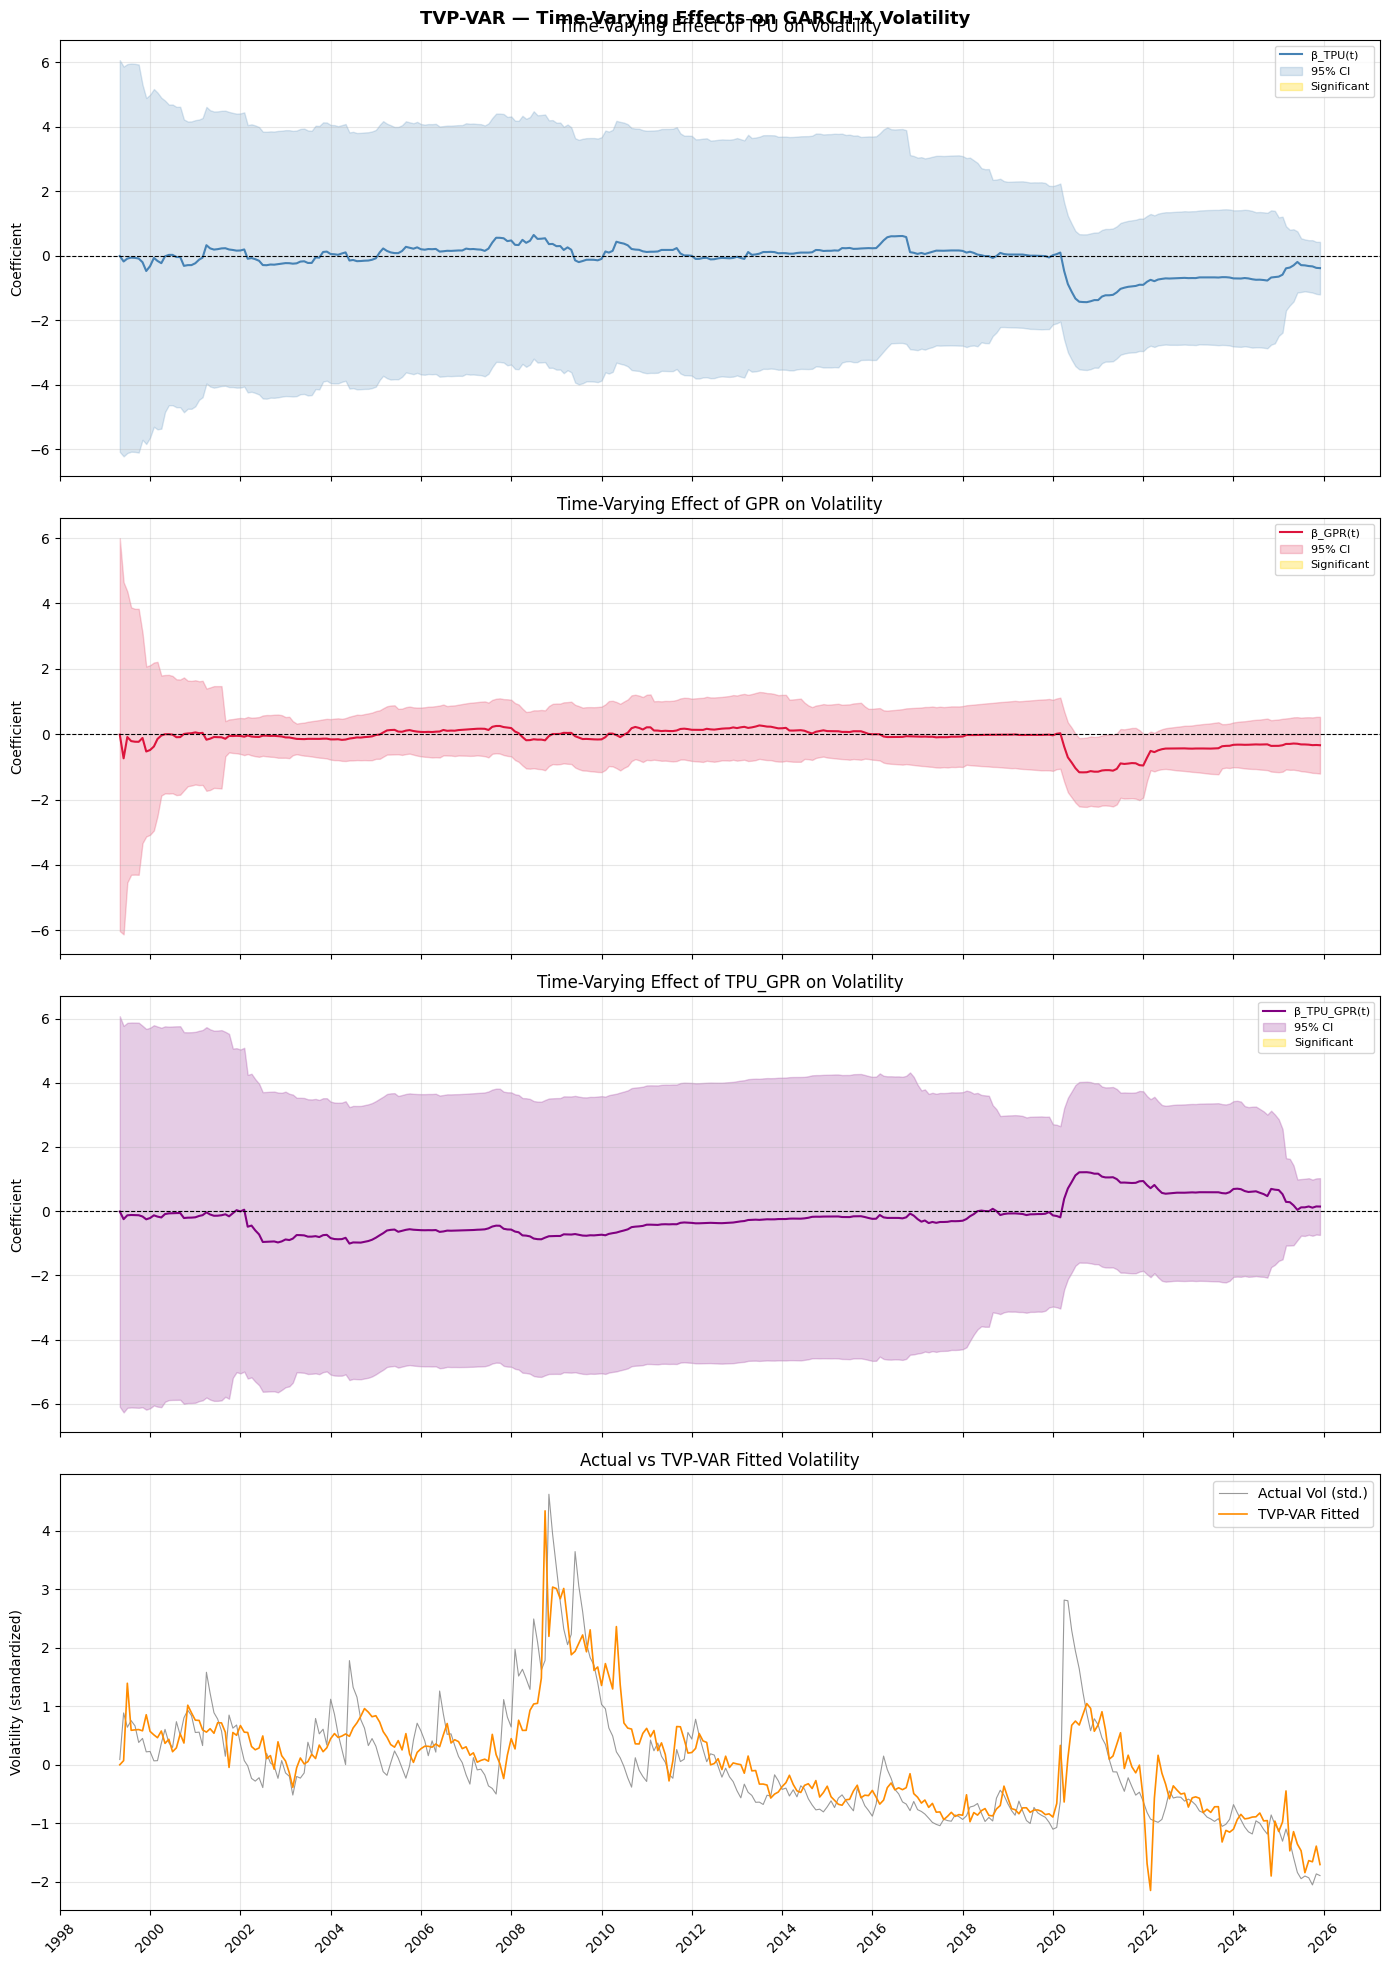


  REGIME ANALYSIS — Significant effect periods

  TPU:
    Significant positive: 0/320 months (0.0%)

  GPR:
    Significant positive: 0/320 months (0.0%)

  TPU_GPR:
    Significant positive: 0/320 months (0.0%)

  HISTORICAL CONTRIBUTION DECOMPOSITION
       Contrib_TPU  Contrib_GPR  Contrib_TPU_GPR  Contrib_Controls  Actual_Vol
count     320.0000     320.0000         320.0000          320.0000    320.0000
mean       -0.0771      -0.0195           0.1225            0.0598      0.0000
std         0.3552       0.2639           0.2724            0.4012      1.0016
min        -3.5643      -2.1242          -0.3531           -1.2349     -2.0522
25%        -0.0746      -0.0735           0.0163           -0.1596     -0.7004
50%        -0.0196      -0.0187           0.0907           -0.0128     -0.1893
75%         0.0388       0.0151           0.2037            0.1470      0.4660
max         0.3660       0.9699           2.5776            3.1336      4.6198


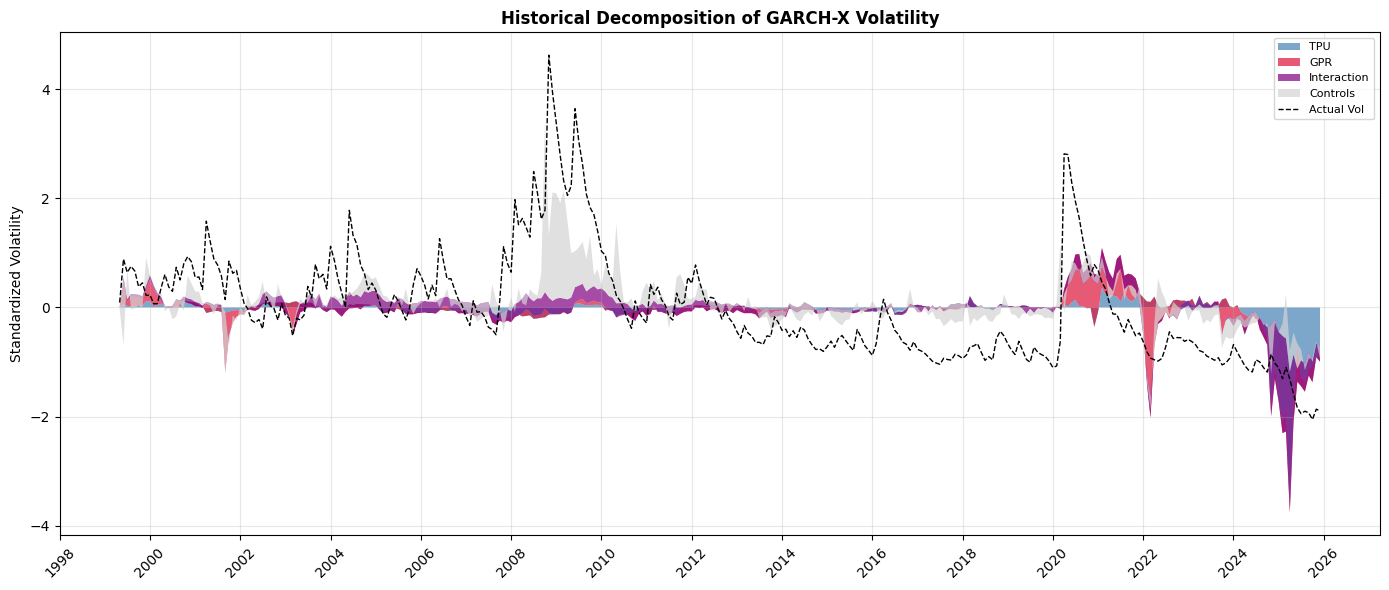


  Saved: tvp_var_results.xlsx
  Saved: tvp_var_plot.png
  Saved: tvp_historical_decomp.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ── LOAD ──────────────────────────────────────────────────────
df = pd.read_excel('Compiled.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values('Date').set_index('Date')

# Auto-detect volatility column
vol_col = [c for c in df.columns if 'Conditional_Vol' in c]
if vol_col:
    df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})
else:
    raise ValueError("No volatility column found.")

print("Columns:", df.columns.tolist())
print("=" * 60)
print("  TVP-VAR — GARCH-X Conditional Volatility")
print("=" * 60)
print(f"  Sample : {df.index.min().date()} to {df.index.max().date()}")
print(f"  N      : {len(df)}")

# ── INTERACTION TERM ──────────────────────────────────────────
df['TPU_GPR'] = df['TPU'] * df['GPR']

controls       = ['FX_USD', 'CPI_GR', 'Int_Rate',
                  'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']
tvp_regressors = ['TPU', 'GPR', 'TPU_GPR', 'US_VIX', 'MPU']
all_cols       = tvp_regressors + ['Vol_GARCH']

df = df.dropna(subset=all_cols)

# ── STANDARDIZE ───────────────────────────────────────────────
scaler  = StandardScaler()
data_sc = pd.DataFrame(
    scaler.fit_transform(df[all_cols]),
    columns=all_cols,
    index=df.index
)

T   = len(data_sc)
vol = data_sc['Vol_GARCH'].values

X_raw = data_sc[tvp_regressors].values
X_tvp = np.column_stack([np.ones(T), X_raw])

reg_names = ['Intercept'] + tvp_regressors

# ── KALMAN FILTER ─────────────────────────────────────────────
def kalman_tvp(y, X, Q_scale=0.005, R_scale=0.5):
    T, k    = X.shape
    Q       = Q_scale * np.eye(k)
    R       = R_scale
    beta_tt = np.zeros(k)
    P_tt    = np.eye(k) * 10

    beta_store = np.zeros((T, k))
    P_store    = np.zeros((T, k, k))
    fitted     = np.zeros(T)
    ll         = 0.0

    for t in range(T):
        x_t       = X[t]
        beta_pred = beta_tt
        P_pred    = P_tt + Q
        y_hat     = x_t @ beta_pred
        innov     = y[t] - y_hat
        S         = float(x_t @ P_pred @ x_t) + R
        K         = P_pred @ x_t / S
        beta_tt   = beta_pred + K * innov
        P_tt      = (np.eye(k) - np.outer(K, x_t)) @ P_pred

        beta_store[t] = beta_tt
        P_store[t]    = P_tt
        fitted[t]     = y_hat
        ll           += -0.5 * (np.log(2 * np.pi * S) + innov**2 / S)

    return beta_store, P_store, fitted, ll

# ── RUN BASELINE ──────────────────────────────────────────────
print("\n  Running Kalman Filter...")
betas, Ps, fitted, loglik = kalman_tvp(vol, X_tvp, Q_scale=0.005, R_scale=0.5)
print(f"  Log-likelihood (Q=0.005): {loglik:.4f}")

# Sensitivity checks
_, _, _, ll_tight = kalman_tvp(vol, X_tvp, Q_scale=0.001, R_scale=0.5)
_, _, _, ll_loose = kalman_tvp(vol, X_tvp, Q_scale=0.020, R_scale=0.5)
print(f"  Log-likelihood (Q=0.001): {ll_tight:.4f}")
print(f"  Log-likelihood (Q=0.020): {ll_loose:.4f}")

# ── EXTRACT COEFFICIENTS AND SEs ─────────────────────────────
dates     = data_sc.index
coef_dict = {reg_names[i]: betas[:, i] for i in range(len(reg_names))}
se_dict   = {reg_names[i]: np.sqrt(Ps[:, i, i]) for i in range(len(reg_names))}

# ── PLOT TIME-VARYING COEFFICIENTS ───────────────────────────
focus_vars = ['TPU', 'GPR', 'TPU_GPR']
colors     = {'TPU': 'steelblue', 'GPR': 'crimson', 'TPU_GPR': 'purple'}

fig, axes = plt.subplots(len(focus_vars) + 1, 1,
                          figsize=(14, 5*(len(focus_vars)+1)),
                          sharex=True)
fig.suptitle('TVP-VAR — Time-Varying Effects on GARCH-X Volatility',
             fontsize=13, fontweight='bold')

for i, var in enumerate(focus_vars):
    b   = coef_dict[var]
    se  = se_dict[var]
    c   = colors[var]
    sig = b > 1.96 * se

    axes[i].plot(dates, b, color=c, linewidth=1.5, label=f'β_{var}(t)')
    axes[i].fill_between(dates, b - 1.96*se, b + 1.96*se,
                          alpha=0.2, color=c, label='95% CI')
    axes[i].fill_between(dates,
                          b - 1.96*se, b + 1.96*se,
                          where=sig, alpha=0.3, color='gold',
                          label='Significant')
    axes[i].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[i].set_title(f'Time-Varying Effect of {var} on Volatility')
    axes[i].set_ylabel('Coefficient')
    axes[i].legend(loc='upper right', fontsize=8)
    axes[i].grid(True, alpha=0.3)

# Actual vs fitted
axes[-1].plot(dates, vol,    color='grey',       linewidth=0.8,
              label='Actual Vol (std.)', alpha=0.8)
axes[-1].plot(dates, fitted, color='darkorange',  linewidth=1.2,
              label='TVP-VAR Fitted')
axes[-1].set_title('Actual vs TVP-VAR Fitted Volatility')
axes[-1].set_ylabel('Volatility (standardized)')
axes[-1].legend()
axes[-1].grid(True, alpha=0.3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('tvp_var_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# ── REGIME ANALYSIS ───────────────────────────────────────────
print("\n" + "=" * 60)
print("  REGIME ANALYSIS — Significant effect periods")
print("=" * 60)
for var in focus_vars:
    b   = coef_dict[var]
    se  = se_dict[var]
    sig = dates[b > 1.96 * se]
    pct = len(sig) / T * 100
    print(f"\n  {var}:")
    print(f"    Significant positive: {len(sig)}/{T} months ({pct:.1f}%)")
    if len(sig) > 0:
        print(f"    First: {sig[0].date()}  Last: {sig[-1].date()}")
        print(f"    Avg coef when significant: {b[b > 1.96*se].mean():.4f}")

# ── HISTORICAL DECOMPOSITION ──────────────────────────────────
print("\n" + "=" * 60)
print("  HISTORICAL CONTRIBUTION DECOMPOSITION")
print("=" * 60)

contrib = pd.DataFrame(index=dates)
for var in focus_vars:
    contrib[f'Contrib_{var}'] = coef_dict[var] * data_sc[var].values

contrib['Contrib_Controls'] = (
    fitted
    - coef_dict['Intercept']
    - sum(coef_dict[v] * data_sc[v].values for v in focus_vars)
)
contrib['Actual_Vol'] = vol
print(contrib.describe().round(4))

fig, ax = plt.subplots(figsize=(14, 6))
ax.stackplot(dates,
             contrib['Contrib_TPU'],
             contrib['Contrib_GPR'],
             contrib['Contrib_TPU_GPR'],
             contrib['Contrib_Controls'],
             labels=['TPU', 'GPR', 'Interaction', 'Controls'],
             colors=['steelblue', 'crimson', 'purple', 'lightgrey'],
             alpha=0.7)
ax.plot(dates, vol, color='black', linewidth=1,
        linestyle='--', label='Actual Vol')
ax.set_title('Historical Decomposition of GARCH-X Volatility',
             fontweight='bold')
ax.set_ylabel('Standardized Volatility')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('tvp_historical_decomp.png', dpi=150, bbox_inches='tight')
plt.show()

# ── SAVE ──────────────────────────────────────────────────────
tvp_out = pd.DataFrame({
    'Date'      : dates,
    'Actual_Vol': vol,
    'Fitted_Vol': fitted
})
for var in reg_names:
    tvp_out[f'Beta_{var}'] = coef_dict[var]
    tvp_out[f'SE_{var}']   = se_dict[var]
for col in contrib.columns:
    tvp_out[col] = contrib[col].values

tvp_out.to_excel('tvp_var_results.xlsx', index=False)
print("\n  Saved: tvp_var_results.xlsx")
print("  Saved: tvp_var_plot.png")
print("  Saved: tvp_historical_decomp.png")

OLS on Stationary data

Sample: 2000-06-01 to 2025-12-01 | N=307

ADF Stationarity Tests (p < 0.05 = stationary):
  Vol     p = 0.0000  ✓ Stationary
  TPU     p = 0.9806  ✗ Non-stationary — consider differencing
  GPR     p = 0.2600  ✗ Non-stationary — consider differencing

Dependent variable : GARCH Conditional Volatility (σ_t)
Independent vars   : ['const', 'TPU', 'GPR', 'TPU_GPR', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

  OLS Regression Results
  σ_t = α + β₁TPU + β₂GPR + β₃(TPU×GPR) + ε
                            OLS Regression Results                            
Dep. Variable:                    Vol   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     1.104
Date:                Thu, 23 Apr 2026   Prob (F-statistic):              0.359
Time:                        03:45:16   Log-Likelihood:                 708.37
No. Observations:  

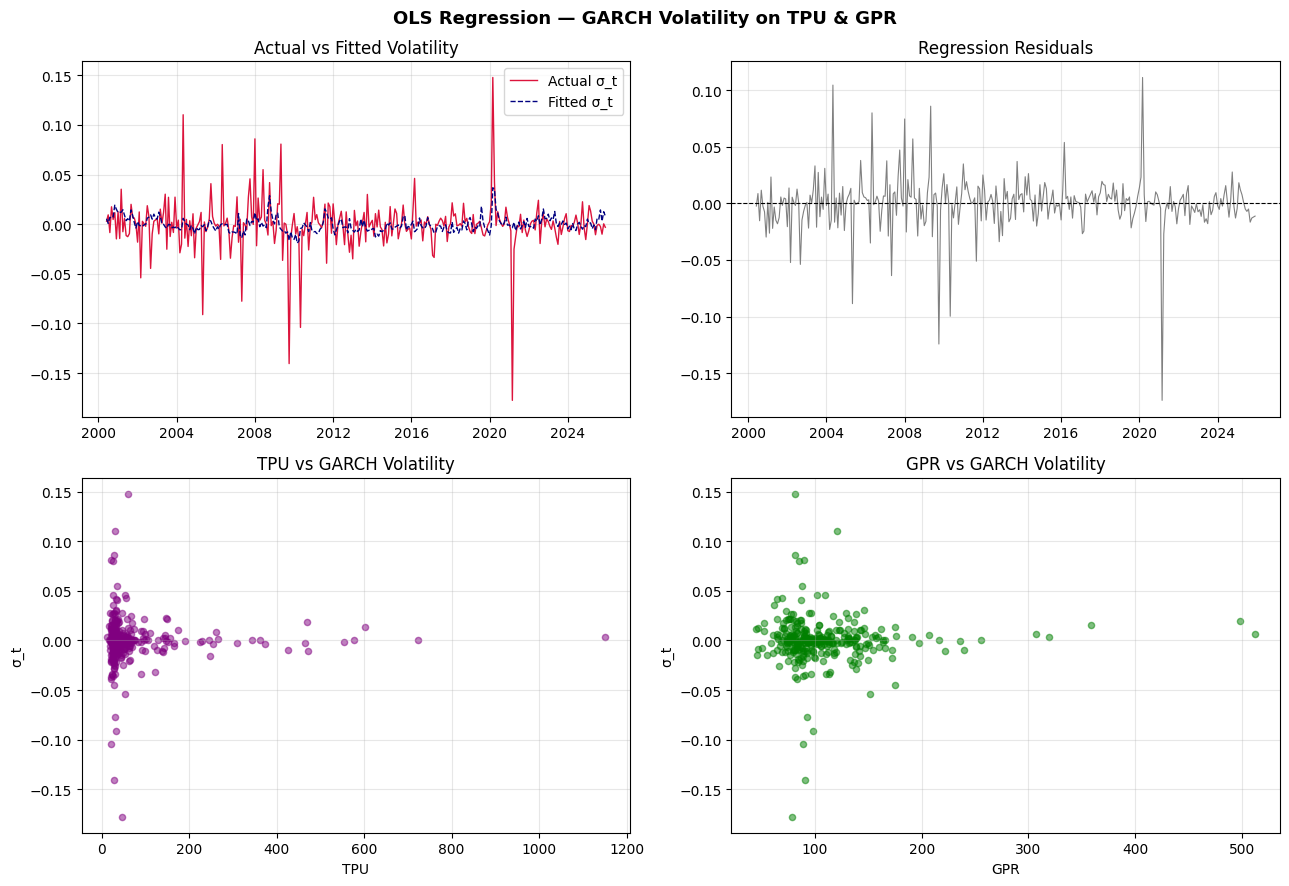

  Saved: regression_plot.png

Done!


In [ ]:
"""
STEP 2: OLS Regression — What drives GARCH volatility?
Uses σ_t from Step 1 as the dependent variable.

Model: σ_t = α + β₁TPU_t + β₂GPR_t + β₃(TPU_t×GPR_t) + X'γ + ε_t

Input:  garch_volatility.xlsx  (output from Step 1)
Output: regression_results.xlsx
"""

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ───────────────────────────────────────
INPUT_FILE  = 'stationary_variables.xlsx'   # output from Step 1
OUTPUT_FILE = 'regression_results_stnry.xlsx'
# ─────────────────────────────────────────────────

# ── Load Step 1 Output ───────────────────────────
df = pd.read_excel(INPUT_FILE, sheet_name='Sheet2',
                   parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')
df = df.dropna()

# Rename for clarity
df = df.rename(columns={'Conditional_Vol_%_monthly': 'Vol'})

print(f"Sample: {df.index[0].date()} to {df.index[-1].date()} | N={len(df)}")

# ── Stationarity Check (ADF Test) ────────────────
# Important: OLS requires stationary series
print("\nADF Stationarity Tests (p < 0.05 = stationary):")
for col in ['Vol', 'TPU', 'GPR']:
    adf = adfuller(df[col].dropna())
    status = "✓ Stationary" if adf[1] < 0.05 else "✗ Non-stationary — consider differencing"
    print(f"  {col:<6}  p = {adf[1]:.4f}  {status}")

# ── Build Regression Variables ───────────────────
df['TPU_GPR'] = df['TPU'] * df['GPR']   # interaction term

# Dependent variable
Y = df['Vol']

# Independent variables
# Add or remove controls here as needed
controls = ['FX_USD','CPI_GR','Int_Rate','Output_Gap','MPU','US_EPU','US_VIX']
X = sm.add_constant(df[['TPU', 'GPR', 'TPU_GPR']+controls])

# If you have additional controls (e.g. VIX, inflation), add them:
# X = sm.add_constant(df[['TPU', 'GPR', 'TPU_GPR', 'VIX', 'CPI']])

print(f"\nDependent variable : GARCH Conditional Volatility (σ_t)")
print(f"Independent vars   : {list(X.columns)}")

# ── Run OLS ──────────────────────────────────────
model  = sm.OLS(Y, X)
result = model.fit(cov_type='HC3')   # HC3 = robust standard errors

print("\n" + "="*60)
print("  OLS Regression Results")
print("  σ_t = α + β₁TPU + β₂GPR + β₃(TPU×GPR) + ε")
print("="*60)
print(result.summary())

# ── Diagnostics ───────────────────────────────────
print("\n" + "="*45)
print("  Regression Diagnostics")
print("="*45)

# 1. Durbin-Watson (autocorrelation in residuals)
dw = durbin_watson(result.resid)
print(f"  Durbin-Watson      : {dw:.4f}  "
      f"({'✓ No autocorrelation' if 1.5<dw<2.5 else '⚠ Possible autocorrelation'})")

# 2. Breusch-Pagan (heteroskedasticity)
bp = het_breuschpagan(result.resid, result.model.exog)
print(f"  Breusch-Pagan      : p = {bp[1]:.4f}  "
      f"({'✓ Homoskedastic' if bp[1]>0.05 else '⚠ Heteroskedastic — HC3 SEs used'})")

# 3. R-squared
print(f"  R-squared          : {result.rsquared:.4f}")
print(f"  Adj. R-squared     : {result.rsquared_adj:.4f}")
print(f"  F-statistic p-val  : {result.f_pvalue:.4f}")

# ── Extract Key Coefficients ─────────────────────
def stars(p):
    return '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.10 else 'ns'))

print("\n" + "="*55)
print("  Key Coefficients Summary")
print("="*55)
print(f"  {'Variable':<15} {'Coef':>10} {'p-value':>10} {'Sig':>5}")
print("-"*55)
for var in ['const', 'TPU', 'GPR', 'TPU_GPR']:
    co = result.params[var]
    p  = result.pvalues[var]
    print(f"  {var:<15} {co:>10.4f} {p:>10.4f} {stars(p):>5}")

# Interpret interaction
tpu_gpr_coef = result.params['TPU_GPR']
tpu_gpr_p    = result.pvalues['TPU_GPR']
print(f"\n  Interaction (TPU×GPR): {tpu_gpr_coef:.4f} (p={tpu_gpr_p:.4f})")
if tpu_gpr_p < 0.05:
    direction = "amplifies" if tpu_gpr_coef > 0 else "dampens"
    print(f"  → Significant: combined TPU+GPR shock {direction} volatility")
else:
    print("  → Not significant: no interaction effect detected")

# ── Save to Excel ─────────────────────────────────
print(f"\nSaving to {OUTPUT_FILE}...")

# Fitted values and residuals
df['Fitted_Vol']  = result.fittedvalues
df['Residuals']   = result.resid

# Coefficient table
coef_table = pd.DataFrame({
    'Variable':    result.params.index,
    'Coefficient': result.params.values.round(6),
    'Std_Error':   result.bse.values.round(6),
    'T_Statistic': result.tvalues.values.round(4),
    'P_Value':     result.pvalues.values.round(4),
    'Significance':[stars(p) for p in result.pvalues],
    'CI_Lower':    result.conf_int()[0].values.round(6),
    'CI_Upper':    result.conf_int()[1].values.round(6),
})

# Diagnostics table
diag_table = pd.DataFrame({
    'Diagnostic':  ['R-squared', 'Adj R-squared', 'F-statistic',
                    'F p-value', 'Durbin-Watson',
                    'Breusch-Pagan p', 'Observations', 'SE Type'],
    'Value':       [round(result.rsquared, 4),
                    round(result.rsquared_adj, 4),
                    round(result.fvalue, 4),
                    round(result.f_pvalue, 4),
                    round(dw, 4),
                    round(bp[1], 4),
                    int(result.nobs),
                    'HC3 (heteroskedasticity-robust)'],
})

with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    df[['Vol','TPU','GPR','TPU_GPR',
        'Fitted_Vol','Residuals']].reset_index().to_excel(
        writer, sheet_name='Data_and_Fitted', index=False)
    coef_table.to_excel(
        writer, sheet_name='Coefficients', index=False)
    diag_table.to_excel(
        writer, sheet_name='Diagnostics', index=False)

    from openpyxl.styles import Font, PatternFill, Alignment
    hf    = Font(bold=True, color='FFFFFF')
    hfill = PatternFill('solid', start_color='1F4E79')
    for sn in writer.book.sheetnames:
        ws = writer.book[sn]
        for cell in ws[1]:
            cell.font = hf; cell.fill = hfill
            cell.alignment = Alignment(horizontal='center')
        for col in ws.columns:
            w = max(len(str(c.value or '')) for c in col) + 3
            ws.column_dimensions[col[0].column_letter].width = min(w, 35)

print(f"  Saved: {OUTPUT_FILE}")

# ── Plot ──────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('OLS Regression — GARCH Volatility on TPU & GPR',
             fontsize=13, fontweight='bold')

# Actual vs Fitted
axes[0,0].plot(df.index, df['Vol'],        label='Actual σ_t',
               color='crimson',  linewidth=1)
axes[0,0].plot(df.index, df['Fitted_Vol'], label='Fitted σ_t',
               color='navy', linewidth=1, linestyle='--')
axes[0,0].set_title('Actual vs Fitted Volatility')
axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

# Residuals
axes[0,1].plot(df.index, df['Residuals'],
               color='grey', linewidth=0.8)
axes[0,1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0,1].set_title('Regression Residuals')
axes[0,1].grid(True, alpha=0.3)

# TPU vs Vol
axes[1,0].scatter(df['TPU'], df['Vol'], alpha=0.5,
                  color='purple', s=20)
axes[1,0].set_xlabel('TPU'); axes[1,0].set_ylabel('σ_t')
axes[1,0].set_title('TPU vs GARCH Volatility')
axes[1,0].grid(True, alpha=0.3)

# GPR vs Vol
axes[1,1].scatter(df['GPR'], df['Vol'], alpha=0.5,
                  color='green', s=20)
axes[1,1].set_xlabel('GPR'); axes[1,1].set_ylabel('σ_t')
axes[1,1].set_title('GPR vs GARCH Volatility')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('regression_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: regression_plot.png")
print("\nDone!")

**ARDL**

Columns found: ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Conditional_Vol_%_monthly']
Volatility column: 'Conditional_Vol_%_monthly' → renamed to 'Vol_GARCH'
  ARDL — Dependent Variable: GARCH-X Conditional Volatility
  Sample : 2000-05-01 to 2025-12-01
  N      : 308 observations
  Regressors: ['TPU', 'GPR', 'TPU_GPR', 'FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

  ADF Stationarity Tests:
  Vol_GARCH             0.2212 I(1) — Non-stationary
  TPU                   0.9807 I(1) — Non-stationary
  GPR                   0.3695 I(1) — Non-stationary
  TPU_GPR               0.9921 I(1) — Non-stationary
  FX_USD                0.0000      I(0) Stationary
  CPI_GR                     — Treated as I(0) [override]
  Int_Rate              0.0000      I(0) Stationary
  Output_Gap            0.0000      I(0) Stationary
  MPU                   0.0007      I(0) Stationary
  US_EPU                0.0052      I(0) Stationary
  

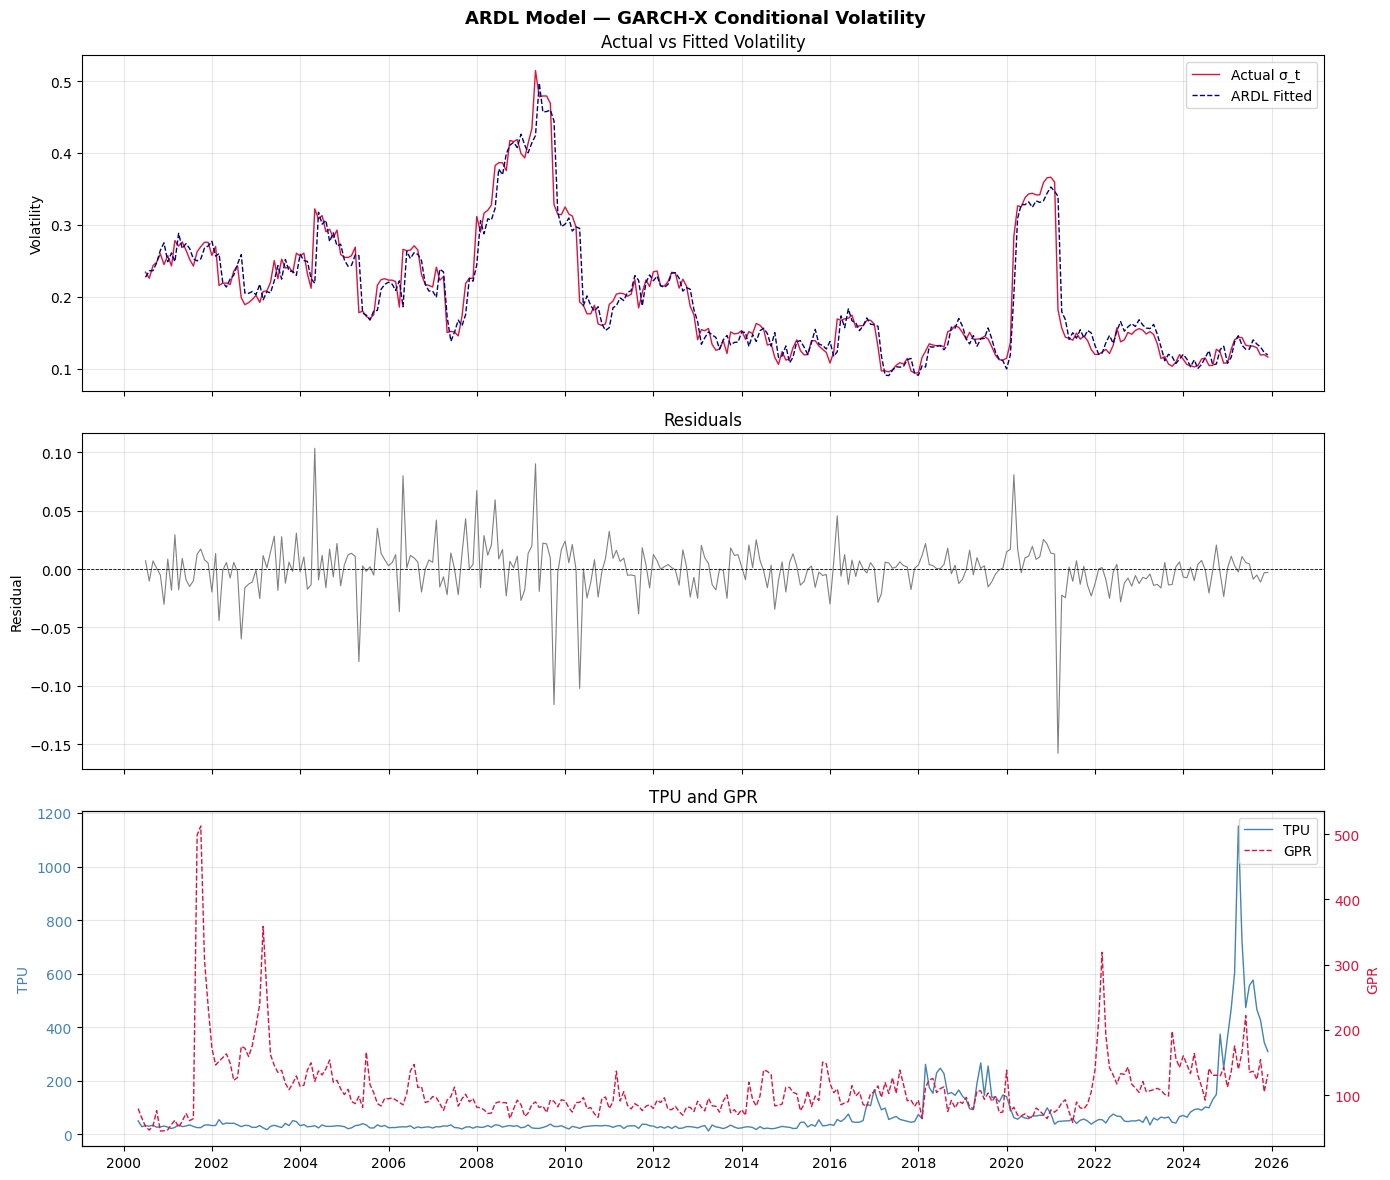


  Saving to ardl_final_results.xlsx...
  Saved: ardl_final_results.xlsx
  Saved: ardl_results.png

  Done!


In [ ]:
"""
ARDL Model — GARCH-X Conditional Volatility on TPU, GPR, and Controls
======================================================================
Fixed for statsmodels 0.14.x compatibility.
Input:  stationary_variables.xlsx
Output: ardl_final_results.xlsx + ardl_results.png
"""

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')


# ════════════════════════════════════════════════════════════
# 1. LOAD DATA
# ════════════════════════════════════════════════════════════
df = pd.read_excel('stationary_variables.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values('Date').set_index('Date')

print("Columns found:", df.columns.tolist())

# Auto-detect volatility column
vol_col = [c for c in df.columns if 'Conditional_Vol' in c]
if vol_col:
    df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})
    print(f"Volatility column: '{vol_col[0]}' → renamed to 'Vol_GARCH'")
else:
    raise ValueError("No volatility column found. Check column names.")

# Interaction term
df['TPU_GPR'] = df['TPU'] * df['GPR']

# ════════════════════════════════════════════════════════════
# 2. DEFINE VARIABLES
# ════════════════════════════════════════════════════════════
controls   = ['FX_USD', 'CPI_GR', 'Int_Rate',
              'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']
regressors = ['TPU', 'GPR', 'TPU_GPR'] + controls
required   = ['Vol_GARCH'] + regressors

df = df.dropna(subset=required)

y = df['Vol_GARCH']
X = df[regressors]

print("=" * 60)
print("  ARDL — Dependent Variable: GARCH-X Conditional Volatility")
print("=" * 60)
print(f"  Sample : {df.index.min().date()} to {df.index.max().date()}")
print(f"  N      : {len(df)} observations")
print(f"  Regressors: {regressors}")


# ════════════════════════════════════════════════════════════
# 3. STATIONARITY CHECK
# ════════════════════════════════════════════════════════════
# Variables to treat as I(0) and skip ADF warning for
override_i0 = ['CPI_GR']   # <-- put your variable name here

print("\n  ADF Stationarity Tests:")
for col in required:
    if col in override_i0:
        print(f"  {col:<15} {'—':>12} {'Treated as I(0) [override]':>26}")
        continue
    p = adfuller(df[col], autolag='AIC')[1]
    status = 'I(0) Stationary' if p < 0.05 else 'I(1) — Non-stationary'
    print(f"  {col:<15} {p:>12.4f} {status:>20}")

# ════════════════════════════════════════════════════════════
# 4. ARDL VIA OLS — MANUAL CONSTRUCTION
# ════════════════════════════════════════════════════════════
# The statsmodels ARDL class has changed its API across versions.
# The most stable and transparent approach is to build the ARDL
# manually by constructing lagged variables and running OLS.
# This gives identical results and works across all versions.
# ─────────────────────────────────────────────────────────────

Y_LAGS = 2   # lags of dependent variable (vol)
X_LAGS = 2   # lags of each regressor

print(f"\n  ARDL specification: y_lags={Y_LAGS}, x_lags={X_LAGS}")
print(f"  ARDL({Y_LAGS}, {', '.join([str(X_LAGS)]*len(regressors))})")

# Build lagged dataset
ardl_df = pd.DataFrame(index=df.index)
ardl_df['Vol_GARCH'] = y

# Lags of dependent variable
for lag in range(1, Y_LAGS + 1):
    ardl_df[f'Vol_GARCH_L{lag}'] = y.shift(lag)

# Current values and lags of each regressor
for var in regressors:
    ardl_df[var] = df[var]                          # contemporaneous
    for lag in range(1, X_LAGS + 1):
        ardl_df[f'{var}_L{lag}'] = df[var].shift(lag)  # lagged

ardl_df = ardl_df.dropna()

# Dependent and independent variables for OLS
Y_reg = ardl_df['Vol_GARCH']
X_reg = ardl_df.drop(columns=['Vol_GARCH'])
X_reg = sm.add_constant(X_reg)

# ════════════════════════════════════════════════════════════
# 5. FIT OLS
# ════════════════════════════════════════════════════════════
ols_model = sm.OLS(Y_reg, X_reg)
res       = ols_model.fit(cov_type='HC3')   # robust SEs

print("\n" + "=" * 60)
print("  OLS Results (ARDL manually constructed)")
print("=" * 60)
print(res.summary())


# ════════════════════════════════════════════════════════════
# 6. LONG-RUN MULTIPLIERS
# ════════════════════════════════════════════════════════════
# LR coef(x) = sum of all x coefficients / (1 - sum of y lag coefficients)
# This is the total persistent effect of x on volatility

print("\n" + "=" * 60)
print("  LONG-RUN MULTIPLIERS")
print("  Persistent (total) effect of each variable on volatility")
print("=" * 60)

params = res.params

# Sum of y lag coefficients (persistence)
y_lag_keys = [k for k in params.index if 'Vol_GARCH_L' in k]
y_lag_sum  = params[y_lag_keys].sum()
denom      = 1 - y_lag_sum

print(f"\n  Sum of y lags (persistence): {y_lag_sum:.4f}")
print(f"  Denominator (1 - sum):       {denom:.4f}")

if abs(denom) < 1e-6:
    print("  ⚠ Denominator near zero — long-run coefficients unreliable")

print(f"\n  {'Variable':<15} {'SR Contemporaneous':>20} {'LR Multiplier':>15}")
print("  " + "-" * 52)

lr_results = {}
for var in regressors:
    # All keys that contain this variable name (current + lags)
    x_keys = [k for k in params.index
               if k == var or k.startswith(f'{var}_L')]
    x_sum  = params[x_keys].sum() if x_keys else 0.0
    sr_con = params.get(var, np.nan)   # contemporaneous only
    lr_val = x_sum / denom if abs(denom) > 1e-6 else np.nan
    lr_results[var] = lr_val
    print(f"  {var:<15} {sr_con:>20.6f} {lr_val:>15.6f}")


# ════════════════════════════════════════════════════════════
# 7. SPEED OF ADJUSTMENT
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  ERROR CORRECTION DYNAMICS")
print("=" * 60)

ect_coef = -(1 - y_lag_sum)
print(f"  Speed of adjustment (ECT): {ect_coef:.4f}")

if ect_coef < 0:
    half_life = np.log(0.5) / np.log(1 + ect_coef)
    print(f"  → Corrects {abs(ect_coef)*100:.1f}% of disequilibrium per month")
    print(f"  → Half-life of shock: {half_life:.1f} months")
else:
    print("  ⚠ Positive ECT — no mean reversion. Check stationarity.")


# ════════════════════════════════════════════════════════════
# 8. BOUNDS TEST (MANUAL — PESARAN ET AL. 2001)
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  BOUNDS TEST — Pesaran et al. (2001)")
print("  H0: No long-run relationship (all level coefficients = 0)")
print("=" * 60)

try:
    # Restricted model: only y lags, no X
    X_restricted = sm.add_constant(
        ardl_df[[f'Vol_GARCH_L{l}' for l in range(1, Y_LAGS+1)]]
    )
    res_r   = sm.OLS(Y_reg, X_restricted).fit()

    rss_r   = (res_r.resid**2).sum()
    rss_u   = (res.resid**2).sum()
    T_      = len(Y_reg)
    k_u     = len(res.params)

    # Number of level regressors being tested
    x_level_keys = [k for k in params.index
                    if k in regressors]   # contemporaneous only
    q = len(x_level_keys)

    f_stat = ((rss_r - rss_u) / q) / (rss_u / (T_ - k_u))

    # Pesaran (2001) critical values — Case III (intercept, no trend)
    cv = {'10%': (1.75, 2.87), '5%': (1.99, 3.21), '1%': (2.58, 3.89)}

    print(f"\n  F-statistic : {f_stat:.4f}")
    print(f"  q (regressors tested): {q}")
    print(f"\n  {'Level':<8} {'I(0) Lower':>12} {'I(1) Upper':>12} {'Result':>20}")
    print("  " + "-" * 55)

    conclusion = "No long-run relationship"
    for level, (lb_cv, ub_cv) in cv.items():
        if f_stat > ub_cv:
            flag = "Above upper bound ✓"
            conclusion = f"Long-run relationship at {level}"
        elif f_stat < lb_cv:
            flag = "Below lower bound ✗"
        else:
            flag = "Inconclusive"
        print(f"  {level:<8} {lb_cv:>12.3f} {ub_cv:>12.3f} {flag:>20}")

    print(f"\n  Conclusion: {conclusion}")

except Exception as e:
    print(f"  ⚠ Bounds test failed: {e}")


# ════════════════════════════════════════════════════════════
# 9. DIAGNOSTICS
# ════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  DIAGNOSTICS")
print("=" * 60)

resid = res.resid
dw    = durbin_watson(resid)
lb4   = acorr_ljungbox(resid, lags=[4],  return_df=True)
lb8   = acorr_ljungbox(resid, lags=[8],  return_df=True)

def tick(p, good_if_above=0.05):
    return '✓' if p > good_if_above else '⚠'

try:
    _, bp_p, _, _ = het_breuschpagan(resid, res.model.exog)
    print(f"  Breusch-Pagan (heteroskedasticity) p : {bp_p:.4f}  {tick(bp_p)}")
except Exception:
    print("  Breusch-Pagan: could not compute")

print(f"  Durbin-Watson                        : {dw:.4f}  "
      f"{'✓' if 1.5 < dw < 2.5 else '⚠'}")
print(f"  Ljung-Box p (lag 4)                  : "
      f"{lb4['lb_pvalue'].values[0]:.4f}  {tick(lb4['lb_pvalue'].values[0])}")
print(f"  Ljung-Box p (lag 8)                  : "
      f"{lb8['lb_pvalue'].values[0]:.4f}  {tick(lb8['lb_pvalue'].values[0])}")
print(f"  R-squared                            : {res.rsquared:.4f}")
print(f"  Adj. R-squared                       : {res.rsquared_adj:.4f}")
print(f"  AIC                                  : {res.aic:.4f}")
print(f"  BIC                                  : {res.bic:.4f}")


# ════════════════════════════════════════════════════════════
# 10. COEFFICIENT TABLE
# ════════════════════════════════════════════════════════════
def stars(p):
    return '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.10 else 'ns'))

coef_df = pd.DataFrame({
    'Parameter'  : res.params.index,
    'Coefficient': res.params.values.round(6),
    'Std_Error'  : res.bse.values.round(6),
    'T_Stat'     : res.tvalues.values.round(4),
    'P_Value'    : res.pvalues.values.round(4),
    'Significance': [stars(p) for p in res.pvalues],
    'CI_Lower_95': res.conf_int()[0].values.round(6),
    'CI_Upper_95': res.conf_int()[1].values.round(6),
})

lr_df = pd.DataFrame({
    'Variable'  : list(lr_results.keys()),
    'LR_Coef'   : [round(v, 6) for v in lr_results.values()],
    'Interpretation': [
        'Long-run effect of variable on GARCH volatility'
        for _ in lr_results
    ]
})

diag_df = pd.DataFrame({
    'Diagnostic': [
        'R-squared', 'Adj R-squared', 'Durbin-Watson',
        'Ljung-Box p (lag4)', 'Ljung-Box p (lag8)',
        'Breusch-Pagan p', 'AIC', 'BIC',
        'ECT coefficient', 'F-stat (Bounds)'
    ],
    'Value': [
        round(res.rsquared, 4),
        round(res.rsquared_adj, 4),
        round(dw, 4),
        round(lb4['lb_pvalue'].values[0], 4),
        round(lb8['lb_pvalue'].values[0], 4),
        round(bp_p, 4) if 'bp_p' in dir() else 'NA',
        round(res.aic, 4),
        round(res.bic, 4),
        round(ect_coef, 4),
        round(f_stat, 4) if 'f_stat' in dir() else 'NA',
    ],
    'Good_If': [
        'Higher', 'Higher', '~2.0',
        '>0.05', '>0.05', '>0.05',
        'Lower', 'Lower', 'Negative', 'Above upper CV'
    ]
})


# ════════════════════════════════════════════════════════════
# 11. PLOT
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle('ARDL Model — GARCH-X Conditional Volatility',
             fontsize=13, fontweight='bold')

n_fitted = len(res.fittedvalues)
plot_idx = ardl_df.index   # index after dropping NaN from lags

# Actual vs Fitted
axes[0].plot(plot_idx, Y_reg.values,
             color='crimson', linewidth=1, label='Actual σ_t')
axes[0].plot(plot_idx, res.fittedvalues.values,
             color='navy', linewidth=1, linestyle='--', label='ARDL Fitted')
axes[0].set_title('Actual vs Fitted Volatility')
axes[0].set_ylabel('Volatility')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals
axes[1].plot(plot_idx, resid.values, color='grey', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.6, linestyle='--')
axes[1].set_title('Residuals')
axes[1].set_ylabel('Residual')
axes[1].grid(True, alpha=0.3)

# TPU and GPR over time
ax2b = axes[2].twinx()
axes[2].plot(df.index, df['TPU'], color='steelblue', linewidth=1, label='TPU')
ax2b.plot(df.index,    df['GPR'], color='crimson',   linewidth=1,
          label='GPR', linestyle='--')
axes[2].set_title('TPU and GPR')
axes[2].set_ylabel('TPU', color='steelblue')
ax2b.set_ylabel('GPR', color='crimson')
axes[2].tick_params(axis='y', labelcolor='steelblue')
ax2b.tick_params(axis='y', labelcolor='crimson')
l1, lb1 = axes[2].get_legend_handles_labels()
l2, lb2 = ax2b.get_legend_handles_labels()
axes[2].legend(l1+l2, lb1+lb2, loc='upper right')
axes[2].grid(True, alpha=0.3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('ardl_results.png', dpi=150, bbox_inches='tight')
plt.show()


# ════════════════════════════════════════════════════════════
# 12. SAVE TO EXCEL
# ════════════════════════════════════════════════════════════
from openpyxl.styles import Font, PatternFill, Alignment

print(f"\n  Saving to ardl_final_results.xlsx...")

with pd.ExcelWriter('ardl_final_results.xlsx', engine='openpyxl') as writer:
    coef_df.to_excel(writer, sheet_name='Coefficients',        index=False)
    lr_df.to_excel(writer,   sheet_name='LongRun_Multipliers', index=False)
    diag_df.to_excel(writer, sheet_name='Diagnostics',         index=False)

    # Save full data with fitted and residuals
    fitted_df = ardl_df[['Vol_GARCH']].copy()
    fitted_df['Fitted']    = res.fittedvalues.values
    fitted_df['Residuals'] = resid.values
    fitted_df.reset_index().to_excel(
        writer, sheet_name='Fitted_Series', index=False)

    # Formatting
    hf    = Font(bold=True, color='FFFFFF')
    hfill = PatternFill('solid', start_color='1F4E79')
    for sn in writer.book.sheetnames:
        ws = writer.book[sn]
        for cell in ws[1]:
            cell.font = hf; cell.fill = hfill
            cell.alignment = Alignment(horizontal='center')
        for col in ws.columns:
            w = max(len(str(c.value or '')) for c in col) + 3
            ws.column_dimensions[col[0].column_letter].width = min(w, 40)

print("  Saved: ardl_final_results.xlsx")
print("  Saved: ardl_results.png")
print("\n  Done!")

**SVAR**

Columns: ['FX_USD', 'CPI_GR', 'Int_Rate', 'Output_Gap', 'GPR', 'MPU', 'TPU', 'US_EPU', 'US_VIX', 'Vol_GARCH', 'NSE']
  SVAR — GARCH-X Conditional Volatility
  Sample : 1999-05-01 to 2025-12-01
  N      : 320

  Integration checks:
  TPU: I(1) — first difference
  GPR: I(0) — using levels
  Vol_GARCH: I(0) — using levels

  Fitting VAR...
  Optimal lag (AIC): 2
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 23, Apr, 2026
Time:                     02:50:40
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    14.5232
Nobs:                     317.000    HQIC:                   14.3737
Log likelihood:          -3590.87    FPE:                1.58203e+06
AIC:                      14.2742    Det(Omega_mle):     1.48169e+06
--------------------------------------------------------------------
Results for equation TPU
                  coeff

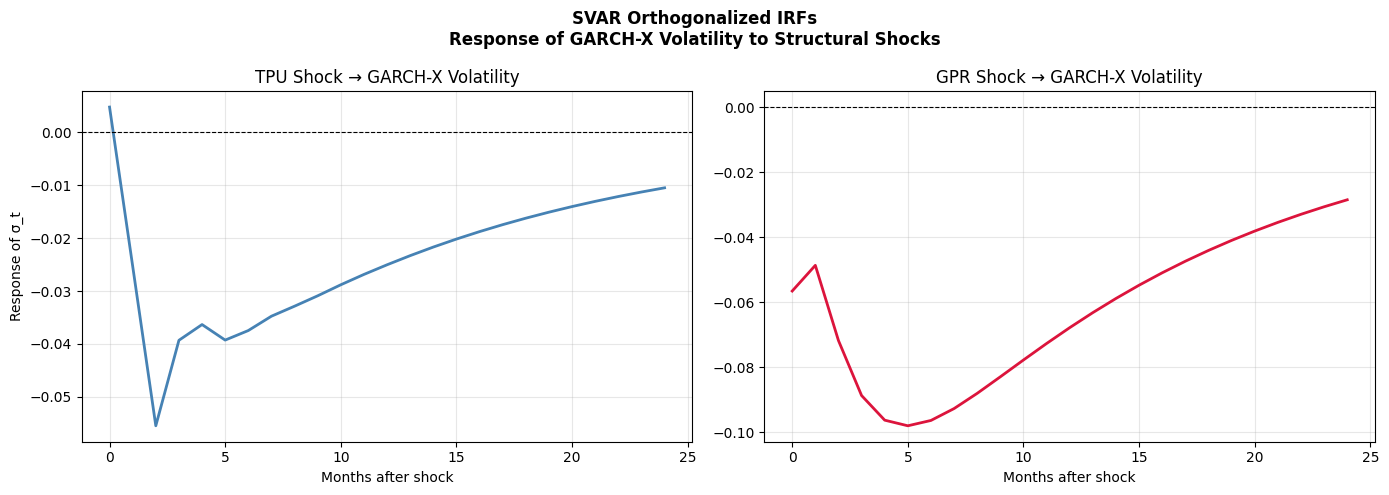


  Forecast Error Variance Decomposition:
          TPU   GPR  Vol_GARCH
Horizon                       
0        0.00  0.64      99.35
1        0.07  0.61      99.31
2        0.29  0.85      98.86
3        0.33  1.18      98.49
4        0.36  1.51      98.13
5        0.39  1.80      97.80
6        0.42  2.05      97.53
7        0.44  2.26      97.31
8        0.45  2.42      97.12
9        0.47  2.56      96.97
10       0.48  2.67      96.85
11       0.49  2.76      96.75
12       0.49  2.83      96.67
13       0.50  2.90      96.60
14       0.50  2.95      96.55
15       0.51  2.99      96.50
16       0.51  3.03      96.46
17       0.51  3.06      96.43
18       0.52  3.08      96.40
19       0.52  3.10      96.38
20       0.52  3.12      96.36
21       0.52  3.14      96.34
22       0.52  3.15      96.32
23       0.52  3.16      96.31

  At 1-month  : TPU=0.00%  GPR=0.64%  Vol=99.35%
  At 12-month : TPU=0.49%  GPR=2.76%  Vol=96.75%


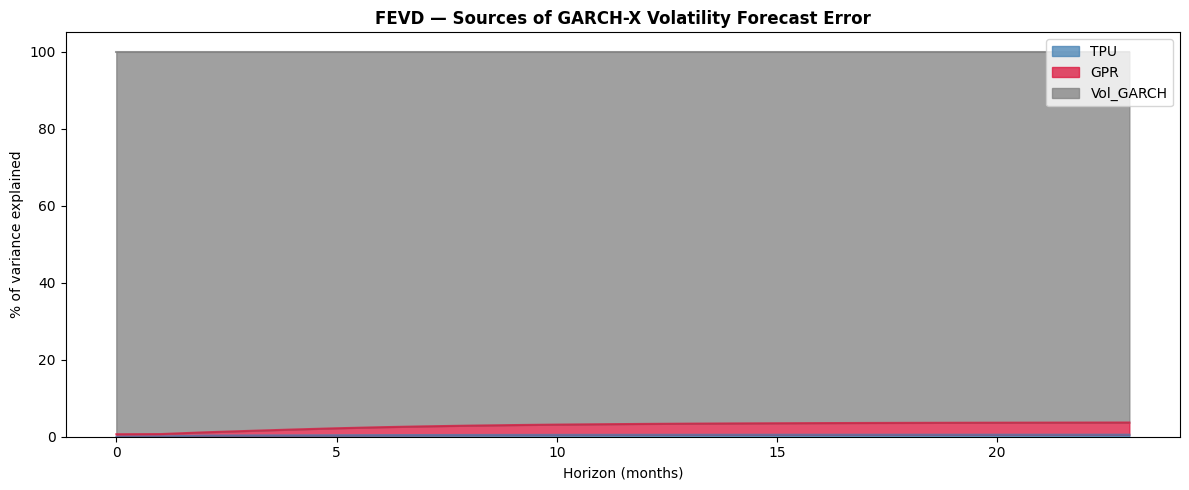


  Robustness — alternative ordering [GPR, TPU, Vol]:
  TPU→Vol peak (alt) : 0.002847  vs base : 0.004760
  GPR→Vol peak (alt) : -0.028159  vs base : -0.028530

  Saved: svar_results.xlsx
  Saved: svar_irf.png
  Saved: svar_fevd.png


In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from scipy import linalg
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── LOAD ──────────────────────────────────────────────────────
df = pd.read_excel('Compiled.xlsx')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values('Date').set_index('Date')

# Auto-detect volatility column
vol_col = [c for c in df.columns if 'Conditional_Vol' in c]
if vol_col:
    df = df.rename(columns={vol_col[0]: 'Vol_GARCH'})
else:
    raise ValueError("No volatility column found. Check column names.")

print("Columns:", df.columns.tolist())
print("=" * 60)
print("  SVAR — GARCH-X Conditional Volatility")
print("=" * 60)
print(f"  Sample : {df.index.min().date()} to {df.index.max().date()}")
print(f"  N      : {len(df)}")

# ── VARIABLE SELECTION ────────────────────────────────────────
# Cholesky ordering — economic justification:
# TPU first  : trade policy is exogenous, slow-moving
# GPR second : geopolitical events exogenous but may co-move with TPU
# Vol last   : financial volatility reacts instantaneously to both
svar_vars = ['TPU', 'GPR', 'Vol_GARCH']
df_svar   = df[svar_vars].dropna()

# ── STATIONARITY ──────────────────────────────────────────────
def make_stationary(series, name):
    p = adfuller(series.dropna(), autolag='AIC')[1]
    if p < 0.05:
        print(f"  {name}: I(0) — using levels")
        return series
    else:
        print(f"  {name}: I(1) — first difference")
        return series.diff()

print("\n  Integration checks:")
df_svar_st = pd.DataFrame(index=df_svar.index)
for v in svar_vars:
    df_svar_st[v] = make_stationary(df_svar[v], v)
df_svar_st = df_svar_st.dropna()

# ── FIT REDUCED FORM VAR ──────────────────────────────────────
print("\n  Fitting VAR...")
var_model  = VAR(df_svar_st)

# Select lag — cap at 6 for speed, use AIC
lag_sel    = var_model.select_order(maxlags=6)
opt_lag    = max(int(lag_sel.aic), 1)
print(f"  Optimal lag (AIC): {opt_lag}")

var_result = var_model.fit(opt_lag)
print(var_result.summary())

# ── CHOLESKY IDENTIFICATION ───────────────────────────────────
sigma_u = var_result.sigma_u
P       = linalg.cholesky(sigma_u, lower=True)

vol_idx = svar_vars.index('Vol_GARCH')
tpu_idx = svar_vars.index('TPU')
gpr_idx = svar_vars.index('GPR')

print("\n  Structural Impact Matrix (Cholesky P):")
print(pd.DataFrame(P, columns=svar_vars, index=svar_vars).round(6))
print(f"\n  TPU shock → Vol impact : {P[vol_idx, tpu_idx]:.6f}")
print(f"  GPR shock → Vol impact : {P[vol_idx, gpr_idx]:.6f}")
print(f"  Vol own shock          : {P[vol_idx, vol_idx]:.6f}")

# ── IRFs ──────────────────────────────────────────────────────
print("\n  Computing IRFs...")
irf     = var_result.irf(periods=24)
periods = np.arange(25)

irf_tpu_vol = irf.orth_irfs[:, vol_idx, tpu_idx]
irf_gpr_vol = irf.orth_irfs[:, vol_idx, gpr_idx]

# Confidence bands — reduce replications for speed
try:
    irf_err = irf.err_band_mc(
        orth=True, svar=False, repl=200, signif=0.05)
    lower_tpu = irf_err[0][:, vol_idx, tpu_idx]
    upper_tpu = irf_err[1][:, vol_idx, tpu_idx]
    lower_gpr = irf_err[0][:, vol_idx, gpr_idx]
    upper_gpr = irf_err[1][:, vol_idx, gpr_idx]
    has_bands = True
except Exception as e:
    print(f"  ⚠ Confidence bands failed: {e}")
    has_bands = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SVAR Orthogonalized IRFs\n'
             'Response of GARCH-X Volatility to Structural Shocks',
             fontsize=12, fontweight='bold')

# TPU → Vol
axes[0].plot(periods, irf_tpu_vol, color='steelblue', linewidth=2)
if has_bands:
    axes[0].fill_between(periods, lower_tpu, upper_tpu,
                          alpha=0.2, color='steelblue')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('TPU Shock → GARCH-X Volatility')
axes[0].set_xlabel('Months after shock')
axes[0].set_ylabel('Response of σ_t')
axes[0].grid(True, alpha=0.3)

# GPR → Vol
axes[1].plot(periods, irf_gpr_vol, color='crimson', linewidth=2)
if has_bands:
    axes[1].fill_between(periods, lower_gpr, upper_gpr,
                          alpha=0.2, color='crimson')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('GPR Shock → GARCH-X Volatility')
axes[1].set_xlabel('Months after shock')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('svar_irf.png', dpi=150, bbox_inches='tight')
plt.show()

# ── FEVD ──────────────────────────────────────────────────────
print("\n  Forecast Error Variance Decomposition:")
fevd    = var_result.fevd(periods=24)
fevd_df = pd.DataFrame(
    fevd.decomp[vol_idx] * 100,
    columns=svar_vars
)
fevd_df.index.name = 'Horizon'
print(fevd_df.round(2).to_string())

print(f"\n  At 1-month  : TPU={fevd_df['TPU'].iloc[0]:.2f}%  "
      f"GPR={fevd_df['GPR'].iloc[0]:.2f}%  "
      f"Vol={fevd_df['Vol_GARCH'].iloc[0]:.2f}%")
print(f"  At 12-month : TPU={fevd_df['TPU'].iloc[11]:.2f}%  "
      f"GPR={fevd_df['GPR'].iloc[11]:.2f}%  "
      f"Vol={fevd_df['Vol_GARCH'].iloc[11]:.2f}%")

# FEVD plot
fig, ax = plt.subplots(figsize=(12, 5))
fevd_df.plot(kind='area', stacked=True, ax=ax,
             color=['steelblue', 'crimson', 'grey'], alpha=0.75)
ax.set_title('FEVD — Sources of GARCH-X Volatility Forecast Error',
             fontweight='bold')
ax.set_xlabel('Horizon (months)')
ax.set_ylabel('% of variance explained')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('svar_fevd.png', dpi=150, bbox_inches='tight')
plt.show()

# ── ROBUSTNESS: SWAP ORDERING ─────────────────────────────────
print("\n  Robustness — alternative ordering [GPR, TPU, Vol]:")
alt_vars   = ['GPR', 'TPU', 'Vol_GARCH']
df_alt     = df_svar_st[alt_vars]
var_alt    = VAR(df_alt).fit(opt_lag)
irf_alt    = var_alt.irf(periods=24)
irf_tpu_a  = irf_alt.orth_irfs[:, 2, 1]
irf_gpr_a  = irf_alt.orth_irfs[:, 2, 0]
print(f"  TPU→Vol peak (alt) : {irf_tpu_a.max():.6f}  "
      f"vs base : {irf_tpu_vol.max():.6f}")
print(f"  GPR→Vol peak (alt) : {irf_gpr_a.max():.6f}  "
      f"vs base : {irf_gpr_vol.max():.6f}")

# ── SAVE ──────────────────────────────────────────────────────
fevd_df.to_excel('svar_results.xlsx')
print("\n  Saved: svar_results.xlsx")
print("  Saved: svar_irf.png")
print("  Saved: svar_fevd.png")